# Identificación de áreas quemadas con Prithvi

**Grupo 1** · Curso de Inteligencia Artificial · Universidad del Norte / Programa de Ingenieria de Sistemas y Computación

**Profesor:** Eduardo Enrique Zurek Varela

**Integrantes:**
1. Wilmer Santiago
2. Isabella Arrieta Juliao
3. Paula Nuñez Zarante
4. Gabriel Andres
5. Natalia Carpintero Leal
6. Ivan Parra
7. Alejandra Restrepo
8. Alan Garcia
9. Andres Serrano
10. Bryan Montoya

**Fecha de entrega:** 23 de noviembre de 2026

**Repositorio:** [Github](https://github.com/Carpinteron/Identificacion_Areas_Quemadas_Prithvi) · **Video:** [PENDIENTE: enlace]

## Declaración de contribuciones y uso de ayudas

| Integrante | Aporte principal | Secciones del cuaderno |
|---|---|---|
| Wilmer Santiago | Primera ejecución completa del cuaderno en Colab con GPU (20 escenas de entrenamiento y 10 de prueba) y los ajustes para que corriera: límite de descarga (`MAX_STREAM_MB`) y argumentos del modelo cuando la configuración no trae `model_args`. Ejecución final en Colab y verificación de cifras, con Isabella | Flujo experimental, secciones 2 a 7 |
| Isabella Arrieta Juliao | Revisión de la primera ejecución. Ejecución final en Colab y verificación de cifras, con Wilmer | Flujo experimental, secciones 2 a 7 |
| Natalia Carpintero Leal | Análisis con 20 imágenes: reproducción de la corrida en un portátil sin GPU, prueba ampliada con 20 escenas, media por escena con intervalos, controles, análisis cuantitativo de errores y curva de aprendizaje. Corridas con 40 y 60 escenas de entrenamiento y gráficas de F1, IoU, precisión y recall según el número de imágenes (de 4 a 60), con sus resultados y conclusiones. Integración de esos análisis al cuaderno; portada y repositorio | Portada, Análisis complementario (secciones A a H2), cifras de Análisis de resultados, Análisis de errores y Conclusiones |
| Paula Nuñez Zarante | Revisión de casos de acierto, falso positivo y falso negativo | Análisis de errores |
| Gabriel Caicedo | Marco teórico y referencias | Marco teórico, Referencias |
| Alejandra Restrepo | Descripción de datos, bandas, fechas y particiones | Datos y métodos |
| Alan Garcia | Formulación del problema y preguntas de la ficha | Descripción del problema, Preguntas de análisis |
| Ivan Parra | Propuesta para Colombia (contrato de entrada, etapas de validación y verificación del contrato sobre las escenas actuales) y consideraciones éticas. Línea base con índice NBR | Transferencia (incluye el extra de Colombia), Consideraciones éticas, Control 3 (NBR) |
| Andres Serrano | Organización del contenido y elaboración de las diapositivas a partir del informe | Video y presentación |
| Bryan Montoya | Edición del video e integración de las conclusiones del trabajo | Video, Conclusiones |

**Uso de herramientas de IA:** usamos un asistente de IA (Claude, de Anthropic) para organizar el reparto del trabajo, proponer borradores de texto, revisar partes del código y escribir y ejecutar el código del análisis complementario. [PENDIENTE: cada integrante agrega si usó otra herramienta y para qué.] Todo el texto fue revisado y ajustado por el grupo. Las cifras de las 10 escenas de prueba salen de la ejecución final en Colab con GPU; las de 20 escenas de prueba y de 40 y 60 de entrenamiento, del análisis local en CPU, y las referencias se verificaron en su fuente original.

**Otras ayudas:** el cuaderno base y el módulo de soporte (`prithvi_taller.py`) fueron entregados por el profesor. Los cambios que hicimos están marcados como *Ajuste del grupo*.

## Descripción del problema

Después de un incendio forestal queda una cicatriz en el terreno: vegetación consumida, ceniza y suelo descubierto. Saber dónde está y qué tamaño tiene sirve para estimar el área afectada, planear la restauración y vigilar zonas que quedan expuestas a erosión o deslizamientos en la siguiente temporada de lluvias. Delimitar esas cicatrices a mano sobre imágenes satelitales es lento, por eso vale la pena probar si un modelo lo puede hacer de forma automática.

**Pregunta orientadora:** ¿qué tan bien delimita un modelo basado en Prithvi las cicatrices de incendio presentes en imágenes satelitales?

| Elemento | En este trabajo |
|---|---|
| Entrada | Imagen HLS de 6 bandas (azul, verde, rojo, NIR, SWIR1, SWIR2), una sola fecha, recorte de 224 × 224 píxeles a 30 m (unos 6,7 × 6,7 km) |
| Salida | Máscara binaria del mismo tamaño |
| Clases | 0 = no quemado, 1 = cicatriz de incendio. El valor −1 es dato faltante y no se cuenta como fondo |
| Unidad de predicción | Bloque de 16 × 16 píxeles (480 × 480 m). La clase del bloque se copia a sus 256 píxeles para comparar con la referencia |
| Métricas principales | IoU y F1 de la clase quemada; precisión y recall como complemento |

**Lo que el modelo no hace:** no detecta fuego activo, no estima la severidad del daño, no identifica la causa del incendio ni predice la recuperación de la vegetación. Solo marca dónde la imagen se parece a una cicatriz según las etiquetas de entrenamiento.

**Hipótesis:** las representaciones que Prithvi aprendió sobre imágenes HLS deberían permitir separar cicatriz y fondo bastante mejor que una línea base constante, aunque con bordes poco precisos porque la predicción se hace por bloques.

## Marco teórico

**Modelo fundacional.** Es un modelo grande que se entrena una sola vez con muchísimos datos, casi siempre sin etiquetas, y que después se reutiliza para varias tareas distintas con pocos datos etiquetados. En vez de empezar de cero para cada problema, se aprovecha lo que el modelo ya "sabe" de las imágenes.

**Prithvi.** Es una familia de modelos fundacionales geoespaciales desarrollada por IBM y NASA [1], [2]. Nosotros usamos **Prithvi-EO-1.0-100M** (unos 100 millones de parámetros), fijado en la revisión `7b231fe5b0684e2ddd40c967fbc02e225ef77dc6` de Hugging Face [8]. Fue preentrenado con imágenes HLS de Estados Unidos en seis bandas: azul, verde, rojo, NIR, SWIR1 y SWIR2 [1]. Existe una versión más nueva, Prithvi-EO-2.0 [2], pero el cuaderno guía trabaja con la 1.0.

**Transformer, parches y atención.** Prithvi usa la arquitectura Vision Transformer (ViT) [4], [5]. La imagen se corta en parches de 16 × 16 píxeles; con 224 × 224 píxeles salen 14 × 14 = 196 parches. Cada parche se convierte en un vector (token). La atención permite que cada parche "mire" a los demás y combine información del contexto, por ejemplo, que un parche oscuro se interprete distinto si está al lado de vegetación sana o de más zonas oscuras. Según su configuración, el encoder tiene 12 capas, 12 cabezas de atención y vectores de 768 valores.

**Bandas multiespectrales.** Además del color visible, el sensor mide infrarrojo cercano (NIR) e infrarrojo de onda corta (SWIR). Estas bandas son las que más ayudan a ver vegetación sana, agua y suelo quemado (ver Preguntas de análisis).

**Preentrenamiento autosupervisado (MAE).** Prithvi se preentrenó como un *Masked Autoencoder* [3]: se tapa el 75 % de los parches de la imagen y el modelo tiene que reconstruir lo que falta. Así aprende cómo suelen verse las imágenes satelitales sin que nadie las etiquete. Pero **reconstruir no es segmentar**: para reconstruir solo tiene que adivinar valores de reflectancia, nunca se le dijo qué es una cicatriz de incendio. Por eso hace falta una cabeza entrenada con etiquetas de la clase que nos interesa.

**Inferencia, entrenamiento, fine-tuning y cabeza de predicción.**
- *Inferencia*: pasar una imagen por un modelo ya entrenado para obtener una salida, sin cambiar sus pesos.
- *Fine-tuning*: seguir entrenando el modelo fundacional (todo o parte) con datos de la tarea nueva.
- *Cabeza de predicción*: el componente pequeño que va encima del modelo y convierte sus representaciones en la respuesta de la tarea.

En este trabajo **no hicimos fine-tuning**. El encoder de Prithvi quedó congelado y solo se usó en inferencia para obtener un vector por parche. Encima entrenamos una cabeza ligera, un Random Forest [6], que decide si cada parche es quemado o no. Esto se conoce como transferencia con encoder congelado.

**Flujo del método:**

```
Imagen HLS: 6 bandas, 224 × 224 píxeles de 30 m
  → 196 parches de 16 × 16 píxeles
  → encoder Prithvi congelado (ViT de 12 capas; la atención combina información entre parches)
  → 196 vectores de 768 valores, uno por parche
  → Random Forest entrenado con la etiqueta mayoritaria de cada parche
  → mapa de 14 × 14 clases, repetido a 224 × 224 píxeles (máscara por bloques de 480 m)
```

## Datos y métodos

### Datos

Usamos el dataset **HLS Burn Scars** de IBM–NASA, publicado en Hugging Face [7]. Cada escena es un recorte de 512 × 512 píxeles del producto HLS (*Harmonized Landsat Sentinel-2*) [9], con resolución de 30 m. Las imágenes son del territorio continental de Estados Unidos entre 2018 y 2021. Según la ficha del dataset [7], son 804 escenas repartidas al azar en entrenamiento (2/3) y validación (1/3); al contarlas en el archivo comprimido obtuvimos 540 y 264. La partición es aleatoria por escena, no por evento ni por región. Las máscaras salen de los perímetros de incendios del programa MTBS (*Monitoring Trends in Burn Severity*) [15]: cada recorte de 512 × 512 se centró en la cicatriz, las imágenes se filtraron a mano por nubes y datos faltantes, y la presencia de la cicatriz se verificó a mano [7]. En todo el dataset, el 11 % de los píxeles es cicatriz, el 88 % no quemado y el 1 % sin dato. Que la referencia sea un perímetro, y no una clasificación píxel a píxel, importa para interpretar los errores (ver Análisis de errores).

- **Bandas (en este orden):** azul (B02), verde (B03), rojo (B04), NIR estrecho (B8A), SWIR1 (B11), SWIR2 (B12).
- **Escala:** reflectancia de superficie. En nuestro subconjunto de entrenamiento la media por banda va de 0,06 (azul) a 0,24 (SWIR1).
- **Etiquetas:** 1 = cicatriz de incendio, 0 = no quemado, −1 = sin dato. Los −1 se excluyen de todas las métricas.
- **Partición:** el dataset trae entrenamiento y validación. Usamos su validación como conjunto de prueba y no tomamos ninguna decisión con ella.
- **Subconjunto:** las primeras 20 escenas de entrenamiento y las primeras 10 de validación en el orden en que aparecen en el archivo comprimido. No se escogieron por su resultado. Nombres y hashes quedan en `manifest.json`.
- **Sensor:** las 30 escenas son HLS S30 (derivadas de Sentinel-2), versión 1.4.

Escenas de prueba (la fecha sale del nombre del archivo, formato año + día del año; la zona UTM da la franja de longitud):

| Escena | Tile | Fecha de la imagen | Zona UTM (longitud) |
|---|---|---|---|
| 0 | T10TGK | 11 oct 2020 | 10 (126°O–120°O) |
| 1 | T10TGL | 3 ago 2018 | 10 (126°O–120°O) |
| 2 | T11TQG | 9 ago 2018 | 11 (120°O–114°O) |
| 3 | T12SUJ | 4 nov 2019 | 12 (114°O–108°O) |
| 4 | T14RNV | 3 ago 2018 | 14 (102°O–96°O) |
| 5 | T14SKF | 3 sep 2019 | 14 (102°O–96°O) |
| 6 | T15TVN | 20 may 2019 | 15 (96°O–90°O) |
| 7 | T16REV | 15 may 2019 | 16 (90°O–84°O) |
| 8 | T16SDC | 8 abr 2018 | 16 (90°O–84°O) |
| 9 | T18SVJ | 10 may 2020 | 18 (78°O–72°O) |

En entrenamiento, 14 de las 20 escenas están en las zonas 10 a 13 (oeste) y 6 en las zonas 14 a 17 (centro y este).

**Distribución de clases.** Entrenamiento: 3.920 parches válidos, 2.445 no quemados y 1.475 quemados (37,6 % quemado). Prueba: 501.760 píxeles válidos, 386.046 no quemados y 115.714 quemados (23,1 % quemado). Ningún píxel de prueba tiene −1. La celda de métricas por escena (después de la sección 8) muestra esta distribución en un gráfico.

### Métodos

1. **Lectura y recorte.** Se verifica que imagen y máscara tengan la misma georreferencia. Se toma el recorte central de 224 × 224 en ambas. Las etiquetas nunca se remuestrean.
2. **Normalización.** Media y desviación por banda calculadas solo con las imágenes de entrenamiento y aplicadas igual a prueba. No es la normalización original del preentrenamiento de Prithvi; lo tratamos como una limitación.
3. **Extracción de características.** Cada imagen pasa por el encoder congelado y sale un vector de 768 valores por parche (14 × 14 por escena).
4. **Etiqueta por parche.** Cada bloque de 16 × 16 toma la clase mayoritaria si al menos la mitad de sus píxeles son válidos.
5. **Cabeza.** Random Forest con 80 árboles, profundidad máxima 10, pesos balanceados por clase y semilla 42, entrenado con los 3.920 parches. Estos valores vienen del cuaderno guía; no los ajustamos.
6. **Predicción.** La clase de cada parche se copia a sus 256 píxeles y se compara píxel a píxel con la máscara original.
7. **Línea base.** Predice siempre la clase más frecuente en los píxeles de entrenamiento, que resultó ser 0 (no quemado). No se usó la prueba para calcularla.
8. **Métricas.** IoU, F1, precisión y recall de la clase quemada, sobre las mismas posiciones válidas para modelo y línea base. Reportamos dos agregaciones: global (sumando las matrices de confusión de las 10 escenas) y media por escena, que es la convención que pide el enunciado.

**Entorno.** Google Colab con GPU (`cuda`), Python 3.13, torch 2.14.1+cu130, torchvision 0.29.1+cu130, timm 0.9.2, numpy 2.4.6, scikit-learn 1.6.1 y rasterio 1.5.2. La celda que carga el modelo imprime estas versiones y quedan en `resultados/procedencia.json`. El análisis complementario se verificó además en un portátil sin GPU (Windows 11, Python 3.13, torch 2.7.1 en CPU, timm 0.9.2, numpy 2.2.6, scikit-learn 1.7.0, rasterio 1.5.2): seleccionó exactamente las mismas escenas y dio las mismas métricas agregadas con diferencias de a lo sumo 0,004; por escena hay diferencias algo mayores (hasta 0,02 de F1 en la escena 1). Todas las cifras sobre las 10 escenas de prueba que citamos salen de la ejecución final en Colab.

## Flujo experimental (cuaderno guía): Prithvi congelado + clasificador ligero
**Curso:** Inteligencia Artificial · **Profesor:** Eduardo Zurek.

**Nota del grupo:** las celdas de código y la descripción del enfoque vienen del cuaderno guía del profesor. El grupo ejecutó el flujo completo en Google Colab con GPU; la procedencia queda en `resultados/procedencia.json`.

Este cuaderno descarga **datos reales** en Colab. No incluye escenas reales dentro de su archivo. El único ejemplo artificial se limita al test de las métricas y no se utiliza como dato de entrenamiento/evaluación del experimento.

**Enfoque:** Prithvi-EO-1.0-100M extrae representaciones sin modificar sus pesos; un Random Forest aprende una etiqueta mayoritaria por parche 16×16 con datos de entrenamiento. La salida es una máscara **gruesa**, no un decoder de segmentación de alta resolución.

**Recursos:** Colab gratuito; GPU opcional; modelo de varios cientos de MB. Lotes de una imagen. Descargas de archivos comprimidos pueden transferir cientos de MB incluso al seleccionar pocos ejemplos. No se garantiza que el límite de descarga permita completar todos los subconjuntos.

In [1]:
%pip -q install "timm==0.9.2" "huggingface_hub>=0.25,<1" "rasterio>=1.3,<2" "PyYAML>=6,<7" "einops>=0.7,<1" "h5py>=3,<4" "scikit-learn>=1.3,<2" requests pandas matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.22.1 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Módulo de soporte incluido
Esta celda escribe el módulo que acompaña al paquete. El notebook es autónomo: no necesita buscar o subir un archivo `.py` adicional. El código remoto del modelo oficial se fija a una revisión y se importa más adelante.


In [2]:
from pathlib import Path
MODULE_TEXT = '"""Soporte docente experimental para Prithvi. No incluye pesos ni escenas reales.\nLas descargas se realizan en Colab. No validado de extremo a extremo.\n"""\nfrom pathlib import Path\nimport json, re, hashlib, tarfile, shutil, warnings, io, time\nimport numpy as np\nimport requests\n\nSOURCES = {\n \'inundaciones\': \'https://github.com/cloudtostreet/Sen1Floods11\',\n \'quemadas\': \'https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars\',\n \'cultivos\': \'https://huggingface.co/datasets/ibm-nasa-geospatial/multi-temporal-crop-classification\',\n \'deslizamientos\': \'https://huggingface.co/datasets/sasmit545/Landslide4sense\',\n}\n\ndef save_json(path, data):\n    Path(path).write_text(json.dumps(data, indent=2, ensure_ascii=False))\n\ndef sha256(path):\n    h=hashlib.sha256()\n    with open(path,\'rb\') as f:\n        for b in iter(lambda:f.read(1048576),b\'\'): h.update(b)\n    return h.hexdigest()\n\ndef get(url,path,max_mb=250):\n    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)\n    if path.exists() and path.stat().st_size>0:return path\n    temp=path.with_suffix(path.suffix+\'.part\')\n    try:\n        with requests.get(url,stream=True,timeout=(30,120)) as r:\n            r.raise_for_status(); size=0\n            with open(temp,\'wb\') as f:\n                for b in r.iter_content(1024*1024):\n                    size+=len(b)\n                    if size>max_mb*1024**2:raise RuntimeError(\'Descarga supera el límite por archivo.\')\n                    f.write(b)\n        temp.replace(path)\n    finally:\n        if temp.exists():temp.unlink()\n    return path\n\ndef sample_key(path):\n    stem=Path(path).name.lower()\n    for suffix in [\'.tiff\',\'.tif\',\'.h5\',\'.hdf5\']:\n        if stem.endswith(suffix):stem=stem[:-len(suffix)]\n    for token in [\'_merged\',\'.mask\',\'_mask\',\'_label\',\'_s2hand\',\'_labelhand\']:\n        stem=stem.replace(token,\'\')\n    return stem\n\ndef pair_tifs(directory):\n    files=sorted(Path(directory).rglob(\'*.tif\'))\n    labels={sample_key(f):f for f in files if any(s in f.name.lower() for s in [\'mask\',\'label\'])}\n    return [(f,labels[sample_key(f)]) for f in files\n            if not any(s in f.name.lower() for s in [\'mask\',\'label\']) and sample_key(f) in labels]\n\nclass LimitedReader:\n    def __init__(self, raw, max_bytes):self.raw=raw; self.maximum=max_bytes; self.total=0\n    def read(self,size=-1):\n        b=self.raw.read(size); self.total+=len(b)\n        if self.total>self.maximum:\n            raise RuntimeError(\'El tar excede el presupuesto de red. No se completó el subconjunto. Aumentar max_stream_mb solo tras revisar tamaño y conexión; no hay garantía de descarga pequeña.\')\n        return b\n\ndef subset_archive(url, root, requested, combined=False, max_stream_mb=512):\n    """Extrae pares sin descomprimir rutas del tar. Conserva pocos archivos.\n    Leer gzip es secuencial: puede transferir mucho aunque se guarde poco.\n    """\n    root=Path(root); root.mkdir(parents=True,exist_ok=True)\n    targets={\'train\':requested[0],\'test\':requested[1]} if combined else requested\n    kept={s:{\'image\':set(),\'label\':set()} for s in targets}\n    with requests.get(url,stream=True,timeout=(30,120)) as response:\n        response.raise_for_status(); response.raw.decode_content=True\n        counter=LimitedReader(response.raw,int(max_stream_mb*1024**2))\n        with tarfile.open(fileobj=counter,mode=\'r|gz\') as tar:\n            for member in tar:\n                if not member.isfile() or not member.name.lower().endswith((\'.tif\',\'.tiff\')):continue\n                low=member.name.lower()\n                if combined:\n                    if re.search(r\'(^|[/_])(?:training|train)([/_]|$)\',low): split=\'train\'\n                    elif re.search(r\'(^|[/_])(?:validation|valid|val|test)([/_]|$)\',low): split=\'test\'\n                    else:continue\n                else:split=next(iter(targets))\n                target=targets[split]\n                if len(pair_tifs(root/split))>=target:continue\n                kind=\'label\' if any(t in Path(low).name for t in [\'mask\',\'label\']) else \'image\'\n                key=sample_key(low)\n                other=\'image\' if kind==\'label\' else \'label\'\n                # Guardado acotado; si se listan antes imágenes que máscaras,\n                # conservar hasta 4*n para permitir el emparejamiento.\n                if key not in kept[split][other] and len(kept[split][kind])>=4*target:continue\n                dest=root/split/Path(member.name).name; dest.parent.mkdir(exist_ok=True)\n                stream=tar.extractfile(member)\n                with open(dest,\'wb\') as out:shutil.copyfileobj(stream,out)\n                kept[split][kind].add(key)\n                if all(len(pair_tifs(root/s))>=n for s,n in targets.items()):break\n        print(\'Bytes comprimidos leídos:\',counter.total)\n    result={s:pair_tifs(root/s)[:n] for s,n in targets.items()}\n    for s,n in targets.items():\n        if len(result[s])<n:\n            raise RuntimeError(f\'Solo se emparejaron {len(result[s])}/{n} en {s}. Revisar nombres/estructura del tar; no se sustituyen datos.\')\n    return result\n\ndef download_flood(root,ntrain,ntest):\n    import pandas as pd\n    root=Path(root); base=\'https://storage.googleapis.com/sen1floods11/v1.1/\'\n    result={}\n    for split,tag,n in [(\'train\',\'train\',ntrain),(\'test\',\'test\',ntest)]:\n        csvname=f\'flood_{tag}_data.csv\'\n        alternatives=[base+\'splits/flood_handlabeled/\'+csvname,\n          \'https://raw.githubusercontent.com/cloudtostreet/Sen1Floods11/master/splits/flood_handlabeled/\'+csvname]\n        content=None\n        for url in alternatives:\n            rr=requests.get(url,timeout=60)\n            if rr.status_code==200:content=rr.text;break\n        if content is None:raise RuntimeError(\'No se pudo recuperar la partición oficial Sen1Floods11.\')\n        (root).mkdir(parents=True,exist_ok=True); (root/csvname).write_text(content)\n        ids=[]\n        for line in content.splitlines():\n            hit=re.search(r\'([A-Za-z]+_\\d+)_S[12]Hand\\.tif\',line)\n            if hit and hit.group(1) not in ids:ids.append(hit.group(1))\n        if len(ids)<n:raise RuntimeError(\'La estructura del CSV cambió: revisar antes de continuar.\')\n        rows=[]\n        for sample in ids[:n]:\n            image=get(base+\'data/flood_events/HandLabeled/S2Hand/\'+sample+\'_S2Hand.tif\',root/split/(sample+\'_S2Hand.tif\'))\n            label=get(base+\'data/flood_events/HandLabeled/LabelHand/\'+sample+\'_LabelHand.tif\',root/split/(sample+\'_LabelHand.tif\'))\n            rows.append((image,label))\n        result[split]=rows\n    return result\n\ndef download_landslide(root,ntrain,ntest):\n    from huggingface_hub import HfApi,hf_hub_download\n    repo=\'sasmit545/Landslide4sense\'; api=HfApi()\n    rev=api.dataset_info(repo).sha\n    names=api.list_repo_files(repo,repo_type=\'dataset\',revision=rev)\n    result={}\n    for split,n in [(\'train\',ntrain),(\'test\',ntest)]:\n        images=sorted([f for f in names if f.startswith(\'images/\'+split+\'/\') and f.endswith(\'.h5\')])\n        masks={re.findall(r\'\\d+\',Path(f).stem)[-1]:f for f in names\n               if f.startswith(\'annotations/\'+split+\'/\') and f.endswith(\'.h5\')}\n        rows=[]\n        for im in images:\n            idx=re.findall(r\'\\d+\',Path(im).stem)[-1]\n            if idx not in masks:continue\n            a=hf_hub_download(repo,filename=im,repo_type=\'dataset\',revision=rev,local_dir=str(root))\n            b=hf_hub_download(repo,filename=masks[idx],repo_type=\'dataset\',revision=rev,local_dir=str(root))\n            rows.append((Path(a),Path(b)))\n            if len(rows)==n:break\n        if len(rows)<n:raise RuntimeError(\'Estructura HDF5 diferente de la documentada; revisar el inventario.\')\n        result[split]=rows\n    save_json(Path(root)/\'revision_datos.json\',{\'repo\':repo,\'revision\':rev})\n    return result\n\ndef download_data(task,root,ntrain=4,ntest=2,max_stream_mb=512):\n    from huggingface_hub import HfApi,hf_hub_url\n    root=Path(root);root.mkdir(parents=True,exist_ok=True)\n    if task==\'inundaciones\': result=download_flood(root,ntrain,ntest)\n    elif task==\'deslizamientos\':result=download_landslide(root,ntrain,ntest)\n    else:\n        repo={\'quemadas\':\'ibm-nasa-geospatial/hls_burn_scars\',\n              \'cultivos\':\'ibm-nasa-geospatial/multi-temporal-crop-classification\'}[task]\n        api=HfApi();revision=api.dataset_info(repo).sha\n        files=api.list_repo_files(repo,repo_type=\'dataset\',revision=revision)\n        print(\'Inventario del dataset:\',files)\n        if task==\'quemadas\':\n            archive=next((f for f in files if f.endswith(\'hls_burn_scars.tar.gz\')),None)\n            if archive is None:raise RuntimeError(\'No se encontró el tar documentado de Burn Scars.\')\n            result=subset_archive(hf_hub_url(repo,archive,repo_type=\'dataset\',revision=revision),root,\n                                  (ntrain,ntest),combined=True,max_stream_mb=max_stream_mb)\n        else:\n            result={}\n            for split,name,n in [(\'train\',\'training_chips.tgz\',ntrain),(\'test\',\'validation_chips.tgz\',ntest)]:\n                if name not in files:raise RuntimeError(f\'Falta {name}; revisar inventario.\')\n                result.update(subset_archive(hf_hub_url(repo,name,repo_type=\'dataset\',revision=revision),root,\n                         {split:n},combined=False,max_stream_mb=max_stream_mb))\n        save_json(root/\'revision_datos.json\',{\'repo\':repo,\'revision\':revision})\n    manifest=[]\n    for split,pairs in result.items():\n        for im,lab in pairs:\n            manifest.append({\'split\':split,\'image\':str(im),\'label\':str(lab),\n                             \'image_sha256\':sha256(im),\'label_sha256\':sha256(lab)})\n    save_json(root/\'manifest.json\',{\'task\':task,\'source\':SOURCES[task],\n          \'note\':\'Subconjunto por orden, no por desempeño; train/test según proveedor. En cultivos, validation se usa como evaluación sin ajustar decisiones.\',\n          \'samples\':manifest})\n    return result\n\ndef read_sample(task, image_path, label_path, crop_layout=\'CT\',side=224):\n    """Retorna imagen C,T,H,W y etiqueta H,W. No remuestrea etiquetas.\n    Orden óptico asumido/documentado en el notebook: azul,verde,rojo,B8A,SWIR1,SWIR2.\n    """\n    import rasterio,h5py\n    if task==\'deslizamientos\':\n        with h5py.File(image_path,\'r\') as f:\n            keys=list(f.keys());key=\'img\' if \'img\' in f else \'image\' if \'image\' in f else None\n            if key is None:raise RuntimeError(f\'Clave HDF5 no reconocida: {keys}\')\n            im=np.asarray(f[key],dtype=np.float32)\n        if im.shape[-1]==14:im=im.transpose(2,0,1)\n        if im.shape[0]!=14:raise ValueError(\'Se esperaban 14 canales Landslide4Sense.\')\n        im=im[[1,2,3,8,10,11]][:,None] # B02 B03 B04 B8A B11 B12; excluye relieve\n        with h5py.File(label_path,\'r\') as f:\n            if \'mask\' not in f:raise RuntimeError(\'No existe la clave mask en la referencia.\')\n            label=np.asarray(f[\'mask\']).squeeze().astype(np.int64)\n    else:\n        with rasterio.open(image_path) as f:\n            arr=f.read(masked=True).astype(np.float32).filled(np.nan)\n            ref_crs,ref_transform=f.crs,f.transform\n        with rasterio.open(label_path) as f:\n            label=f.read(1,masked=True).astype(np.int64).filled(-1)\n            if f.crs!=ref_crs or f.transform!=ref_transform:raise ValueError(\'Imagen y etiqueta geográficamente desalineadas.\')\n        if task==\'inundaciones\':\n            if arr.shape[0]!=13:raise ValueError(\'Se esperan las 13 bandas S2Hand en orden B01..B12, incluyendo B8A.\')\n            im=arr[[1,2,3,8,11,12]][:,None]\n        elif task==\'quemadas\':\n            if arr.shape[0]!=6:raise ValueError(\'Se esperan 6 bandas HLS.\')\n            im=arr[:,None]\n        else:\n            if arr.shape[0]!=18:raise ValueError(\'Se esperan 18 canales (6 bandas × 3 fechas).\')\n            if crop_layout==\'CT\':im=arr.reshape(6,3,*arr.shape[1:])\n            elif crop_layout==\'TC\':im=arr.reshape(3,6,*arr.shape[1:]).transpose(1,0,2,3)\n            else:raise ValueError(\'crop_layout debe ser CT o TC; confirmar la documentación de la versión.\')\n            label=np.where(label==0,-1,label) # código 0 = nodata; no desplaza clases 1..13\n    if im.shape[-2:]!=label.shape:raise ValueError(\'Tamaño de etiqueta incompatible.\')\n    valid=np.isfinite(im).all(axis=(0,1)) & (im!=-9999).all(axis=(0,1))\n    label=np.where(valid,label,-1)\n    h,w=label.shape; r=max(0,(h-side)//2);c=max(0,(w-side)//2)\n    im=im[:,:,r:r+side,c:c+side];label=label[r:r+side,c:c+side]\n    ph=side-im.shape[-2];pw=side-im.shape[-1]\n    # Bordes de imágenes menores se repiten para contexto; la etiqueta de relleno es ignorada.\n    if ph or pw:\n        im=np.pad(im,((0,0),(0,0),(0,ph),(0,pw)),mode=\'edge\')\n        label=np.pad(label,((0,ph),(0,pw)),constant_values=-1)\n    return im.astype(\'float32\'),label\n\ndef train_normalization(samples):\n    # Estadísticas de entrenamiento exclusivamente, por banda y todas sus fechas.\n    vals=[np.where(y[None,None]>=0,x,np.nan).reshape(6,-1) for x,y in samples]\n    joined=np.concatenate(vals,axis=1)\n    mean=np.nanmean(joined,axis=1); std=np.nanstd(joined,axis=1)\n    if not np.isfinite(mean).all():raise ValueError(\'No hay datos válidos para normalizar.\')\n    return mean,np.maximum(std,1e-6)\n\ndef normalize(x,mean,std):\n    x=(x-mean[:,None,None,None])/std[:,None,None,None]\n    return np.nan_to_num(x,nan=0,posinf=0,neginf=0).astype(\'float32\')\n\ndef load_prithvi(root,num_frames=1):\n    import torch,yaml,sys,importlib.util\n    from huggingface_hub import HfApi,hf_hub_download\n    repo=\'ibm-nasa-geospatial/Prithvi-EO-1.0-100M\'\n    revision=\'7b231fe5b0684e2ddd40c967fbc02e225ef77dc6\'\n    names=HfApi().list_repo_files(repo,revision=revision)\n    def choose(options):\n        for f in options:\n            if f in names:return f\n        raise RuntimeError(\'No está el archivo esperado en la revisión fijada: \'+str(options))\n    py=choose([\'Prithvi.py\',\'prithvi.py\',\'prithvi_mae.py\'])\n    cf=choose([\'Prithvi_100M_config.yaml\',\'config.yaml\'])\n    wt=choose([\'Prithvi_100M.pt\'])\n    def dl(f):return Path(hf_hub_download(repo,filename=f,revision=revision,local_dir=str(root)))\n    py=dl(py); cf=dl(cf); wt=dl(wt)\n    # Ejecuta Python remoto del repositorio oficial, fijado a revisión. Revisar antes de distribuir.\n    spec=importlib.util.spec_from_file_location(\'prithvi_official\',py)\n    mod=importlib.util.module_from_spec(spec);sys.path.insert(0,str(py.parent));spec.loader.exec_module(mod)\n    klass=next((getattr(mod,n) for n in [\'MaskedAutoencoderViT\',\'PrithviMAE\'] if hasattr(mod,n)),None)\n    if klass is None:raise RuntimeError(\'Clase MAE no encontrada.\')\n    cfg=yaml.safe_load(cf.read_text());args=dict(cfg[\'model_args\']);args[\'num_frames\']=num_frames\n    model=klass(**args)\n    state=torch.load(wt,map_location=\'cpu\',weights_only=True)\n    if \'state_dict\' in state:state=state[\'state_dict\']\n    if \'model\' in state and isinstance(state[\'model\'],dict):state=state[\'model\']\n    state=dict(state)\n    for key in [\'pos_embed\',\'decoder_pos_embed\']:state.pop(key,None)\n    status=model.load_state_dict(state,strict=False)\n    if set(status.missing_keys)-{\'pos_embed\',\'decoder_pos_embed\'} or status.unexpected_keys:\n        raise RuntimeError(\'Checkpoint incompatible: \'+str(status))\n    device=\'cuda\' if torch.cuda.is_available() else \'cpu\'\n    model=model.to(device).eval()\n    for param in model.parameters():param.requires_grad=False\n    return model,device,{\'repo\':repo,\'revision\':revision,\'checkpoint\':str(wt),\'device\':device,\'num_frames\':num_frames}\n\ndef features(model,device,image):\n    import torch\n    x=torch.from_numpy(image.copy())[None].to(device)\n    torch.manual_seed(0)\n    with torch.inference_mode():\n        latent,mask,restore=model.forward_encoder(x,mask_ratio=0.)\n        tokens=latent[:,1:,:]\n        # Aunque mask_ratio=0, MAE puede permutar los parches. Recuperar orden espacial.\n        tokens=torch.gather(tokens,1,restore.unsqueeze(-1).expand(-1,-1,tokens.shape[-1]))\n    T=image.shape[1];D=tokens.shape[-1]\n    if tokens.shape[1]!=T*14*14:raise RuntimeError(\'Longitud de tokens distinta de la esperada (224, parches16).\')\n    return tokens.reshape(T,14,14,D).mean(dim=0).cpu().numpy()\n\ndef patch_labels(label,size=16,min_fraction=.5):\n    result=np.full((14,14),-1,dtype=np.int64)\n    for r in range(14):\n        for c in range(14):\n            block=label[r*size:(r+1)*size,c*size:(c+1)*size]\n            v=block[block>=0]\n            if v.size>=min_fraction*size*size:\n                classes,counts=np.unique(v,return_counts=True)\n                result[r,c]=classes[np.argmax(counts)]\n    return result\n\ndef confusion(y,pred,classes):\n    y=np.asarray(y); pred=np.asarray(pred)\n    if y.shape!=pred.shape:raise ValueError(\'Formas distintas.\')\n    valid=y>=0; a=y[valid];b=pred[valid]\n    if not valid.any():raise ValueError(\'No hay píxeles válidos.\')\n    if not np.isin(a,classes).all() or not np.isin(b,classes).all():raise ValueError(\'Clase fuera de la leyenda.\')\n    mat=np.zeros((len(classes),len(classes)),dtype=np.int64)\n    for i,c in enumerate(classes):\n        for j,d in enumerate(classes):mat[i,j]=np.count_nonzero((a==c)&(b==d))\n    return mat\n\ndef metrics(mat,classes):\n    rows=[]\n    for i,cl in enumerate(classes):\n        tp=int(mat[i,i]); fp=int(mat[:,i].sum()-tp); fn=int(mat[i,:].sum()-tp)\n        support=int(mat[i,:].sum());union=tp+fp+fn\n        iou=tp/union if union else np.nan\n        f1=2*tp/(2*tp+fp+fn) if union else np.nan\n        precision=tp/(tp+fp) if tp+fp else (0. if support else np.nan)\n        recall=tp/(tp+fn) if support else np.nan\n        rows.append({\'class\':int(cl),\'support\':support,\'iou\':iou,\'f1\':f1,\'precision\':precision,\'recall\':recall})\n    return rows\n\ndef smoke_test():\n    y=np.array([[0,0],[1,-1]]);p=np.array([[0,1],[1,0]])\n    mat=confusion(y,p,[0,1]);assert np.array_equal(mat,[[1,1],[0,1]])\n    row=metrics(mat,[0,1])[1]\n    assert np.isclose(row[\'iou\'],.5) and np.isclose(row[\'f1\'],2/3)\n    # nodata debe excluirse; nunca se cuenta como fondo.\n    assert mat.sum()==3\n    return \'Tests de métricas superados; NO prueban descarga ni inferencia.\'\n'
Path('/content/prithvi_taller.py').write_text(MODULE_TEXT, encoding='utf-8')
import sys
sys.path.insert(0,'/content')
from prithvi_taller import *
print(smoke_test())


Tests de métricas superados; NO prueban descarga ni inferencia.


## Configuración

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import RandomForestClassifier
from importlib.metadata import version
TASK='quemadas'
CLASSES=[0, 1]
ROOT=Path('/content')/('taller_'+TASK); ROOT.mkdir(exist_ok=True)
OUT=ROOT/'resultados'; OUT.mkdir(exist_ok=True)
NTRAIN=20
NTEST=10
MAX_STREAM_MB=3000 # Por archivo comprimido; no es límite total. Puede detener la descarga.
CROP_LAYOUT='CT' # Cultivos: (6 bandas,3 fechas). Confirmar con versión/lector oficial antes de piloto.
print('Tarea:',TASK,'| CPU/GPU:', 'GPU' if torch.cuda.is_available() else 'CPU')
print('Clases:',CLASSES)


Tarea: quemadas | CPU/GPU: GPU
Clases: [0, 1]


## 2. Descargar imágenes y etiquetas reales
Fuente: https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars

Los archivos se descargan a `/content/taller_quemadas/datos`. Se conserva un manifiesto con nombres, particiones y hashes. Solo se seleccionan archivos por su orden en la fuente, sin evaluar primero sus resultados.

**Leyenda:** 0: no quemado; 1: cicatriz de incendio; -1: ignorado. No es fuego activo.

Los datasets no están garantizados como globalmente independientes por evento. Se conserva la separación disponible del proveedor; deben estudiarse sus límites.

Si la descarga se detiene por presupuesto de red o por cambios de estructura, **detenga el experimento** y registre el mensaje; no invente archivos ni reemplace la práctica por los tests artificiales. El docente debe validar el acceso antes de asignar este material.


> Ajuste: Se cambió el MAX_STREAM_MB a 3000 porque `hls_burn_scars.tar.gz` pesa 2.65GB

In [4]:
pairs=download_data(TASK,ROOT/'datos',ntrain=NTRAIN,ntest=NTEST,max_stream_mb=MAX_STREAM_MB)
for split,rows in pairs.items():
    print(split,[(im.name,lab.name) for im,lab in rows])
print('Manifiesto:',ROOT/'datos'/'manifest.json')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Inventario del dataset: ['.gitattributes', 'README.md', 'hls_burn_scars.py', 'hls_burn_scars.tar.gz']
Bytes comprimidos leídos: 1873315840
train [('subsetted_512x512_HLS.S30.T10TEK.2018340.v1.4_merged.tif', 'subsetted_512x512_HLS.S30.T10TEK.2018340.v1.4.mask.tif'), ('subsetted_512x512_HLS.S30.T11SMT.2019294.v1.4_merged.tif', 'subsetted_512x512_HLS.S30.T11SMT.2019294.v1.4.mask.tif'), ('subsetted_512x512_HLS.S30.T11TKE.2018215.v1.4_merged.tif', 'subsetted_512x512_HLS.S30.T11TKE.2018215.v1.4.mask.tif'), ('subsetted_512x512_HLS.S30.T11TMF.2019312.v1.4_merged.tif', 'subsetted_512x512_HLS.S30.T11TMF.2019312.v1.4.mask.tif'), ('subsetted_512x512_HLS.S30.T11TMJ.2018217.v1.4_merged.tif', 'subsetted_512x512_HLS.S30.T11TMJ.2018217.v1.4.mask.tif'), ('subsetted_512x512_HLS.S30.T12STC.2020218.v1.4_merged.tif', 'subsetted_512x512_HLS.S30.T12STC.2020218.v1.4.mask.tif'), ('subsetted_512x512_HLS.S30.T12SUH.2020188.v1.4_merged.tif', 'subsetted_512x512_HLS.S30.T12SUH.2020188.v1.4.mask.tif'), ('subsetted_51

## 3. Leer, verificar y explorar
Se usan seis bandas ópticas equivalentes en significado: azul, verde, rojo, NIR estrecho (B8A), SWIR1 y SWIR2. No se mezclan pendiente o elevación con bandas ópticas.
- Áreas quemadas: producto HLS de seis bandas en el orden indicado por su documentación.

Cada escena produce un recorte central 224×224. Si la entrada es menor, se rellena contexto y se ignoran las etiquetas de relleno. No se remuestrean etiquetas.

Esta adaptación no equivale a los preprocesamientos de los checkpoints especializados. Las diferencias de sensor, escala y procesamiento son límites importantes del estudio.


train [((6, 1, 224, 224), (224, 224), [-1, 0, 1]), ((6, 1, 224, 224), (224, 224), [-1, 0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [-1, 0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [-1, 0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1])]
test [((6, 1, 224, 224), (224, 224), [1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 224), (224, 224), [0, 1]), ((6, 1, 224, 2

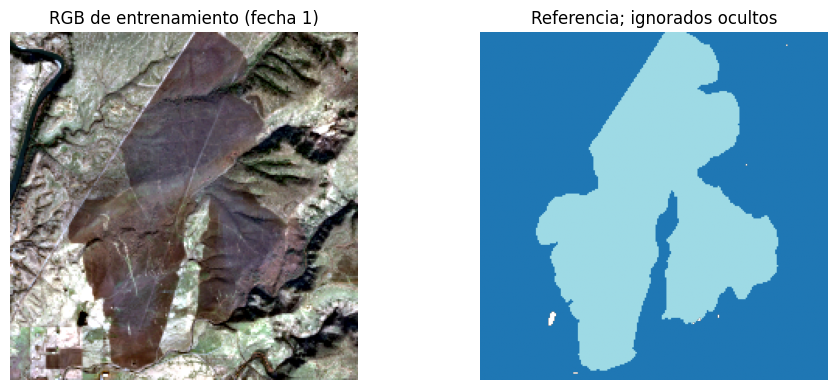

In [5]:
samples={split:[read_sample(TASK,im,lab,crop_layout=CROP_LAYOUT) for im,lab in rows]
         for split,rows in pairs.items()}
for split,rows in samples.items():
    print(split,[(x.shape,y.shape,np.unique(y).tolist()) for x,y in rows])
    for x,y in rows:
        if not np.isin(y[y>=0],CLASSES).all(): raise ValueError('Etiqueta fuera de leyenda; revisar la versión.')
x0,y0=samples['train'][0]
def display_rgb(x):
    a=x[[2,1,0],0].transpose(1,2,0).copy()
    for c in range(3):
        v=a[:,:,c];finite=np.isfinite(v)
        if not finite.any():continue
        lo,hi=np.percentile(v[finite],[2,98]); a[:,:,c]=np.clip((v-lo)/max(hi-lo,1e-6),0,1)
    return np.nan_to_num(a)
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(display_rgb(x0));ax[0].set_title('RGB de entrenamiento (fecha 1)')
ax[1].imshow(np.ma.masked_where(y0<0,y0),vmin=min(CLASSES),vmax=max(CLASSES),cmap='tab20');ax[1].set_title('Referencia; ignorados ocultos')
for a in ax:a.axis('off')
fig.tight_layout();fig.savefig(OUT/'01_exploracion.png',dpi=150);plt.show()


**Actividad:** registre canales, formas, leyenda, datos faltantes y correspondencia con la documentación. Explique qué información se pierde al usar solo el recorte central y qué podría cambiar al utilizar otras fechas o variables auxiliares.


**Respuesta del grupo.**

- **Canales y formas:** cada escena queda como un arreglo de 6 bandas × 1 fecha × 224 × 224; la etiqueta es de 224 × 224. Coincide con las seis bandas HLS descritas en la documentación del dataset.
- **Leyenda y faltantes:** aparecen los valores 0, 1 y −1. Cuatro de las 20 escenas de entrenamiento tienen píxeles −1; ninguna de prueba los tiene. La escena 0 de prueba quedó completamente quemada dentro del recorte.
- **Lo que se pierde con el recorte central:** 224 × 224 es apenas el 19 % del área de una escena de 512 × 512, así que se descarta el 81 % restante. El recorte puede partir una cicatriz o dejarla por fuera, y cambia la proporción entre quemado y no quemado. En la escena 0 eso hace que no quede nada de fondo para evaluar.
- **Otras fechas o variables:** con una imagen de antes del incendio se podría medir el cambio y no solo el estado final. Eso ayuda a distinguir una zona que siempre fue oscura (agua, roca, sombra) de una que se oscureció por el fuego. Variables como pendiente u orientación podrían ayudar con las sombras de montaña, pero Prithvi no se preentrenó con ellas.

- **Lo que muestra la figura de exploración** (escena de entrenamiento 0, T10TEK, 6 dic 2018): la cicatriz es una mancha café-morada grande, con un borde recto en un costado. La referencia es un polígono suave que sigue el perímetro: deja un corredor sin quemar entre dos lóbulos y no marca el río ni un lote rectangular oscuro abajo a la izquierda, aunque en la imagen también se ven oscuros. Es un primer ejemplo de que la oscuridad no basta para definir la clase y de que la etiqueta es un perímetro, no una clasificación píxel a píxel.

## 4. Normalización sin fuga de prueba
Se estima media y desviación por banda **solo con imágenes de entrenamiento**, usando posiciones con etiqueta válida, sin usar su clase. Estas estadísticas se aplican a ambos conjuntos. Esto no es fine-tuning ni la normalización oficial original: es una decisión de transferencia que permite trabajar con distintas escalas, y debe mencionarse como limitación.

Imputación: los valores no finitos se convierten en cero después de estandarizar. No se evalúan posiciones inválidas.


In [6]:
mean,std=train_normalization(samples['train'])
prepared={split:[(normalize(x,mean,std),y) for x,y in rows] for split,rows in samples.items()}
save_json(OUT/'normalizacion.json',{'method':'train_zscore_by_band','mean':mean.tolist(),'std':std.tolist()})
print('Media train:',mean,'| STD train:',std)


Media train: [0.05949525 0.08366273 0.10327961 0.19505522 0.24320912 0.19280952] | STD train: [0.02866969 0.03636152 0.05242738 0.0720992  0.08832543 0.08634797]


## 5. Descargar Prithvi y congelar el encoder
Se fija una revisión histórica del modelo EO-1.0-100M. Se regenera la codificación posicional fija cuando se cambia el número de fechas. Solo esas claves pueden faltar al cargar los pesos; cualquier incompatibilidad restante detiene el proceso.

El checkpoint se carga con `weights_only=True`; no habilite carga arbitraria si aparece un error. El forward del encoder no actualiza pesos. Los tokens espaciales se restauran al orden original porque MAE puede permutarlos incluso sin ocultar parches.


> **Ajuste del grupo:** el archivo de configuración de esta revisión de Prithvi no trae la llave `model_args` que espera el módulo de soporte. Las dos celdas siguientes descargan la configuración, la revisan y arman los argumentos del modelo a partir de sus llaves (`img_size`, `patch_size`, `embed_dim`, etc.), con 6 canales de entrada.

In [7]:
import yaml
from huggingface_hub import hf_hub_download
# Ajuste del grupo: se descarga la configuración antes de leerla, para que la celda funcione en un entorno nuevo.
cfg_path = hf_hub_download('ibm-nasa-geospatial/Prithvi-EO-1.0-100M', filename='Prithvi_100M_config.yaml',
                           revision='7b231fe5b0684e2ddd40c967fbc02e225ef77dc6', local_dir=str(ROOT/'modelo'))
cfg = yaml.safe_load(Path(cfg_path).read_text())
print(cfg.keys())
print(cfg)

Prithvi_100M_config.yaml:   0%|          | 0.00/541 [00:00<?, ?B/s]

dict_keys(['num_frames', 'img_size', 'bands', 'random_cropping', 'data_loader_num_workers', 'depth', 'decoder_depth', 'patch_size', 'embed_dim', 'decoder_embed_dim', 'num_heads', 'decoder_num_heads', 'mask_ratio', 'tubelet_size', 'data_mean', 'data_std', 'batch_size'])
{'num_frames': 3, 'img_size': 224, 'bands': ['B02', 'B03', 'B04', 'B05', 'B06', 'B07'], 'random_cropping': True, 'data_loader_num_workers': 1, 'depth': 12, 'decoder_depth': 8, 'patch_size': 16, 'embed_dim': 768, 'decoder_embed_dim': 512, 'num_heads': 12, 'decoder_num_heads': 16, 'mask_ratio': 0.75, 'tubelet_size': 1, 'data_mean': [775.2290211032589, 1080.992780391705, 1228.5855250417867, 2497.2022620507532, 2204.2139147975554, 1610.8324823273745], 'data_std': [1281.526139861424, 1270.0297974547493, 1399.4802505642526, 1368.3446143747644, 1291.6764008585435, 1154.505683480695], 'batch_size': 16}


In [8]:
import importlib, prithvi_taller
p = Path('/content/prithvi_taller.py')
src = p.read_text()
old = "args=dict(cfg['model_args'])"
new = ("args=dict(cfg['model_args']) if 'model_args' in cfg else "
       "{k:cfg[k] for k in ['img_size','patch_size','tubelet_size','embed_dim','depth',"
       "'num_heads','decoder_embed_dim','decoder_depth','decoder_num_heads']}; "
       "args['in_chans']=6")
assert old in src
p.write_text(src.replace(old, new))
importlib.reload(prithvi_taller)
from prithvi_taller import load_prithvi

In [9]:
T=prepared['train'][0][0].shape[1]
model,device,model_info=load_prithvi(ROOT/'modelo',num_frames=T)
provenance={'task':TASK,'model':model_info,'ntrain':NTRAIN,'ntest':NTEST,
 'classes':CLASSES,'crop_layout':CROP_LAYOUT,'crop':'center224_pad_ignore',
 'normalization':'train_zscore_by_band','head':'RandomForest, patch16 majority, frozen encoder',
 'packages':{p:version(p) for p in ['torch','torchvision','timm','numpy','scikit-learn','rasterio']}}
save_json(OUT/'procedencia.json',provenance)
print(model_info)
print('Versiones:', provenance['packages'])  # Ajuste del grupo: dejar las versiones a la vista


Prithvi.py: 0.00B [00:00, ?B/s]

Prithvi_100M.pt:   0%|          | 0.00/454M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


{'repo': 'ibm-nasa-geospatial/Prithvi-EO-1.0-100M', 'revision': '7b231fe5b0684e2ddd40c967fbc02e225ef77dc6', 'checkpoint': '/content/taller_quemadas/modelo/Prithvi_100M.pt', 'device': 'cuda', 'num_frames': 1}
Versiones: {'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'timm': '0.9.2', 'numpy': '2.4.6', 'scikit-learn': '1.6.1', 'rasterio': '1.5.2'}


## 6. Entrenar exclusivamente la cabeza ligera
Cada parche 16×16 recibe la clase mayoritaria si ≥50% de sus etiquetas son válidas. Los empates se resuelven por el primer código en orden ascendente. El Random Forest opera sobre los embeddings de Prithvi. En cultivos se promedian los tokens de las fechas **después de la atención espaciotemporal**.

No se cambia ningún peso del encoder. Se conserva el conjunto de evaluación sin usarlo para elegir hiperparámetros. Si el subconjunto de entrenamiento no contiene una clase, el clasificador no puede aprenderla; se informa el problema, no se buscan escenas para mejorar la nota.


In [10]:
train_features=[];train_targets=[]
for i,(x,y) in enumerate(prepared['train']):
    f=features(model,device,x);label=patch_labels(y)
    valid=label>=0
    train_features.append(f[valid]);train_targets.append(label[valid])
    print('Entrenamiento escena',i,'parches válidos:',valid.sum())
X=np.concatenate(train_features);Y=np.concatenate(train_targets)
if len(Y)==0:raise ValueError('No hay parches de entrenamiento válidos.')
print('Distribución de etiquetas por parche:',np.unique(Y,return_counts=True))
missing=sorted(set(CLASSES)-set(np.unique(Y)))
if missing:print('LIMITACIÓN: clases ausentes del entrenamiento:',missing)
head=RandomForestClassifier(n_estimators=80,max_depth=10,class_weight='balanced',random_state=42,n_jobs=2)
head.fit(X,Y)
# Baseline: clase de píxel más frecuente SOLO en entrenamiento.
train_labels=np.concatenate([y[y>=0] for _,y in samples['train']])
values,counts=np.unique(train_labels,return_counts=True)
majority=int(values[np.argmax(counts)])
print('Línea base constante:',majority)


Entrenamiento escena 0 parches válidos: 196
Entrenamiento escena 1 parches válidos: 196
Entrenamiento escena 2 parches válidos: 196
Entrenamiento escena 3 parches válidos: 196
Entrenamiento escena 4 parches válidos: 196
Entrenamiento escena 5 parches válidos: 196
Entrenamiento escena 6 parches válidos: 196
Entrenamiento escena 7 parches válidos: 196
Entrenamiento escena 8 parches válidos: 196
Entrenamiento escena 9 parches válidos: 196
Entrenamiento escena 10 parches válidos: 196
Entrenamiento escena 11 parches válidos: 196
Entrenamiento escena 12 parches válidos: 196
Entrenamiento escena 13 parches válidos: 196
Entrenamiento escena 14 parches válidos: 196
Entrenamiento escena 15 parches válidos: 196
Entrenamiento escena 16 parches válidos: 196
Entrenamiento escena 17 parches válidos: 196
Entrenamiento escena 18 parches válidos: 196
Entrenamiento escena 19 parches válidos: 196
Distribución de etiquetas por parche: (array([0, 1]), array([2445, 1475]))
Línea base constante: 0


## 7. Evaluar el modelo y la línea base
La clase predicha por parche se expande a 16×16 mediante repetición. Es una máscara gruesa; no implica resolución efectiva de un píxel. Se compara con la referencia original sobre posiciones válidas.

Se acumulan matrices de confusión globales por píxel; además se guardan métricas por escena. No se interpreta el conjunto de píxeles como observaciones geográficas independientes. Las clases ausentes de referencia y predicción tienen métrica no definida y se excluyen del promedio macro; las clases presentes con omisiones sí se penalizan.


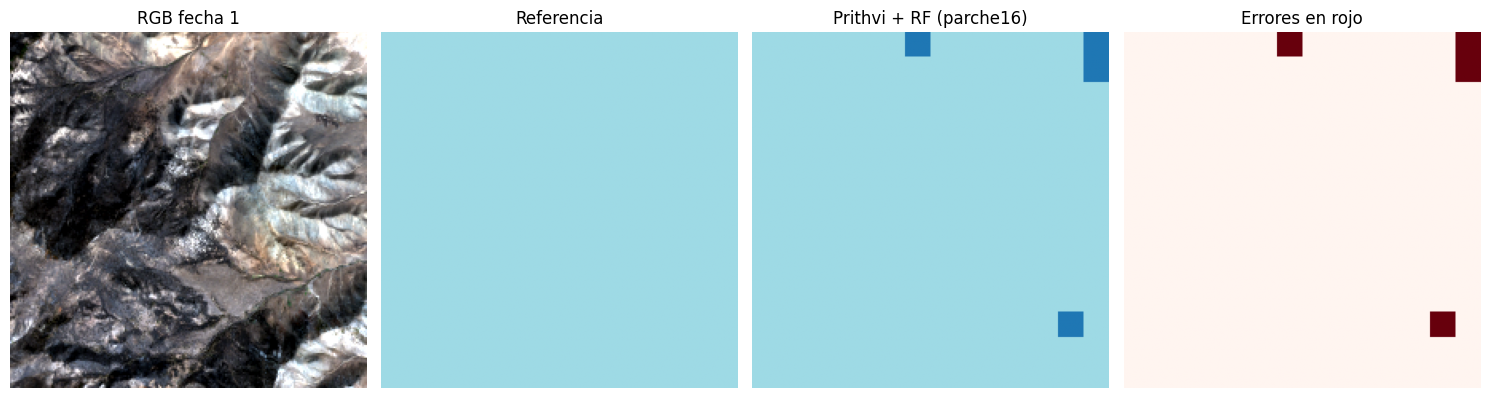

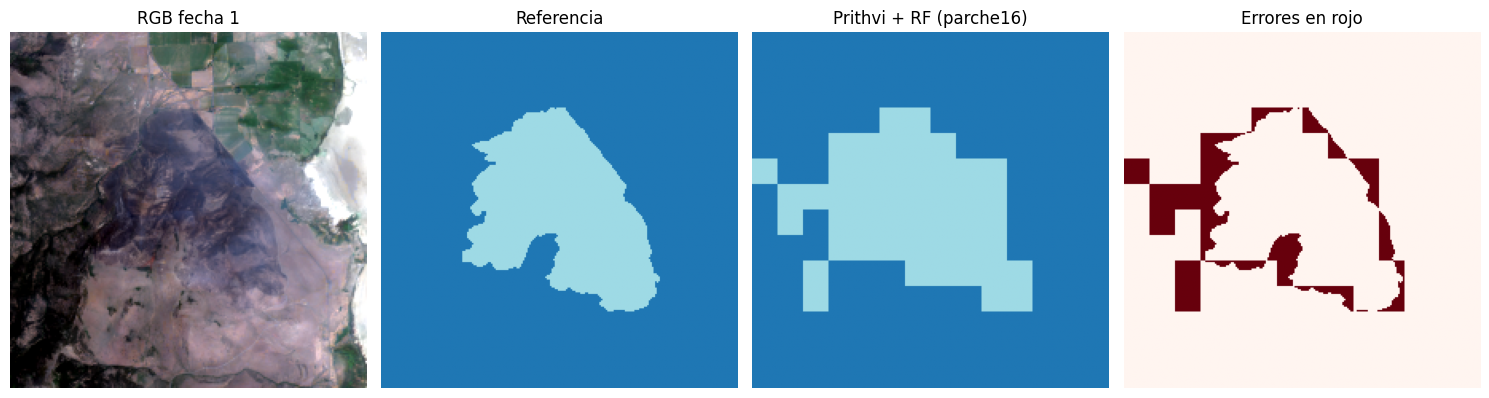

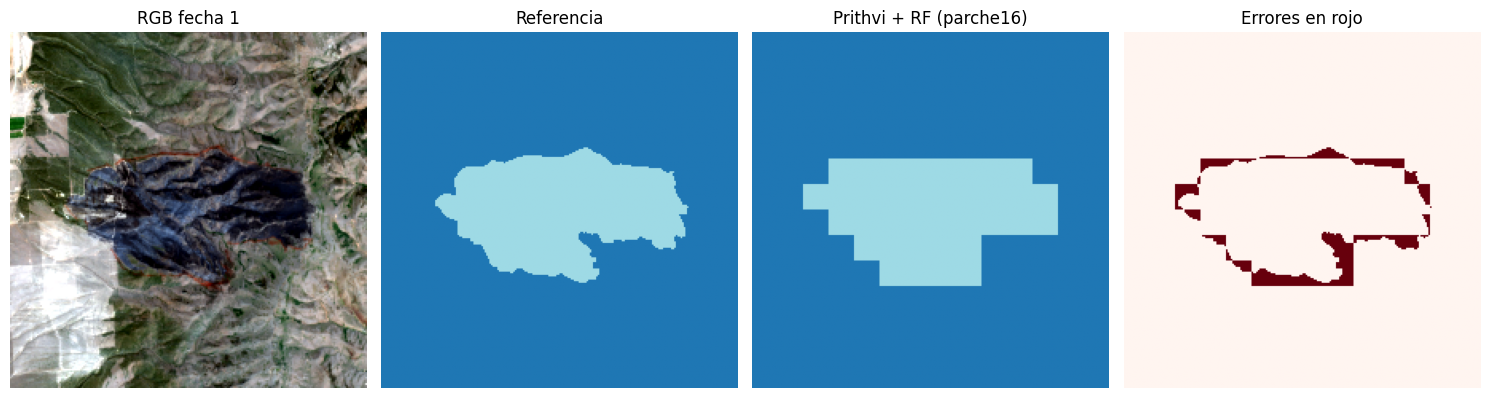

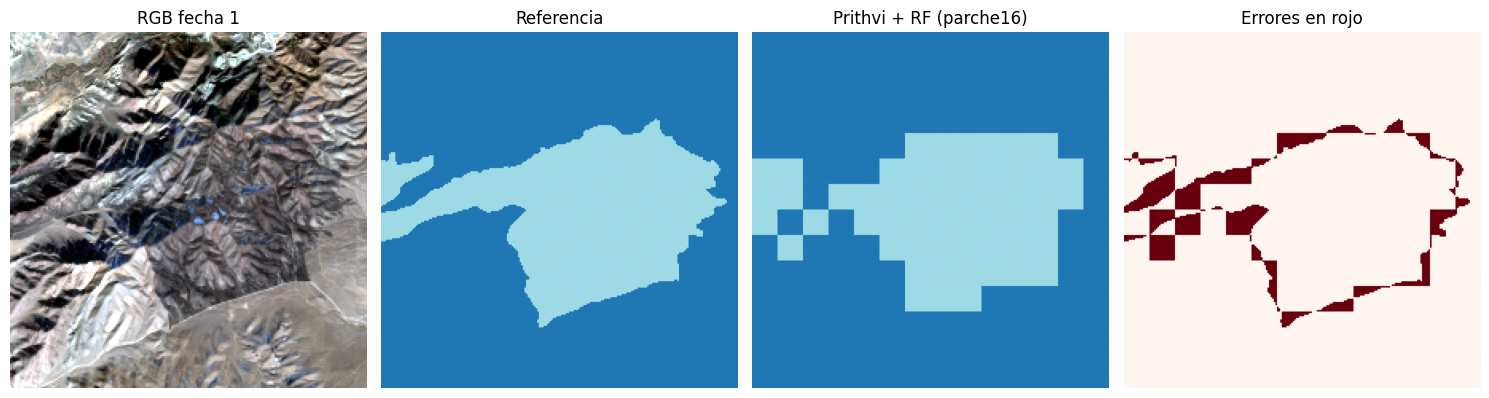

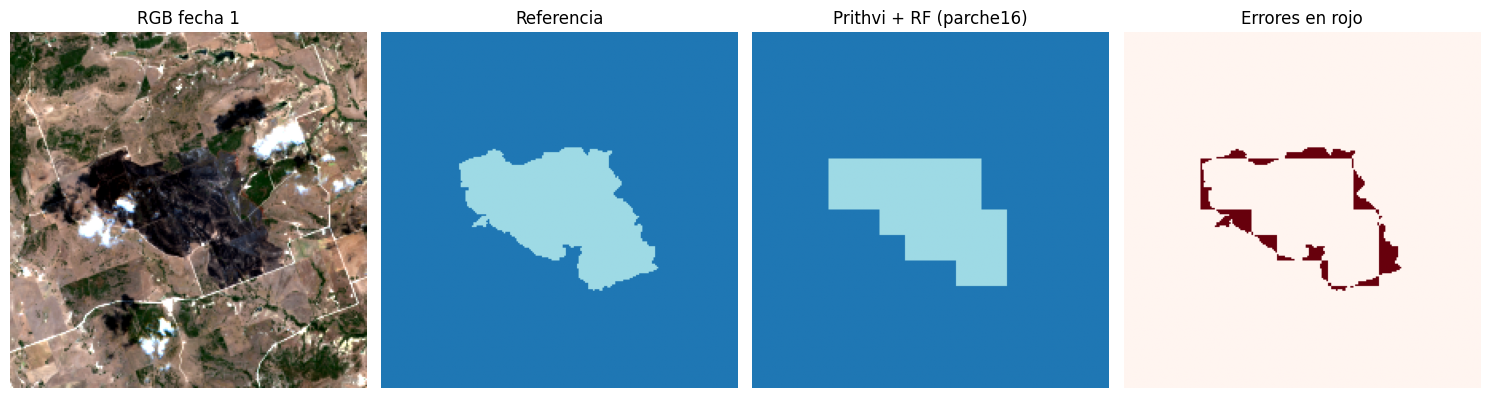

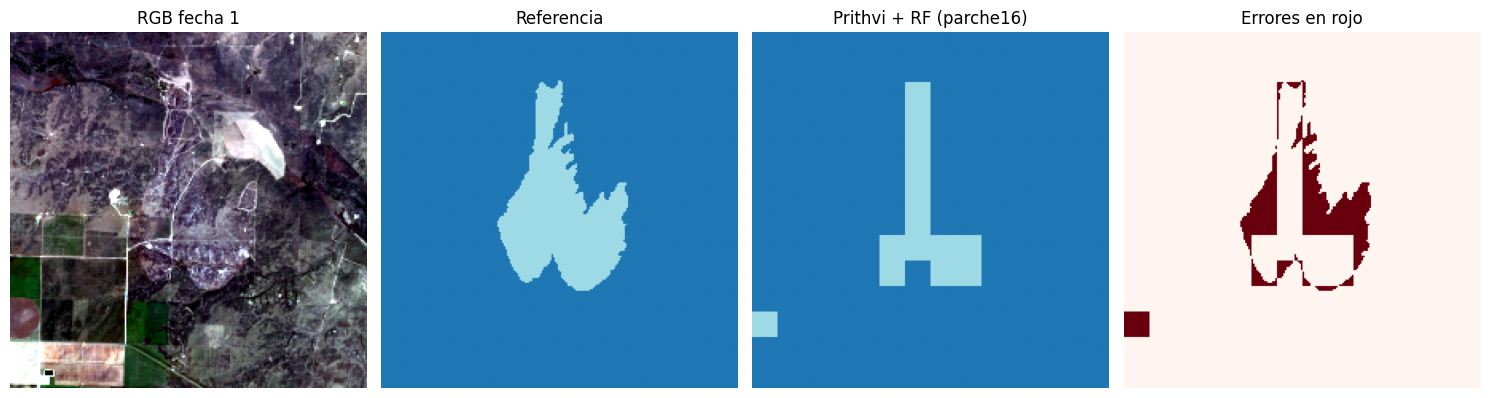

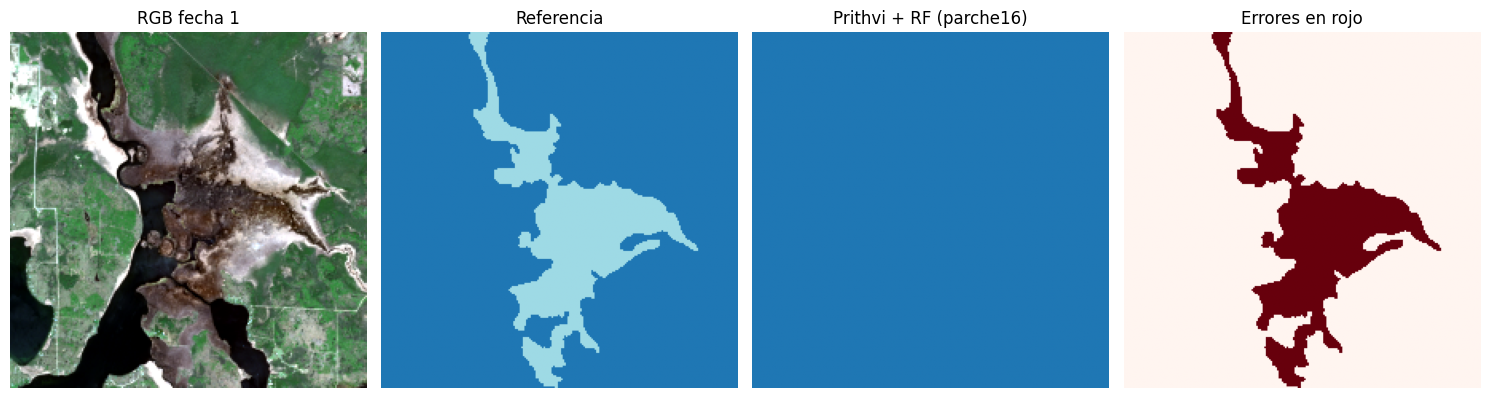

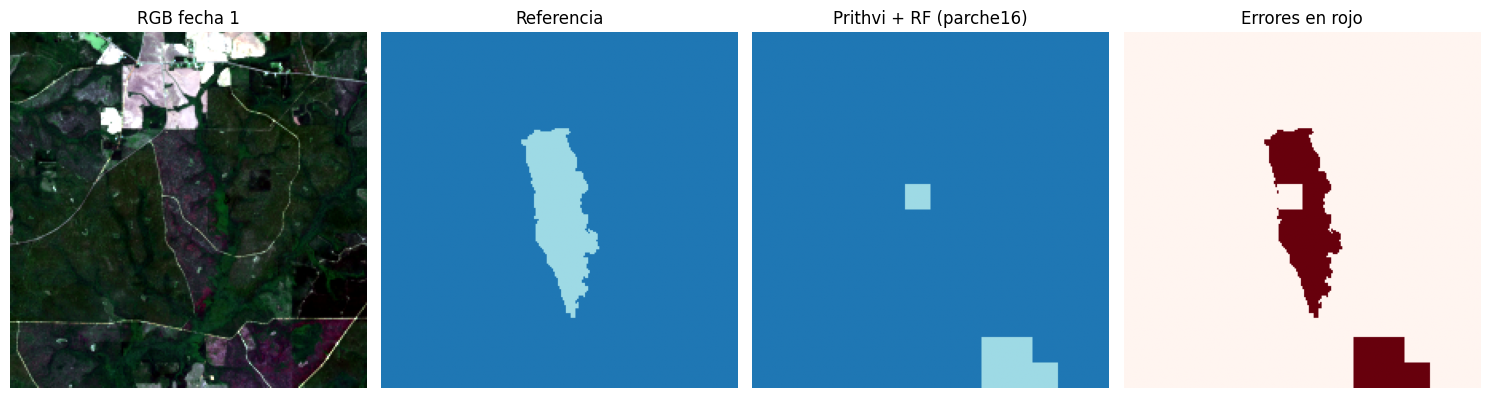

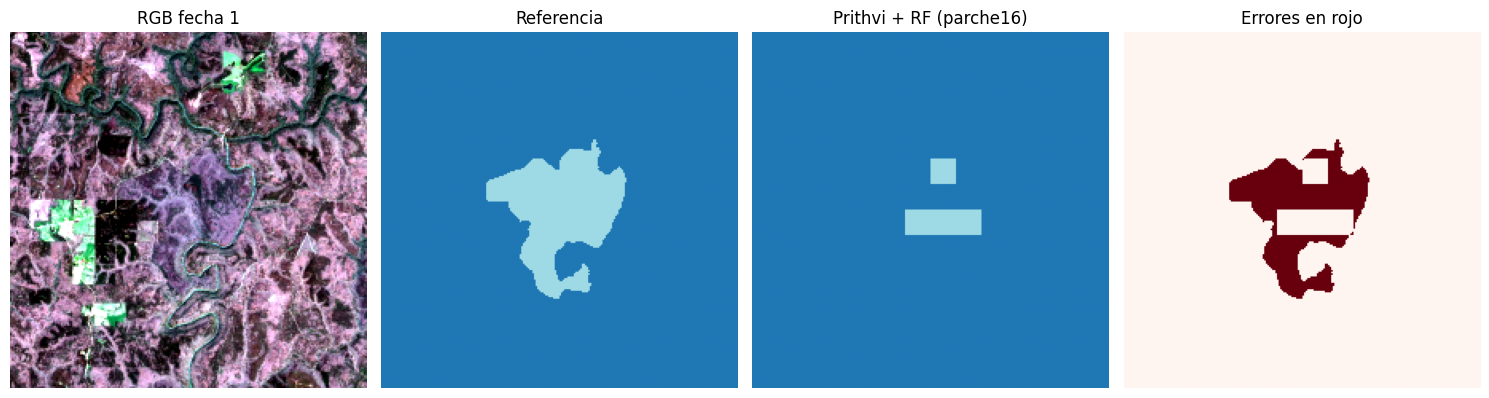

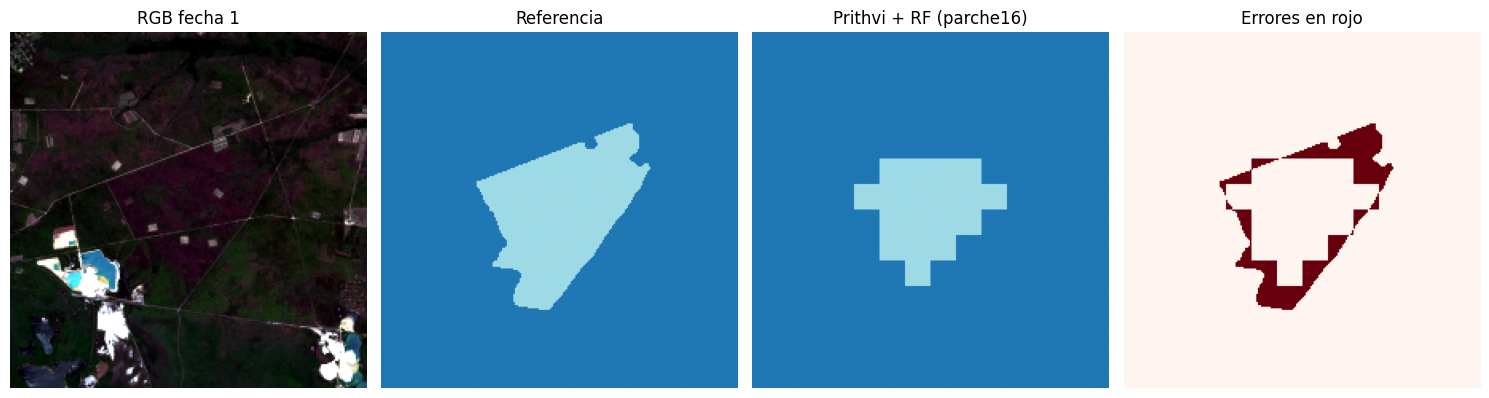

,method,f1_positive,iou_positive,precision,recall
0,prithvi_rf,0.849952,0.739057,0.910058,0.797293
1,baseline,0.000000,0.000000,0.000000,0.000000


,method,class,support,iou,f1,precision,recall
0,prithvi_rf,0,386046,0.920455,0.958580,0.941416,0.976381
1,prithvi_rf,1,115714,0.739057,0.849952,0.910058,0.797293
2,baseline,0,386046,0.769384,0.869663,0.769384,1.000000
3,baseline,1,115714,0.000000,0.000000,0.000000,0.000000


In [11]:
totals={'prithvi_rf':np.zeros((len(CLASSES),len(CLASSES)),dtype=np.int64),
        'baseline':np.zeros((len(CLASSES),len(CLASSES)),dtype=np.int64)}
scene_rows=[]
for i,((x,y),(raw,_)) in enumerate(zip(prepared['test'],samples['test'])):
    f=features(model,device,x)
    grid=head.predict(f.reshape(-1,f.shape[-1])).reshape(14,14)
    pred=np.repeat(np.repeat(grid,16,axis=0),16,axis=1)
    baseline=np.full(y.shape,majority,dtype=np.int64)
    for name,p in [('prithvi_rf',pred),('baseline',baseline)]:
        mat=confusion(y,p,CLASSES);totals[name]+=mat
        for row in metrics(mat,CLASSES):scene_rows.append({'scene':i,'method':name,**row})
    np.savez_compressed(OUT/f'escena_{i}.npz',label=y,prediction=pred,baseline=baseline)
    fig,ax=plt.subplots(1,4,figsize=(15,4))
    ax[0].imshow(display_rgb(raw));ax[0].set_title('RGB fecha 1')
    ax[1].imshow(np.ma.masked_where(y<0,y),vmin=min(CLASSES),vmax=max(CLASSES),cmap='tab20');ax[1].set_title('Referencia')
    ax[2].imshow(np.ma.masked_where(y<0,pred),vmin=min(CLASSES),vmax=max(CLASSES),cmap='tab20');ax[2].set_title('Prithvi + RF (parche16)')
    ax[3].imshow(np.ma.masked_where(y<0,(pred!=y).astype(float)),vmin=0,vmax=1,cmap='Reds');ax[3].set_title('Errores en rojo')
    for a in ax:a.axis('off')
    fig.tight_layout();fig.savefig(OUT/f'02_resultado_{i}.png',dpi=150);plt.show()
rows=[]
for name,mat in totals.items():
    for row in metrics(mat,CLASSES):rows.append({'method':name,**row})
    pd.DataFrame(mat,index=CLASSES,columns=CLASSES).to_csv(OUT/f'confusion_{name}.csv')
byclass=pd.DataFrame(rows);byclass.to_csv(OUT/'metricas_por_clase.csv',index=False)
pd.DataFrame(scene_rows).to_csv(OUT/'metricas_por_escena.csv',index=False)
summary=[]
for name in totals:
    subset=byclass[byclass.method==name]
    if TASK=='cultivos':
        summary.append({'method':name,'f1_macro':subset.f1.mean(),'miou':subset.iou.mean()})
    else:
        pos=subset[subset['class']==1].iloc[0]
        summary.append({'method':name,'f1_positive':pos.f1,'iou_positive':pos.iou,'precision':pos.precision,'recall':pos.recall})
summary=pd.DataFrame(summary);summary.to_csv(OUT/'metricas.csv',index=False)
display(summary);display(byclass)


## Análisis de resultados

**Convención principal (enunciado, §6): media por escena** de las métricas de la clase quemada. El agregado por píxel, que suma las matrices de confusión de todas las escenas, va como complemento y rotulado.

**Corrida principal (20 escenas de entrenamiento, 10 de prueba), media por escena:**

| Método | F1 quemado | IoU quemado | Precisión | Recall |
|---|---|---|---|---|
| Prithvi congelado + Random Forest | 0,639 ± 0,351 | 0,548 ± 0,339 | 0,735 ± 0,357 | 0,609 ± 0,374 |
| Línea base constante (siempre "no quemado") | 0,000 | 0,000 | 0,000 | 0,000 |

± = desviación estándar entre las 10 escenas. IC95 % por bootstrap de escenas: F1 de 0,42 a 0,83 e IoU de 0,34 a 0,74 (sección A del análisis complementario).

**Agregado por píxel (complemento):**

| Método | F1 quemado | IoU quemado | Precisión | Recall |
|---|---|---|---|---|
| Prithvi congelado + Random Forest | 0,850 | 0,739 | 0,910 | 0,797 |
| Línea base constante | 0,000 | 0,000 | 0,000 | 0,000 |

Soporte en prueba: 115.714 píxeles quemados y 386.046 no quemados.

**Lo que muestran los números:**
- El modelo supera claramente a la línea base en la clase que importa. La línea base acierta el 76,9 % de los píxeles solo por decir siempre "no quemado", pero no encuentra ni un píxel quemado. Por eso la exactitud no sirve para juzgar esta tarea.
- La media por escena (F1 0,64) queda muy por debajo del agregado (0,85). La escena 0 está 100 % quemada, tiene 50.176 píxeles y F1 0,99, así que pesa mucho en el agregado. En cambio, las escenas 6, 7 y 8 tienen F1 de 0,00, 0,11 y 0,38. La media por escena deja ver que hay escenas donde el modelo falla casi por completo.
- La precisión (0,74 por escena; 0,91 agregada) es mayor que el recall (0,61 y 0,80): cuando el modelo marca una zona como quemada casi siempre acierta, y su error más común es dejar partes de la cicatriz sin marcar. El 72 % de los píxeles mal clasificados son falsos negativos.
- Parte del error es inevitable con este método: aun acertando la clase de cada bloque, la predicción por bloques de 480 × 480 m llega como máximo a una IoU de 0,81 por escena (techo por parche).
- Son 10 escenas de prueba y los 501.760 píxeles no son observaciones independientes. Estas cifras describen este subconjunto y no garantizan el desempeño en otras regiones.

**Corrida ampliada (análisis local: 20 escenas de entrenamiento y 20 de prueba).** Para tener más escenas de prueba se evaluó el mismo modelo en 20 escenas: las 10 de arriba más las 10 siguientes que entrega el mismo procedimiento de selección, sin mirar resultados (cuaderno `analisis_local/analisis_20_imagenes.ipynb` del repositorio).

| Método (media por escena, IC95 %) | F1 quemado | IoU quemado | Precisión | Recall |
|---|---|---|---|---|
| Prithvi congelado + Random Forest | 0,633 [0,49–0,76] | 0,524 [0,40–0,64] | 0,746 | 0,604 |
| Bandas espectrales + el mismo Random Forest | 0,654 [0,53–0,77] | 0,543 [0,42–0,66] | 0,751 | 0,646 |
| Línea base constante | 0,000 | 0,000 | 0,000 | 0,000 |
| Techo por parche (usa etiquetas; no es un método) | 0,890 | 0,806 | 0,896 | 0,884 |

**Lo que muestra la prueba ampliada con 20 imágenes** (detalle en `analisis_local/analisis_20_imagenes.ipynb`):
- **La media por escena se mantiene** (F1 0,633 e IoU 0,524). El agregado por píxel baja de 0,85 a 0,75, porque entran escenas difíciles como T11SLB y T17SNU.
- **Prithvi y el control espectral siguen empatados:** la diferencia de IoU es −0,019 (IC95 de −0,06 a +0,03) y Prithvi gana en 7 de las 20 escenas.
- **Lo que el modelo no detecta es siempre la parte más verde del perímetro:** en las 15 escenas donde se puede comparar, los falsos negativos tienen un NBR mayor que lo que sí se detecta.
- **Los falsos positivos son zonas más oscuras que su entorno:** en 12 de 13 escenas tienen menos NIR que el fondo bien clasificado de su escena (sombras, vegetación rala).
- **Bordes y bloques:** el 46 % de los píxeles mal clasificados está en bloques de borde y el techo por parche es una IoU de 0,81. En las 10 escenas de Colab esa proporción es del 77 %, porque allí casi no hay cicatrices enteras sin detectar.
- **Las cinco escenas con F1 menor que 0,4 tienen el área quemada con NBR positivo** (Spearman ρ = −0,74 entre ese NBR y el F1). Una de ellas, T11SLB, es el *Lions Fire* de 2018: su etiqueta es el perímetro final del incendio, pero la imagen se tomó cuando el incendio iba por la mitad (ver la pregunta 3 de la ficha).
- **Por región:** F1 de 0,76 en el oeste y de 0,48 en el centro y el este, donde hay menos escenas de entrenamiento.

**Más imágenes de entrenamiento: 4, 10, 20, 40 y 60 escenas** (análisis local; gráficas en la sección H2 y detalle en `analisis_local/curva_mas_imagenes.ipynb`). Se repitió el flujo con 40 y 60 escenas de entrenamiento, recalculando todo lo que depende del entrenamiento, y siempre se evaluó en las mismas 20 escenas de prueba. Los conjuntos están anidados: las 20 escenas de Colab están dentro de las 40, y las 40 dentro de las 60.

| Escenas de entrenamiento | F1 [IC95] | IoU [IC95] | Precisión | Recall | Control espectral (F1 / IoU) |
|---|---|---|---|---|---|
| 4 (plantilla) | 0,425 [0,32–0,55] | 0,316 [0,21–0,45] | 0,317 | 0,993 | 0,571 / 0,454 |
| 10 | 0,587 [0,46–0,71] | 0,470 [0,35–0,59] | 0,599 | 0,702 | 0,603 / 0,483 |
| 20 (Colab) | 0,633 [0,49–0,76] | 0,524 [0,40–0,64] | 0,746 | 0,604 | 0,654 / 0,543 |
| 40 | 0,663 [0,55–0,77] | 0,543 [0,43–0,65] | 0,773 | 0,652 | 0,639 / 0,523 |
| 60 | 0,703 [0,61–0,79] | 0,578 [0,48–0,68] | 0,813 | 0,699 | 0,644 / 0,531 |

Media por escena de la clase quemada de Prithvi + RF en las 20 escenas de prueba. La línea base da 0 desde 20 escenas; con 4 y 10, la clase mayoritaria del entrenamiento es "quemado" y su F1 es 0,358.

**Lo que muestra la curva:**
- **Con más imágenes el modelo mejora, pero más despacio después de 20 escenas.** De 4 a 20 escenas (16 más) el F1 sube 0,21. De 20 a 60 (40 más) sube 0,07 (IC95 de +0,01 a +0,14), y mejora en 12 de las 20 escenas. La IoU sube 0,055 (IC95 de −0,003 a +0,12), justo en el límite de lo que se distingue del azar.
- **De 4 a 20 escenas, el modelo deja de marcar casi todo como quemado:** el recall baja de 0,99 a 0,60 y la precisión sube de 0,32 a 0,75. **De 20 a 60 escenas, encuentra más área quemada:** el recall sube de 0,60 a 0,70 por escena y de 0,64 a 0,75 en el agregado por píxel, con algunos falsos positivos más. La precisión media por escena sube de 0,75 a 0,81, sobre todo porque con 20 escenas había dos escenas donde el modelo no marcaba nada y su precisión cuenta como 0. En el agregado, la precisión baja de 0,89 a 0,85.
- **Prithvi sigue subiendo y el control espectral se estanca.** Desde 20 escenas, el control queda en una IoU de 0,52 a 0,54. Con 60 escenas, Prithvi lo supera por 0,047 de IoU (IC95 de −0,013 a +0,109) y gana en 10 de las 20 escenas; el control gana en 8. Como el intervalo incluye el cero, no alcanza para decir que Prithvi sea mejor. Con 4 escenas, el control es claramente mejor.
- **La mejora viene de las escenas que fallaban.** Las 5 escenas con F1 menor que 0,4 pasan de 0,15 a 0,43 de F1 medio, mientras las otras 15 se quedan en 0,79–0,80. En el centro y el este, donde el entrenamiento pasa de 6 a 22 escenas, el F1 sube de 0,48 a 0,61. Las escenas con problemas de etiqueta, como el *Lions Fire* (F1 de 0,38), siguen entre las peores.
- **Sigue lejos del techo por bloques** (IoU de 0,81): más imágenes no quitan el límite de predecir en bloques de 480 m.

**Controles** (celda "Controles adicionales"; la media por escena sale de `metricas_controles_por_escena.csv`):

| Método | F1 (media por escena) | IoU (media por escena) | F1 (agregado) | IoU (agregado) |
|---|---|---|---|---|
| Prithvi congelado + Random Forest | 0,639 | 0,548 | 0,850 | 0,739 |
| Bandas espectrales + el mismo Random Forest | 0,644 | 0,534 | 0,838 | 0,721 |
| Techo por parche 16 × 16 | 0,890 | 0,805 | 0,936 | 0,879 |

- **¿Cuánto aporta Prithvi frente a usar solo las bandas?** En este subconjunto, nada que se pueda medir: el control espectral queda prácticamente igual (F1 0,644 frente a 0,639; IoU 0,534 frente a 0,548). El control ampliado de 15 rasgos (sección F) da lo mismo: la diferencia de IoU es −0,019 (IC95 de −0,08 a +0,04) y Prithvi gana en 4 de las 10 escenas, y con 20 escenas de prueba es −0,019 (IC95 de −0,06 a +0,03). Con 60 escenas de entrenamiento, Prithvi queda adelante (+0,047 de IoU), pero tampoco es concluyente (ver «Más imágenes de entrenamiento»).
- Es coherente con la física del problema: la cicatriz tiene una firma espectral fuerte (el NBR) que un clasificador sencillo aprovecha sin necesitar el contexto que aprendió Prithvi. No es una conclusión general sobre Prithvi: aquí el encoder está congelado, se usa una sola fecha (se preentrenó con tres), la normalización no es la del preentrenamiento y la salida es por bloques. Como referencia no comparable, el modelo oficial ajustado a este dataset (*fine-tuning* completo, con decoder de segmentación y todas las escenas) reporta una IoU de 0,73 en la clase quemada [16].
- **Regla de umbral sobre el NBR (Control 3).** Con el umbral elegido solo en entrenamiento (quemado si NBR < −0,111), decidir píxel a píxel da F1 0,557 e IoU 0,493 por escena (0,835 y 0,716 en el agregado), con la precisión más alta de los métodos (0,84) pero el recall más bajo (0,51). Decidiendo por bloques de 16 × 16, como Prithvi, baja a F1 0,521 e IoU 0,457. Prithvi + RF (0,639 / 0,548) y el control espectral (0,644 / 0,534) quedan por encima, así que el Random Forest sí agrega algo sobre una regla de una sola variable. Aun así, una sola cuenta con NIR y SWIR2 recupera buena parte del desempeño. No calculamos un intervalo pareado para esta comparación, así que no afirmamos que la diferencia sea significativa.
- El techo por parche muestra que la resolución de 480 m cuesta unos 0,2 puntos de IoU incluso con un clasificador perfecto.

**¿Cuánto limita entrenar con cuatro escenas?** (pregunta 6 de la sección 8; sección H). Las 4 escenas que usa la plantilla por defecto tienen 64 % de parches quemados, así que hasta la clase de la línea base pasa a ser "quemado". Con ellas Prithvi marca casi todo como quemado (recall 0,99, precisión 0,30) y llega a una IoU de 0,30, cerca de la línea base (0,23). Con 10 escenas sube a 0,55 y con 20 se mantiene en 0,55 en estas 10 escenas de prueba; en las 20 escenas de prueba del análisis local pasa de 0,32 a 0,47 y luego a 0,52. El control espectral parte más alto con 4 escenas (0,50) y sube menos. Con tan pocas escenas de prueba, la diferencia entre 10 y 20 escenas de entrenamiento está dentro de la incertidumbre. Con 40 y 60 escenas, la IoU sigue subiendo, a 0,54 y 0,58 (ver «Más imágenes de entrenamiento» y la sección H2).

## 8. Trabajo del grupo
1. Explique el problema y la definición de sus clases; identifique el origen de los datos.
2. Justifique por qué este pipeline es **transferencia con encoder congelado**, no un modelo especializado oficial ni fine-tuning completo.
3. Describa y critique la normalización, selección de bandas, recorte, agregación temporal si existe y predicción por parche.
4. Compare modelo y baseline con valores reales; no está garantizado que el modelo gane.
5. Identifique falsos positivos y falsos negativos. Si no existen para una clase/muestra, declárelo sin inventar ejemplos.
6. Discuta clases ausentes y desbalance. ¿Cuánto limita el entrenamiento con cuatro escenas?
7. Proponga una aplicación en Colombia y qué validación adicional necesita.
8. Responda las preguntas de la ficha de su grupo y declare quién ejecutó cada parte.

**Extensiones opcionales:** más escenas fijadas previamente, control con features espectrales + el mismo clasificador, o normalización/preprocesamiento oficial tras verificar compatibilidad. No cambie el método en función de resultados de prueba.


f1                 iou              precision               \
             mean    std count   mean    std count      mean    std count   
method                                                                      
baseline    0.000  0.000    10  0.000  0.000    10     0.000  0.000    10   
prithvi_rf  0.639  0.351    10  0.548  0.339    10     0.735  0.357    10   

           recall               
             mean    std count  
method                          
baseline    0.000  0.000    10  
prithvi_rf  0.609  0.374    10

method,baseline,prithvi_rf
scene,,
0,0.0,0.990
1,0.0,0.799
2,0.0,0.896
3,0.0,0.874
4,0.0,0.884
5,0.0,0.678
6,0.0,0.000
7,0.0,0.109
8,0.0,0.377


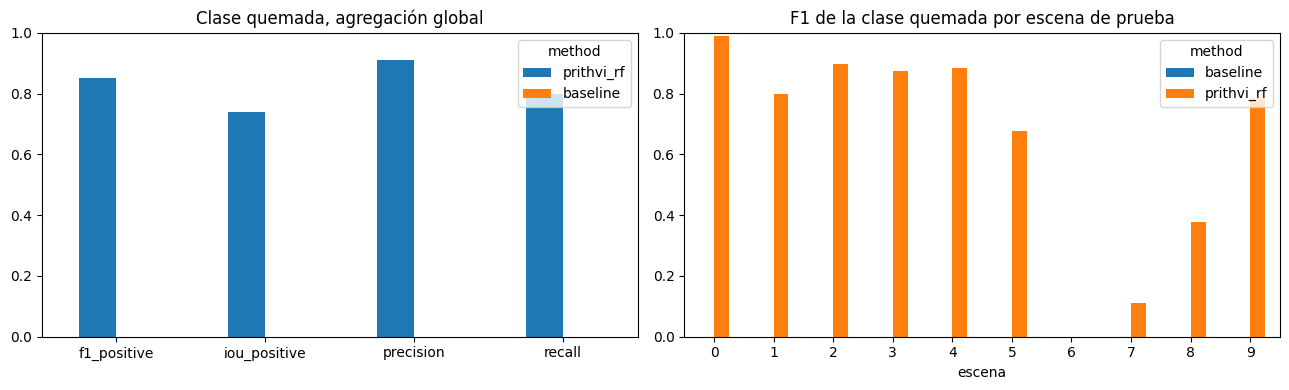

,entrenamiento (parches),prueba (píxeles)
0 no quemado,2445,386046
1 quemado,1475,115714


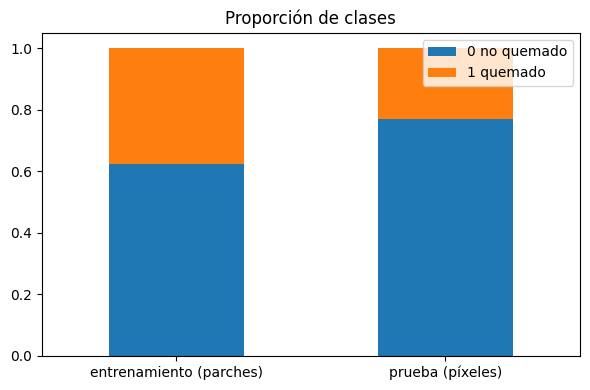

In [12]:
# Métricas por escena, distribución de clases y gráfico comparativo.
# Solo lee los CSV de la sección 7, así que también se puede correr aparte subiendo esos archivos.
por_escena = pd.read_csv(OUT/'metricas_por_escena.csv')
pos = por_escena[por_escena['class'] == 1]
# Convención: si una escena no tiene píxeles quemados ni en referencia ni en predicción,
# F1 e IoU quedan indefinidos (NaN) y no entran al promedio. 'count' dice cuántas escenas entraron.
media = pos.groupby('method')[['f1', 'iou', 'precision', 'recall']].agg(['mean', 'std', 'count'])
media.to_csv(OUT/'metricas_media_por_escena.csv')
display(media.round(3))

f1_escena = pos.pivot(index='scene', columns='method', values='f1')
display(f1_escena.round(3))

glob = pd.read_csv(OUT/'metricas.csv').set_index('method')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
glob[['f1_positive', 'iou_positive', 'precision', 'recall']].T.plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Clase quemada, agregación global'); ax[0].set_ylim(0, 1)
f1_escena.plot.bar(ax=ax[1], rot=0)
ax[1].set_title('F1 de la clase quemada por escena de prueba'); ax[1].set_ylim(0, 1); ax[1].set_xlabel('escena')
fig.tight_layout(); fig.savefig(OUT/'03_comparacion_metricas.png', dpi=150); plt.show()

# Distribución de clases (requiere haber corrido las secciones 3 y 6 en esta sesión)
if 'Y' in globals() and 'samples' in globals():
    dist = pd.DataFrame({
        'entrenamiento (parches)': pd.Series(Y).value_counts().sort_index(),
        'prueba (píxeles)': pd.Series(np.concatenate([y[y >= 0] for _, y in samples['test']])).value_counts().sort_index()})
    dist.index = ['0 no quemado', '1 quemado']
    display(dist)
    (dist / dist.sum()).T.plot.bar(stacked=True, rot=0, figsize=(6, 4), title='Proporción de clases')
    plt.tight_layout(); plt.savefig(OUT/'04_distribucion_clases.png', dpi=150); plt.show()

### Controles adicionales

Dos comparaciones para entender de dónde viene el resultado. Ninguna se usa para escoger nada del modelo principal.

1. **Bandas espectrales + mismo Random Forest.** Igual que el modelo principal, pero sin Prithvi: cada parche se describe con la media y la desviación de sus seis bandas normalizadas, más el promedio del índice NBR. Si este control queda cerca del modelo principal, Prithvi aporta poco en este subconjunto; si queda muy por debajo, las representaciones de Prithvi sí ayudan.
2. **Techo por parche.** Cada bloque de 16 × 16 recibe su clase mayoritaria real y se compara con la máscara píxel a píxel. No es un modelo: es el mejor resultado posible si se predice por bloques, y mide cuánto error viene solo de la resolución del método.

In [13]:
# Control 1: estadísticas espectrales por parche + el mismo Random Forest (sin Prithvi)
def feats_espectrales(x_norm, x_raw):
    b = x_norm[:, 0].reshape(6, 14, 16, 14, 16)
    media_b, desv_b = b.mean(axis=(2, 4)), b.std(axis=(2, 4))
    nir, swir2 = x_raw[3, 0], x_raw[5, 0]
    nbr = np.nan_to_num((nir - swir2) / (nir + swir2 + 1e-6)).reshape(14, 16, 14, 16).mean(axis=(1, 3))
    return np.concatenate([media_b, desv_b, nbr[None]], 0).transpose(1, 2, 0)  # 14 x 14 x 13

Xs, Ys = [], []
for (xn, y), (xr, _) in zip(prepared['train'], samples['train']):
    lab = patch_labels(y); v = lab >= 0
    Xs.append(feats_espectrales(xn, xr)[v]); Ys.append(lab[v])
rf_esp = RandomForestClassifier(n_estimators=80, max_depth=10, class_weight='balanced', random_state=42, n_jobs=2)
rf_esp.fit(np.concatenate(Xs), np.concatenate(Ys))

# Control 2: techo de la predicción por bloques de 16 x 16 (usa la referencia solo para medir, no para ajustar)
ctrl = {n: np.zeros((len(CLASSES), len(CLASSES)), dtype=np.int64) for n in ['espectral_rf', 'techo_parche16']}
filas = []
for i, ((xn, y), (xr, _)) in enumerate(zip(prepared['test'], samples['test'])):
    g = rf_esp.predict(feats_espectrales(xn, xr).reshape(-1, 13)).reshape(14, 14)
    t = patch_labels(y); t = np.where(t < 0, 0, t)
    for name, grid in [('espectral_rf', g), ('techo_parche16', t)]:
        p = np.repeat(np.repeat(grid, 16, axis=0), 16, axis=1)
        m = confusion(y, p, CLASSES); ctrl[name] += m
        filas += [{'scene': i, 'method': name, **r} for r in metrics(m, CLASSES)]

previos = pd.read_csv(OUT/'metricas_por_clase.csv')
tabla = pd.concat([previos[previos['class'] == 1],
                   pd.DataFrame([{'method': n, **metrics(m, CLASSES)[1]} for n, m in ctrl.items()])])
tabla = tabla[['method', 'support', 'f1', 'iou', 'precision', 'recall']]
tabla.to_csv(OUT/'metricas_controles.csv', index=False)
pd.DataFrame(filas).to_csv(OUT/'metricas_controles_por_escena.csv', index=False)
display(tabla.round(3))

,method,support,f1,iou,precision,recall
1,prithvi_rf,115714,0.850,0.739,0.910,0.797
3,baseline,115714,0.000,0.000,0.000,0.000
0,espectral_rf,115714,0.838,0.721,0.919,0.770
1,techo_parche16,115714,0.936,0.879,0.940,0.932


### Control 3: línea base con índice NBR (sin Prithvi y sin clasificador entrenado)

El NBR combina NIR y SWIR2: `NBR = (NIR − SWIR2) / (NIR + SWIR2)`. En una zona quemada baja mucho [10]. Este control es la regla más simple que usa esa física: **marcar como quemado todo lo que tenga NBR por debajo de un umbral**.

- Solo hay una fecha por escena, así que es el NBR posterior al incendio y **no** el dNBR (que necesita una imagen anterior).
- **El umbral se elige solo con las escenas de entrenamiento**, maximizando la IoU de la clase quemada. La prueba no interviene en esa elección.
- Se evalúan dos variantes con las mismas métricas y la misma máscara de válidos que el resto: `nbr_pixel` (decide píxel a píxel) y `nbr_parche16` (promedia el NBR por bloque de 16 × 16 y decide por bloque, igual que Prithvi + RF, para compararlos en igualdad de condiciones).
- Sirve para responder si Prithvi aporta algo por encima de una regla de una sola banda derivada.

In [14]:
# Control 3: umbral de NBR elegido solo con entrenamiento
import json
def nbr_map(x_raw):
    nir, swir2 = x_raw[3, 0].astype(np.float64), x_raw[5, 0].astype(np.float64)
    return np.nan_to_num((nir - swir2) / (nir + swir2 + 1e-6))

def pred_nbr(nbr, t, por_parche):
    if por_parche:
        grid = (nbr.reshape(14, 16, 14, 16).mean(axis=(1, 3)) < t).astype(np.int64)
        return np.repeat(np.repeat(grid, 16, axis=0), 16, axis=1)
    return (nbr < t).astype(np.int64)

nbr_train = [(nbr_map(xr), y) for (xn, y), (xr, _) in zip(prepared['train'], samples['train'])]
todos = np.concatenate([n[y >= 0] for n, y in nbr_train])
candidatos = np.unique(np.quantile(todos, np.linspace(0.02, 0.98, 97)))

def iou_entrenamiento(t, por_parche):
    mat = np.zeros((len(CLASSES), len(CLASSES)), dtype=np.int64)
    for n, y in nbr_train:
        mat += confusion(y, pred_nbr(n, t, por_parche), CLASSES)
    return metrics(mat, CLASSES)[1]['iou']

umbral_nbr = {}
for modo, por_parche in [('nbr_pixel', False), ('nbr_parche16', True)]:
    puntajes = [iou_entrenamiento(t, por_parche) for t in candidatos]
    k = int(np.nanargmax(puntajes))
    umbral_nbr[modo] = float(candidatos[k])
    print(f'{modo}: umbral NBR < {candidatos[k]:.3f} (IoU en entrenamiento = {puntajes[k]:.3f})')

tot_nbr = {m: np.zeros((len(CLASSES), len(CLASSES)), dtype=np.int64) for m in umbral_nbr}
filas_nbr = []
for i, ((xn, y), (xr, _)) in enumerate(zip(prepared['test'], samples['test'])):
    n = nbr_map(xr)
    for modo, por_parche in [('nbr_pixel', False), ('nbr_parche16', True)]:
        m = confusion(y, pred_nbr(n, umbral_nbr[modo], por_parche), CLASSES)
        tot_nbr[modo] += m
        filas_nbr += [{'scene': i, 'method': modo, **r} for r in metrics(m, CLASSES)]
pd.DataFrame(filas_nbr).to_csv(OUT/'metricas_nbr_por_escena.csv', index=False)
json.dump({'regla': 'quemado si NBR < umbral', 'umbral_elegido_con': 'solo escenas de entrenamiento', **umbral_nbr},
          open(OUT/'umbral_nbr.json', 'w'), indent=2)

# Comparación con todo lo anterior: media por escena (principal) y agregado por píxel (complemento)
por_escena = pd.concat([pd.read_csv(OUT/'metricas_por_escena.csv'),
                        pd.read_csv(OUT/'metricas_controles_por_escena.csv'),
                        pd.DataFrame(filas_nbr)])
por_escena = por_escena[por_escena['class'] == 1]
comp = por_escena.groupby('method')[['iou', 'f1', 'precision', 'recall']].mean()
comp.columns = ['IoU media escena', 'F1 media escena', 'Precisión media escena', 'Recall media escena']
agg = pd.concat([pd.read_csv(OUT/'metricas_controles.csv').set_index('method')[['iou', 'f1']],
                 pd.DataFrame({m: metrics(mat, CLASSES)[1] for m, mat in tot_nbr.items()}).T[['iou', 'f1']].astype(float)])
agg.columns = ['IoU agregado píxel', 'F1 agregado píxel']
comparacion = comp.join(agg, how='left').loc[['baseline', 'nbr_pixel', 'nbr_parche16', 'espectral_rf', 'prithvi_rf', 'techo_parche16']]
comparacion.to_csv(OUT/'metricas_comparacion_nbr.csv')
display(comparacion.round(3))


nbr_pixel: umbral NBR < -0.111 (IoU en entrenamiento = 0.505)
nbr_parche16: umbral NBR < -0.111 (IoU en entrenamiento = 0.523)


,IoU media escena,F1 media escena,Precisión media escena,Recall media escena,IoU agregado píxel,F1 agregado píxel
method,,,,,,
baseline,0.000,0.000,0.000,0.000,0.000,0.000
nbr_pixel,0.493,0.557,0.838,0.514,0.716,0.835
nbr_parche16,0.457,0.521,0.657,0.483,0.702,0.825
espectral_rf,0.534,0.644,0.795,0.580,0.721,0.838
prithvi_rf,0.548,0.639,0.735,0.609,0.739,0.850
techo_parche16,0.805,0.890,0.901,0.879,0.879,0.936


## Análisis complementario
Estas celdas amplían la evaluación de la sección 7 con el mismo modelo y los mismos datos, sin cambiar ninguna decisión del método: las etiquetas de prueba solo se usan para medir. Se desarrollaron y probaron primero en un portátil sin GPU; el cuaderno `analisis_local/analisis_20_imagenes.ipynb` del repositorio repite este análisis con 20 escenas de prueba. Las cifras de 10 escenas que se citan en el texto salen de las salidas de abajo (ejecución final en Colab con GPU).

Orden: **A.** media por escena con intervalos; **B.** resultados por escena y por región; **C.** casos con una regla fija; **D.** origen de los errores; **E.** firmas espectrales; **F.** control espectral ampliado; **G.** visibilidad de la cicatriz; **H.** curva de aprendizaje.

In [15]:
# --- Utilidades de análisis (portables al notebook principal) ---
import re, time, warnings
from pathlib import Path
from datetime import date, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from scipy import ndimage
import rasterio
from rasterio.warp import transform as warp_transform
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='IProgress not found')
if 'TIMES' not in globals():
    TIMES = {}
FIG = OUT / 'figuras'
for d in (OUT, FIG, FIG / 'escenas', OUT / 'escenas'):
    d.mkdir(parents=True, exist_ok=True)

# Paleta validada para daltonismo (azul / naranja / aqua) y tinta neutra para texto y ejes
C = {'modelo': '#2a78d6', 'espectral': '#eb6834', 'base': '#898781',
     'VP': '#1baf7a', 'FP': '#eb6834', 'FN': '#2a78d6', 'VN': '#b5b3ab',
     'ink': '#0b0b0b', 'ink2': '#52514e', 'muted': '#898781', 'grid': '#e1e0d9', 'axis': '#c3c2b7',
     'surface': '#fcfcfb', 'quemado': '#52514e', 'noquemado': '#e9e8e3', 'ignorado': '#ffffff',
     'seq': ['#86b6ef', '#2a78d6', '#104281']}
plt.rcParams.update({
    'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'savefig.facecolor': C['surface'],
    'axes.edgecolor': C['axis'], 'axes.labelcolor': C['ink2'], 'axes.titlecolor': C['ink'],
    'xtick.color': C['axis'], 'ytick.color': C['axis'], 'xtick.labelcolor': C['ink2'], 'ytick.labelcolor': C['ink2'],
    'text.color': C['ink'], 'grid.color': C['grid'], 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9.5, 'axes.titlesize': 10.5,
    'legend.frameon': False, 'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})

def scene_id(path):
    """'subsetted_512x512_HLS.S30.T10TEK.2018340.v1.4_merged.tif' -> 'T10TEK.2018340' (tile MGRS . año + día juliano)."""
    m = re.search(r'HLS\.S30\.(T\w{5})\.(\d{7})', Path(path).name)
    return f'{m.group(1)}.{m.group(2)}'

def doy_to_date(code):
    return date(int(code[:4]), 1, 1) + timedelta(days=int(code[4:]) - 1)

def stretch(a):
    a = a.copy()
    for c in range(a.shape[2]):
        v = a[:, :, c]; ok = np.isfinite(v)
        if ok.any():
            lo, hi = np.percentile(v[ok], [2, 98]); a[:, :, c] = np.clip((v - lo) / max(hi - lo, 1e-6), 0, 1)
    return np.nan_to_num(a)

def display_rgb(x):    # color verdadero (rojo, verde, azul), igual que en el notebook principal
    return stretch(x[[2, 1, 0], 0].transpose(1, 2, 0))

def display_false(x):  # falso color SWIR2-NIR-rojo: cicatriz rojiza/morada, vegetación verde, agua oscura
    return stretch(x[[5, 3, 2], 0].transpose(1, 2, 0))

def mask_rgb(y):
    out = np.zeros(y.shape + (3,))
    out[y == 1] = to_rgb(C['quemado']); out[y == 0] = to_rgb(C['noquemado']); out[y < 0] = to_rgb(C['ignorado'])
    return out

def error_rgb(x, y, pred, alpha=0.85):
    g = display_rgb(x).mean(axis=2)
    out = np.repeat((0.35 + 0.6 * g)[..., None], 3, axis=2)        # fondo gris claro (la escena)
    for cat, m in [('VP', (y == 1) & (pred == 1)), ('FP', (y == 0) & (pred == 1)), ('FN', (y == 1) & (pred == 0))]:
        out[m] = (1 - alpha) * out[m] + alpha * np.array(to_rgb(C[cat]))
    out[y < 0] = to_rgb(C['ignorado'])
    return out

LEG_ERR = [Patch(color=C['VP'], label='Quemado detectado (VP)'), Patch(color=C['FP'], label='Falso positivo (FP)'),
           Patch(color=C['FN'], label='Falso negativo (FN)'), Patch(facecolor=C['ignorado'], edgecolor=C['axis'], label='Ignorado (−1)')]
LEG_MASK = [Patch(color=C['quemado'], label='Quemado (1)'), Patch(color=C['noquemado'], label='No quemado (0)'),
            Patch(facecolor=C['ignorado'], edgecolor=C['axis'], label='Ignorado (−1)')]

def to_grid(a):
    """(..., 224, 224) -> (..., 14, 14, 256): bloques 16×16 en el mismo orden que patch_labels y los tokens."""
    s = a.shape[:-2]
    return a.reshape(*s, 14, 16, 14, 16).swapaxes(-3, -2).reshape(*s, 14, 14, 256)

def up(grid):
    return np.repeat(np.repeat(grid, 16, axis=0), 16, axis=1)

def boot_ci(v, B=10000, seed=0):
    """IC95 % de la media por escena: bootstrap remuestreando ESCENAS (no píxeles)."""
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    if len(v) == 0:
        return np.array([np.nan, np.nan])
    idx = np.random.default_rng(seed).integers(0, len(v), size=(B, len(v)))
    return np.percentile(v[idx].mean(axis=1), [2.5, 97.5])

def region(sid):
    """Agrupación geográfica por zona UTM del tile MGRS: 10–13 = Oeste (lon < −102°), 14–18 = Centro-Este."""
    return 'Oeste' if int(sid[1:3]) <= 13 else 'Centro-Este'

def indices(x_raw):
    """Índices espectrales por píxel a partir de reflectancia (bandas: azul, verde, rojo, NIR B8A, SWIR1, SWIR2)."""
    b, g, r, nir, sw1, sw2 = x_raw[:, 0]
    with np.errstate(invalid='ignore', divide='ignore'):
        return {'NBR': (nir - sw2) / (nir + sw2), 'NDVI': (nir - r) / (nir + r), 'NBR2': (sw1 - sw2) / (sw1 + sw2),
                'NIR (B8A)': nir, 'SWIR2': sw2, 'Brillo visible': (b + g + r) / 3}

def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2)**2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

# Mismo flujo que las celdas 21 y 23 del notebook principal, en funciones reutilizables
def extract(rows):
    return [features(model, device, x) for x, _ in rows]

def train_head(F_train, rows_train):
    feats, targets = [], []
    for f, (_, y) in zip(F_train, rows_train):
        lab = patch_labels(y); v = lab >= 0
        feats.append(f[v]); targets.append(lab[v])
    X_, Y_ = np.concatenate(feats), np.concatenate(targets)
    h = RandomForestClassifier(n_estimators=80, max_depth=10, class_weight='balanced', random_state=42, n_jobs=2)
    return h.fit(X_, Y_), X_, Y_

def train_majority(rows_raw):
    lab = np.concatenate([y[y >= 0] for _, y in rows_raw])
    values, counts = np.unique(lab, return_counts=True)
    return int(values[np.argmax(counts)]), dict(zip(values.tolist(), counts.tolist()))

def predict_grid(h, f):
    return h.predict(f.reshape(-1, f.shape[-1])).reshape(14, 14)

### A. Media por escena con intervalos de confianza
Convención del enunciado: media por escena de las métricas de la clase quemada, con el agregado por píxel aparte y rotulado. IC95 % por bootstrap de escenas (10 000 réplicas). Si una escena no tuviera positivos ni en la referencia ni en la predicción, su IoU y su F1 quedarían indefinidos y fuera del promedio (no ocurre en este subconjunto). La tercera celda es el gráfico comparativo que pedía el cuaderno guía.

In [16]:
# Puente para el notebook principal: reconstruye lo que este análisis necesita a partir de sus variables.
if 'ids' not in globals():
    ids = {s: [scene_id(im) for im, _ in rows] for s, rows in pairs.items()}
if 'F' not in globals():
    F = {s: [features(model, device, x) for x, _ in rows] for s, rows in prepared.items()}
if 'COLAB_TEST' not in globals():   # escenas de la corrida original de Colab (20 de entrenamiento, 10 de prueba)
    COLAB_TEST = ['T10TGK.2020285', 'T10TGL.2018215', 'T11TQG.2018221', 'T12SUJ.2019308', 'T14RNV.2018215',
                  'T14SKF.2019246', 'T15TVN.2019140', 'T16REV.2019135', 'T16SDC.2018098', 'T18SVJ.2020131']
if 'COLAB_TRAIN' not in globals():
    COLAB_TRAIN = ['T10TEK.2018340', 'T11SMT.2019294', 'T11TKE.2018215', 'T11TMF.2019312', 'T11TMJ.2018217',
                   'T12STC.2020218', 'T12SUH.2020188', 'T12SVC.2019245', 'T12SVD.2018168', 'T12TUK.2020286',
                   'T13SFB.2020189', 'T13TCJ.2020200', 'T13TCM.2020250', 'T13TEF.2019109', 'T14SLA.2020193',
                   'T15RTM.2020059', 'T15SXA.2018154', 'T16RFT.2019250', 'T16SDB.2018063', 'T17RMJ.2018064']

def evaluate(grids, rows_test, maj, method):
    """Métricas por escena de la clase 1 para `method` y para la línea base, con la misma máscara de válidos."""
    out, mats = [], {method: [], 'linea_base': []}
    for i, (grid, (_, y)) in enumerate(zip(grids, rows_test)):
        for name, p in [(method, up(grid)), ('linea_base', np.full(y.shape, maj, dtype=np.int64))]:
            mat = confusion(y, p, CLASSES); mats[name].append(mat)
            m1 = metrics(mat, CLASSES)[1]
            out.append({'i': i, 'escena': ids['test'][i], 'metodo': name, 'vp': int(mat[1, 1]), 'fp': int(mat[0, 1]),
                        'fn': int(mat[1, 0]), 'vn': int(mat[0, 0]), 'soporte_1': m1['support'], 'iou': m1['iou'],
                        'f1': m1['f1'], 'precision': m1['precision'], 'recall': m1['recall']})
    d = pd.DataFrame(out)
    with np.errstate(invalid='ignore', divide='ignore'):
        d['exactitud'] = (d.vp + d.vn) / (d.vp + d.vn + d.fp + d.fn)
        d['iou_0'] = np.where(d.vn + d.fp + d.fn > 0, d.vn / (d.vn + d.fp + d.fn), np.nan)
    return d, mats

def summarize(df, mats, subset=None):
    rows = []
    for name in df.metodo.unique():
        d = df[df.metodo == name]
        if subset is not None:
            d = d[d.escena.isin(subset)]
        pooled = metrics(sum(mats[name][i] for i in d.i), CLASSES)[1]
        row = {'método': name, 'escenas': len(d), 'escenas con IoU definido': int(d.iou.notna().sum())}
        for col, lab in [('iou', 'IoU'), ('f1', 'F1'), ('precision', 'Precisión'), ('recall', 'Recall')]:
            lo, hi = boot_ci(d[col])
            row[f'{lab} media escena'] = d[col].mean(); row[f'{lab} IC95'] = f'{lo:.3f}–{hi:.3f}'
        for col, lab in [('iou', 'IoU'), ('f1', 'F1'), ('precision', 'Precisión'), ('recall', 'Recall')]:
            row[f'{lab} agregado píxel'] = pooled[col]
        rows.append(row)
    return pd.DataFrame(rows).set_index('método')

t0 = time.perf_counter()
grids = [predict_grid(head, f) for f in F['test']]
per_scene, mats = evaluate(grids, prepared['test'], majority, 'prithvi_rf')
TIMES['evaluacion_s'] = time.perf_counter() - t0
for i, (grid, (_, y)) in enumerate(zip(grids, prepared['test'])):
    np.savez_compressed(OUT / 'escenas' / f'escena_{i:02d}_{ids["test"][i]}.npz', label=y, prediction=up(grid),
                        baseline=np.full(y.shape, majority, dtype=np.int64))

summ20 = summarize(per_scene, mats)
summ10 = summarize(per_scene, mats, subset=set(COLAB_TEST))
print(f'Prueba: {len(ids["test"])} escenas')
display(summ20.round(3))
print('Solo las 10 escenas de Colab')
display(summ10.round(3))

Prueba: 10 escenas


,escenas,escenas con IoU definido,IoU media escena,IoU IC95,F1 media escena,F1 IC95,Precisión media escena,Precisión IC95,Recall media escena,Recall IC95,IoU agregado píxel,F1 agregado píxel,Precisión agregado píxel,Recall agregado píxel
método,,,,,,,,,,,,,,
prithvi_rf,10,10,0.548,0.343–0.738,0.639,0.422–0.831,0.735,0.511–0.921,0.609,0.381–0.817,0.739,0.85,0.91,0.797
linea_base,10,10,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.00,0.00,0.000


Solo las 10 escenas de Colab


,escenas,escenas con IoU definido,IoU media escena,IoU IC95,F1 media escena,F1 IC95,Precisión media escena,Precisión IC95,Recall media escena,Recall IC95,IoU agregado píxel,F1 agregado píxel,Precisión agregado píxel,Recall agregado píxel
método,,,,,,,,,,,,,,
prithvi_rf,10,10,0.548,0.343–0.738,0.639,0.422–0.831,0.735,0.511–0.921,0.609,0.381–0.817,0.739,0.85,0.91,0.797
linea_base,10,10,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.00,0.00,0.000


In [17]:
# Verificación de reproducibilidad frente a la corrida de Colab (agregado por píxel, mismas 10 escenas)
COLAB_RES = {'prithvi_rf': {0: {'iou': 0.920455, 'f1': 0.958580, 'precision': 0.941416, 'recall': 0.976381},
                            1: {'iou': 0.739057, 'f1': 0.849952, 'precision': 0.910058, 'recall': 0.797293}},
             'linea_base': {0: {'iou': 0.769384, 'f1': 0.869663, 'precision': 0.769384, 'recall': 1.0},
                            1: {'iou': 0.0, 'f1': 0.0, 'precision': 0.0, 'recall': 0.0}}}
COLAB_SUPPORT = {0: 386046, 1: 115714}
rep = pd.DataFrame()
if sorted(ids['train']) == sorted(COLAB_TRAIN) and set(COLAB_TEST) <= set(ids['test']):
    idx10 = [i for i, s in enumerate(ids['test']) if s in COLAB_TEST]
    rows_rep = []
    for name in ['prithvi_rf', 'linea_base']:
        pooled = metrics(sum(mats[name][i] for i in idx10), CLASSES)
        for c in CLASSES:
            for k in ['iou', 'f1', 'precision', 'recall']:
                rows_rep.append({'método': name, 'clase': c, 'métrica': k, 'Colab (GPU T4)': COLAB_RES[name][c][k],
                                 'esta ejecución': round(float(pooled[c][k]), 6)})
    rep = pd.DataFrame(rows_rep); rep['diferencia'] = (rep['esta ejecución'] - rep['Colab (GPU T4)']).round(6)
    support10 = {c: metrics(sum(mats['prithvi_rf'][i] for i in idx10), CLASSES)[c]['support'] for c in CLASSES}
    print('Soporte (píxeles válidos) en las 10 escenas:', support10, '| Colab:', COLAB_SUPPORT, '| iguales:', support10 == COLAB_SUPPORT)
    print('Máxima diferencia absoluta en métricas:', rep['diferencia'].abs().max())
    display(rep.pivot_table(index=['método', 'clase'], columns='métrica', values='diferencia'))
else:
    print('Comparación con Colab omitida: el entrenamiento no es el de Colab (NTRAIN distinto de 20).')

Soporte (píxeles válidos) en las 10 escenas: {0: 386046, 1: 115714} | Colab: {0: 386046, 1: 115714} | iguales: True
Máxima diferencia absoluta en métricas: 0.0


métrica            f1  iou  precision  recall
método     clase                             
linea_base 0      0.0  0.0        0.0     0.0
           1      0.0  0.0        0.0     0.0
prithvi_rf 0      0.0  0.0        0.0     0.0
           1      0.0  0.0        0.0     0.0

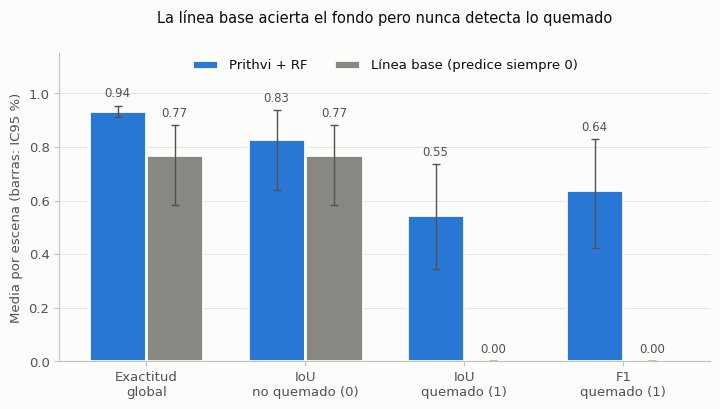

In [18]:
# Gráfico comparativo pedido en el cuaderno guía: media por escena con IC95 %
cols = [('exactitud', 'Exactitud\nglobal'), ('iou_0', 'IoU\nno quemado (0)'), ('iou', 'IoU\nquemado (1)'), ('f1', 'F1\nquemado (1)')]
series = [('prithvi_rf', 'Prithvi + RF', C['modelo']), ('linea_base', 'Línea base (predice siempre 0)', C['base'])]
fig, ax = plt.subplots(figsize=(8.4, 4.0))
w = 0.36
for k, (name, label, color) in enumerate(series):
    d = per_scene[per_scene.metodo == name]
    means = np.array([d[c].mean() for c, _ in cols]); cis = np.array([boot_ci(d[c]) for c, _ in cols])
    xs = np.arange(len(cols)) + (k - 0.5) * w
    ax.bar(xs, means, width=w, color=color, label=label, edgecolor=C['surface'], linewidth=2)
    ax.errorbar(xs, means, yerr=[means - cis[:, 0], cis[:, 1] - means], fmt='none', ecolor=C['ink2'], elinewidth=1, capsize=3)
    for xv, m_, hi in zip(xs, means, cis[:, 1]):
        ax.text(xv, max(hi, m_) + 0.02, f'{m_:.2f}', ha='center', va='bottom', fontsize=8.5, color=C['ink2'])
ax.set_xticks(np.arange(len(cols))); ax.set_xticklabels([l for _, l in cols]); ax.set_ylim(0, 1.15); ax.yaxis.grid(True)
ax.set_ylabel('Media por escena (barras: IC95 %)'); ax.legend(loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.02))
ax.set_title('La línea base acierta el fondo pero nunca detecta lo quemado', pad=22)
fig.savefig(FIG / '03_modelo_vs_linea_base.png'); plt.show()

### B. Resultados por escena y por región
La agrupación por región (zonas UTM 10 a 13 = oeste; 14 a 18 = centro y este) es exploratoria: se planteó después de ver las figuras de la sección 7.

,i,escena,fecha,en Colab,% quemado,soporte_1,iou,f1,precision,recall,fp,fn
0,0,T10TGK.2020285,2020-10-11,True,100.000,50176,0.980,0.990,1.000,0.980,0,1024
1,2,T11TQG.2018221,2018-08-09,True,17.072,8566,0.812,0.896,0.865,0.930,1247,597
2,4,T14RNV.2018215,2018-08-03,True,13.142,6594,0.792,0.884,0.937,0.836,373,1079
3,3,T12SUJ.2019308,2019-11-04,True,27.208,13652,0.776,0.874,0.861,0.887,1964,1536
4,1,T10TGL.2018215,2018-08-03,True,18.977,9522,0.665,0.799,0.709,0.915,3577,811
5,9,T18SVJ.2020131,2020-05-10,True,13.586,6817,0.648,0.787,0.975,0.659,114,2323
6,5,T14SKF.2019246,2019-09-03,True,10.653,5345,0.513,0.678,0.845,0.567,556,2317
7,8,T16SDC.2018098,2018-04-08,True,8.737,4384,0.232,0.377,0.996,0.233,4,3364
8,7,T16REV.2019135,2019-05-15,True,6.150,3086,0.058,0.109,0.165,0.082,1283,2833
9,6,T15TVN.2019140,2019-05-20,True,15.091,7572,0.000,0.000,0.000,0.000,0,7572


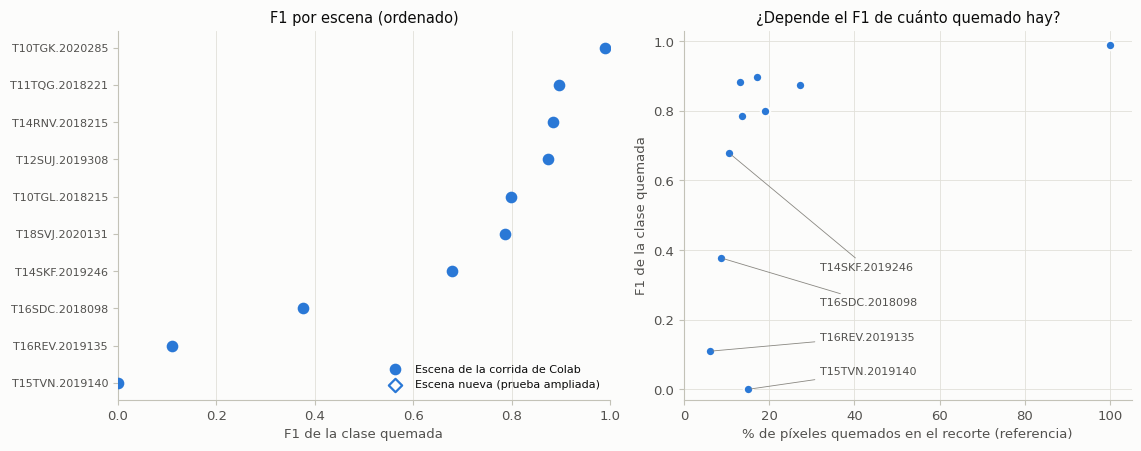

,escenas de entrenamiento,escenas de prueba,F1 media,IoU media,escenas con F1 < 0.4,F1 IC95
región,,,,,,
Centro-Este,6,6,0.473,0.374,3,0.20–0.73
Oeste,14,4,0.890,0.808,0,0.82–0.96


In [19]:
m = per_scene[per_scene.metodo == 'prithvi_rf'].copy()
m['fecha'] = [doy_to_date(s[7:]) for s in m.escena]
m['en Colab'] = m.escena.isin(COLAB_TEST)
m['% quemado'] = [100 * (y == 1).sum() / (y >= 0).sum() for _, y in samples['test']]
tabla_escenas = (m[['i', 'escena', 'fecha', 'en Colab', '% quemado', 'soporte_1', 'iou', 'f1', 'precision', 'recall', 'fp', 'fn']]
                 .sort_values('f1', ascending=False).reset_index(drop=True))
display(tabla_escenas.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
o = m.sort_values('f1')
yy = np.arange(len(o))
for flag, mk, lab in [(True, 'o', 'Escena de la corrida de Colab'), (False, 'D', 'Escena nueva (prueba ampliada)')]:
    s = o['en Colab'].values == flag
    ax[0].scatter(o.f1.values[s], yy[s], marker=mk, s=46, color=C['modelo'] if flag else C['surface'],
                  edgecolor=C['modelo'], linewidth=1.6, label=lab, zorder=3)
ax[0].set_yticks(yy); ax[0].set_yticklabels(o.escena, fontsize=8); ax[0].set_xlim(0, 1); ax[0].xaxis.grid(True)
ax[0].set_xlabel('F1 de la clase quemada'); ax[0].set_title('F1 por escena (ordenado)'); ax[0].legend(loc='lower right', fontsize=8)
ax[1].scatter(m['% quemado'], m.f1, s=46, color=C['modelo'], edgecolor=C['surface'], linewidth=1.5, zorder=3)
low = m.nsmallest(4, 'f1').sort_values(['f1', '% quemado'], ascending=[True, False])
for k, (_, r) in enumerate(low.iterrows()):
    xt, yt, ha = (32, 0.05 + 0.1 * k, 'left') if r['% quemado'] < 50 else (r['% quemado'] - 6, r.f1 + 0.14, 'right')
    ax[1].annotate(r.escena, (r['% quemado'], r.f1), xytext=(xt, yt), textcoords='data', fontsize=8, color=C['ink2'], ha=ha,
                   va='center', arrowprops={'arrowstyle': '-', 'color': C['muted'], 'lw': 0.6})
ax[1].set_xlabel('% de píxeles quemados en el recorte (referencia)'); ax[1].set_ylabel('F1 de la clase quemada')
ax[1].set_xlim(0, 105); ax[1].set_ylim(-0.03, 1.03); ax[1].grid(True); ax[1].set_title('¿Depende el F1 de cuánto quemado hay?')
fig.tight_layout(); fig.savefig(FIG / '04_metricas_por_escena.png'); plt.show()

# Exploratorio: desempeño por región (zona UTM del tile). Se planteó al ver el mosaico; con 9–11 escenas por grupo no es concluyente.
m['región'] = [region(s) for s in m.escena]
reg = m.groupby('región').agg(**{'escenas de prueba': ('f1', 'size'), 'F1 media': ('f1', 'mean'), 'IoU media': ('iou', 'mean'),
                                 'escenas con F1 < 0.4': ('f1', lambda s: int((s < 0.4).sum()))})
reg['F1 IC95'] = ['{:.2f}–{:.2f}'.format(*boot_ci(m.loc[m['región'] == g, 'f1'])) for g in reg.index]
reg.insert(0, 'escenas de entrenamiento', pd.Series([region(s) for s in ids['train']]).value_counts().reindex(reg.index).fillna(0).astype(int))
display(reg.round(3))

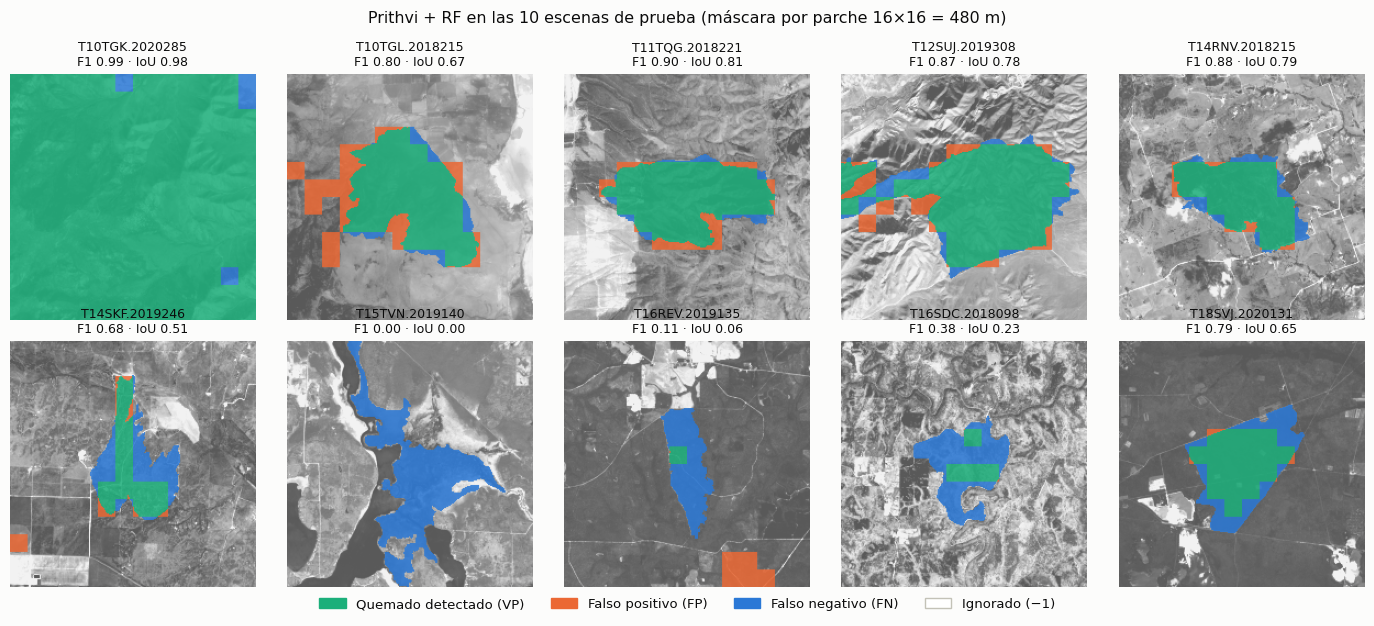

In [20]:
# Mosaico de las escenas de prueba: aciertos y errores sobre la escena en gris
n_te = len(ids['test']); nrow = int(np.ceil(n_te / 5))
fig, axes = plt.subplots(nrow, 5, figsize=(14, 3.05 * nrow), squeeze=False)
for ax in axes.flat[n_te:]:
    ax.axis('off')
for ax, i in zip(axes.flat, range(n_te)):
    x, y = samples['test'][i]
    ax.imshow(error_rgb(x, y, up(grids[i]))); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    r = m.set_index('i').loc[i]
    ax.set_title(f"{ids['test'][i]}{'' if r['en Colab'] else ' (nueva)'}\nF1 {r.f1:.2f} · IoU {r.iou:.2f}", fontsize=9)
fig.legend(handles=LEG_ERR, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.005))
fig.suptitle(f'Prithvi + RF en las {n_te} escenas de prueba (máscara por parche 16×16 = 480 m)', y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG / '05_mosaico_prueba.png'); plt.show()

# Figuras individuales (como 02_resultado_i.png del notebook principal), guardadas sin mostrar
for i in range(len(ids['test'])):
    x, y = samples['test'][i]; pred = up(grids[i])
    f2, a2 = plt.subplots(1, 5, figsize=(16, 3.6))
    for a, img, t in zip(a2, [display_rgb(x), display_false(x), mask_rgb(y), mask_rgb(np.where(y < 0, -1, pred)), error_rgb(x, y, pred)],
                         ['Color verdadero', 'Falso color SWIR2-NIR-R', 'Referencia', 'Prithvi + RF (parche 16)', 'VP / FP / FN']):
        a.imshow(img); a.set_title(t); a.axis('off')
    f2.suptitle(ids['test'][i]); f2.savefig(FIG / 'escenas' / f'resultado_{i:02d}_{ids["test"][i]}.png', dpi=100); plt.close(f2)

### C. Casos representativos con una regla fija
Regla definida antes de mirar las imágenes: acierto = escena con mayor F1; falsos positivos = escena con más píxeles FP; falsos negativos = escena con más píxeles FN, sin repetir escenas.

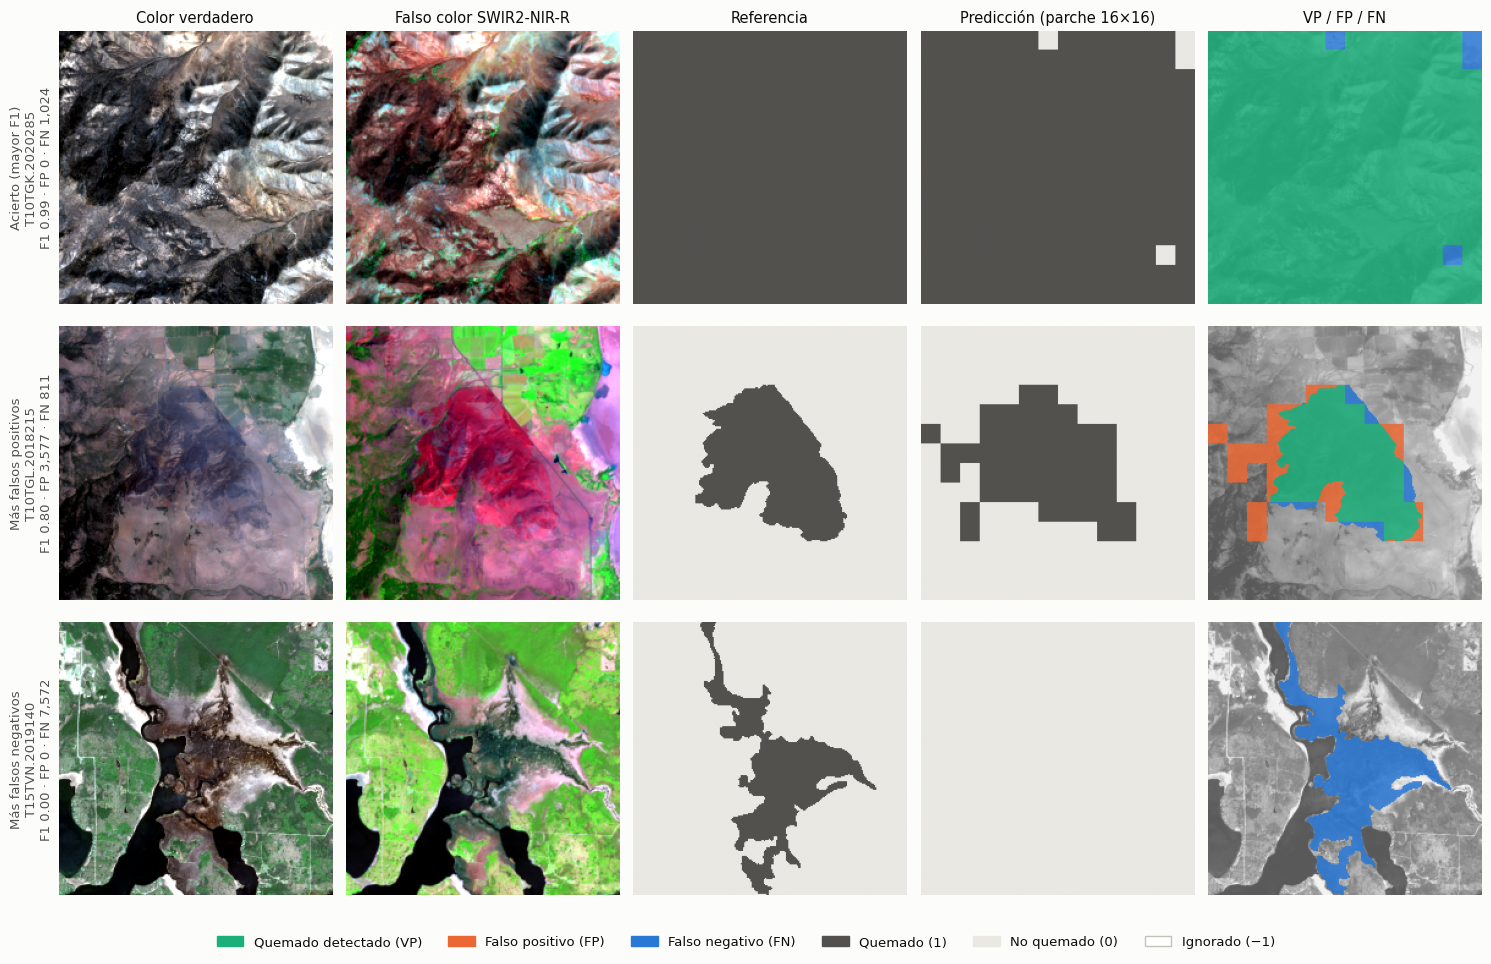

,caso,escena,categoría,píxeles,NBR,NDVI,NIR (B8A),Brillo visible
0,Acierto (mayor F1),T10TGK.2020285,VP,49152,-0.313,0.167,0.103,0.058
1,Acierto (mayor F1),T10TGK.2020285,FN,1024,-0.193,0.189,0.168,0.089
2,Acierto (mayor F1),T10TGK.2020285,FP,0,NaN,NaN,NaN,NaN
3,Acierto (mayor F1),T10TGK.2020285,VN,0,NaN,NaN,NaN,NaN
4,Más falsos positivos,T10TGL.2018215,VP,8711,-0.169,0.172,0.123,0.072
5,Más falsos positivos,T10TGL.2018215,FN,811,-0.124,0.193,0.153,0.085
6,Más falsos positivos,T10TGL.2018215,FP,3577,0.159,0.360,0.175,0.068
7,Más falsos positivos,T10TGL.2018215,VN,37077,0.202,0.369,0.234,0.089
8,Más falsos negativos,T15TVN.2019140,VP,0,NaN,NaN,NaN,NaN
9,Más falsos negativos,T15TVN.2019140,FN,7572,0.197,0.333,0.113,0.041


In [21]:
mm = m.set_index('i')
acierto = int(mm.f1.idxmax())
caso_fp = int(mm.drop(index=[acierto]).fp.idxmax())
caso_fn = int(mm.drop(index=[acierto, caso_fp]).fn.idxmax())
casos = [('Acierto (mayor F1)', acierto), ('Más falsos positivos', caso_fp), ('Más falsos negativos', caso_fn)]

fig, axes = plt.subplots(3, 5, figsize=(15, 9.6))
titles = ['Color verdadero', 'Falso color SWIR2-NIR-R', 'Referencia', 'Predicción (parche 16×16)', 'VP / FP / FN']
for r_, (title, i) in enumerate(casos):
    x, y = samples['test'][i]; pred = up(grids[i])
    imgs = [display_rgb(x), display_false(x), mask_rgb(y), mask_rgb(np.where(y < 0, -1, pred)), error_rgb(x, y, pred)]
    for c_, img in enumerate(imgs):
        ax = axes[r_, c_]; ax.imshow(img); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        if r_ == 0: ax.set_title(titles[c_])
    axes[r_, 0].set_ylabel(f'{title}\n{ids["test"][i]}\nF1 {mm.f1[i]:.2f} · FP {mm.fp[i]:,} · FN {mm.fn[i]:,}', fontsize=9.5)
fig.legend(handles=LEG_ERR[:3] + LEG_MASK, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG / '06_casos_representativos.png'); plt.show()

crow = []
for title, i in casos:
    x, y = samples['test'][i]; pred = up(grids[i]); ix = indices(x)
    for cat, msk in [('VP', (y == 1) & (pred == 1)), ('FN', (y == 1) & (pred == 0)), ('FP', (y == 0) & (pred == 1)), ('VN', (y == 0) & (pred == 0))]:
        crow.append({'caso': title, 'escena': ids['test'][i], 'categoría': cat, 'píxeles': int(msk.sum()),
                     **{k: (float(np.nanmean(ix[k][msk])) if msk.any() else np.nan) for k in ['NBR', 'NDVI', 'NIR (B8A)', 'Brillo visible']}})
casos_tabla = pd.DataFrame(crow)
display(casos_tabla.round(3))

### D. ¿De dónde vienen los errores?
El **oráculo de parche** asigna a cada bloque de 16 × 16 su clase mayoritaria real. Usa etiquetas de prueba, así que no es un método: es el techo de cualquier predicción por bloques. Los errores se separan en *inevitables por resolución* (el modelo eligió lo mismo que el oráculo), *decisiones en parches de borde* y *decisiones en parches puros*. También se mide la tasa de error según la distancia al borde de la cicatriz y la detección de fragmentos según su tamaño.

,Inevitable por resolución 16×16,Decisión en parche mixto (borde),Decisión en parche puro,total
tipo,,,,
FN,6974,12386,4096,23456
FP,3141,2649,3328,9118


Mismo desglose para las escenas de los casos representativos (sección 7):


Inevitable por resolución 16×16  \
escena         tipo                                    
T10TGK.2020285 FP                                  0   
               FN                                  0   
T10TGL.2018215 FP                                650   
               FN                                383   
T15TVN.2019140 FP                                  0   
               FN                               1533   

                     Decisión en parche mixto (borde)  Decisión en parche puro  
escena         tipo                                                             
T10TGK.2020285 FP                                   0                        0  
               FN                                   0                     1024  
T10TGL.2018215 FP                                1391                     1536  
               FN                                 428                        0  
T15TVN.2019140 FP                                   0                        0  
               FN                                4503                     1536

,Inevitable por resolución 16×16,Decisión en parche mixto (borde),Decisión en parche puro
tipo,,,
FN,29.7 %,52.8 %,17.5 %
FP,34.4 %,29.1 %,36.5 %


Del total de píxeles mal clasificados (32,574), 31.1 % son inevitables con parches de 16×16 y 77.2 % están en parches de borde (mixtos).


,Prithvi + RF,Oráculo de parche (techo)
IoU media escena,0.548,0.805
F1 media escena,0.639,0.890


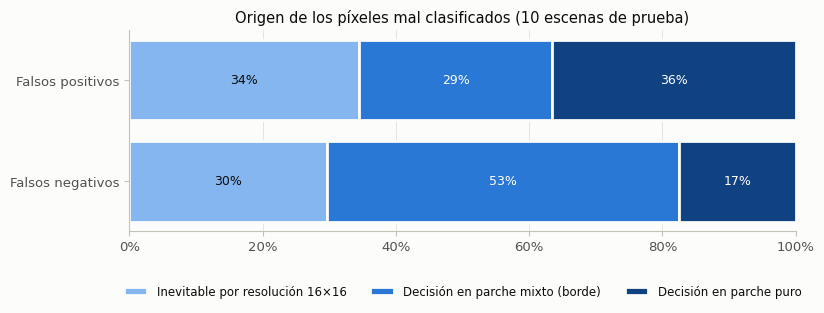

In [22]:
dec_rows, orc = [], []
mats['oraculo_parche'] = []
for i, (grid, (_, y)) in enumerate(zip(grids, prepared['test'])):
    b = to_grid(y); n0 = (b == 0).sum(-1); n1 = (b == 1).sum(-1)
    og = (n1 > n0).astype(np.int64)
    pure = (n0 == 0) | (n1 == 0); agree = grid == og
    fp_b, fn_b = np.where(grid == 1, n0, 0), np.where(grid == 0, n1, 0)
    for err, blk in [('FP', fp_b), ('FN', fn_b)]:
        dec_rows.append({'i': i, 'tipo': err, 'Inevitable por resolución 16×16': int(blk[agree].sum()),
                         'Decisión en parche mixto (borde)': int(blk[~agree & ~pure].sum()),
                         'Decisión en parche puro': int(blk[~agree & pure].sum())})
    mat = confusion(y, up(og), CLASSES); mats['oraculo_parche'].append(mat); m1 = metrics(mat, CLASSES)[1]
    orc.append({'i': i, 'escena': ids['test'][i], 'metodo': 'oraculo_parche', 'vp': int(mat[1, 1]), 'fp': int(mat[0, 1]),
                'fn': int(mat[1, 0]), 'vn': int(mat[0, 0]), 'soporte_1': m1['support'], 'iou': m1['iou'], 'f1': m1['f1'],
                'precision': m1['precision'], 'recall': m1['recall']})
orc = pd.DataFrame(orc)
dec_scene = pd.DataFrame(dec_rows)
dec = dec_scene.groupby('tipo').sum().drop(columns='i')
dec['total'] = dec.sum(axis=1)
display(dec)
dec_cases = dec_scene[dec_scene.i.isin([i for _, i in casos])].copy()
dec_cases.insert(0, 'escena', [ids['test'][i] for i in dec_cases.i])
print('Mismo desglose para las escenas de los casos representativos (sección 7):')
display(dec_cases.drop(columns='i').set_index(['escena', 'tipo']))
share = dec.drop(columns='total').div(dec.total, axis=0)
display((100 * share).round(1).astype(str) + ' %')
both = dec.drop(columns='total').sum()
print(f"Del total de píxeles mal clasificados ({int(dec.total.sum()):,}), "
      f"{100 * both.iloc[0] / dec.total.sum():.1f} % son inevitables con parches de 16×16 y "
      f"{100 * (both.iloc[0] + both.iloc[1]) / dec.total.sum():.1f} % están en parches de borde (mixtos).")
techo = pd.DataFrame({'Prithvi + RF': [m.iou.mean(), m.f1.mean()], 'Oráculo de parche (techo)': [orc.iou.mean(), orc.f1.mean()]},
                     index=['IoU media escena', 'F1 media escena'])
display(techo.round(3))

fig, ax = plt.subplots(figsize=(8.6, 2.6))
left = np.zeros(2)
labels_dec = list(share.columns)
for k, col in enumerate(labels_dec):
    vals = share.loc[['FN', 'FP'], col].values
    ax.barh(['Falsos negativos', 'Falsos positivos'], vals, left=left, color=C['seq'][k], edgecolor=C['surface'], linewidth=2, label=col)
    for j, (l, v) in enumerate(zip(left, vals)):
        if v > 0.07:
            ax.text(l + v / 2, j, f'{v:.0%}', ha='center', va='center', fontsize=9, color=C['ink'] if k == 0 else '#ffffff')
    left += vals
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.xaxis.grid(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8.5)
ax.set_title(f'Origen de los píxeles mal clasificados ({len(ids["test"])} escenas de prueba)')
fig.savefig(FIG / '07_origen_errores.png'); plt.show()

Errores a ≤ 8 px (240 m) del borde: FN 72% · FP 59%


pixeles        errores         tasa       
clase       0      1       0     1      0      1
rango                                           
1        4435   4407    1159  3107  0.261  0.705
2        4279   4206     958  2783  0.224  0.662
3–4      9037   8342    1595  4935  0.176  0.592
5–8     17731  13836    1705  6080  0.096  0.439
9–16    34721  18810     833  4584  0.024  0.244
17–32   74923  14113     818   943  0.011  0.067
>32    240920  52000    2050  1024  0.009  0.020

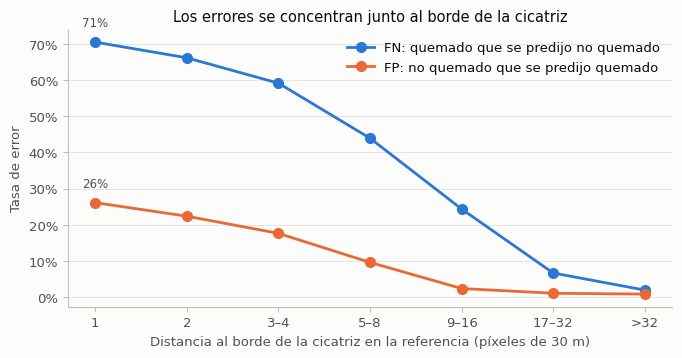

In [23]:
# Tasa de error según la distancia (en píxeles de 30 m) al borde más cercano de la referencia
bins = [0, 1, 2, 4, 8, 16, 32, np.inf]
bin_labels = ['1', '2', '3–4', '5–8', '9–16', '17–32', '>32']
parts = []
for i, (grid, (_, y)) in enumerate(zip(grids, prepared['test'])):
    pred = up(grid)
    d_to0 = ndimage.distance_transform_edt(y != 0) if (y == 0).any() else np.full(y.shape, np.inf)
    d_to1 = ndimage.distance_transform_edt(y != 1) if (y == 1).any() else np.full(y.shape, np.inf)
    bm, um = y == 1, y == 0
    parts.append(pd.DataFrame({'clase': 1, 'dist': d_to0[bm], 'error': pred[bm] == 0}))
    parts.append(pd.DataFrame({'clase': 0, 'dist': d_to1[um], 'error': pred[um] == 1}))
dd = pd.concat(parts, ignore_index=True)
dd['rango'] = pd.cut(dd.dist, bins=bins, labels=bin_labels)
rate = dd.groupby(['clase', 'rango'], observed=False).agg(pixeles=('error', 'size'), errores=('error', 'sum'))
rate['tasa'] = rate.errores / rate.pixeles
near = dd[dd.error].assign(cerca=lambda t: t.dist <= 8).groupby('clase').cerca.mean()
print(f'Errores a ≤ 8 px (240 m) del borde: FN {near.get(1, np.nan):.0%} · FP {near.get(0, np.nan):.0%}')
display(rate.unstack(0).round(3))

fig, ax = plt.subplots(figsize=(7.8, 3.6))
for cls, lab, color in [(1, 'FN: quemado que se predijo no quemado', C['FN']), (0, 'FP: no quemado que se predijo quemado', C['FP'])]:
    r = rate.loc[cls]
    ax.plot(range(len(bin_labels)), r.tasa.values, color=color, lw=2, marker='o', ms=7, label=lab)
    ax.annotate(f'{r.tasa.values[0]:.0%}', (0, r.tasa.values[0]), xytext=(0, 9), textcoords='offset points', fontsize=8.5,
                color=C['ink2'], ha='center', va='bottom')
ax.set_xticks(range(len(bin_labels))); ax.set_xticklabels(bin_labels); ax.yaxis.grid(True)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('Distancia al borde de la cicatriz en la referencia (píxeles de 30 m)'); ax.set_ylabel('Tasa de error')
ax.set_title('Los errores se concentran junto al borde de la cicatriz'); ax.legend(loc='upper right')
fig.savefig(FIG / '08_error_vs_distancia_borde.png'); plt.show()

In [24]:
# Fragmentos pequeños: componentes conexas (8-vecindad) de la clase quemada en la referencia
crows = []
for i, (grid, (_, y)) in enumerate(zip(grids, prepared['test'])):
    lab, n = ndimage.label(y == 1, structure=np.ones((3, 3), int))
    if n == 0:
        continue
    pred = up(grid); idx = np.arange(1, n + 1)
    size = ndimage.sum_labels(np.ones_like(lab), lab, idx); hit = ndimage.sum_labels(pred == 1, lab, idx)
    crows += [{'i': i, 'tam_px': int(s), 'detectado_px': int(h)} for s, h in zip(size, hit)]
comp = pd.DataFrame(crows)
comp['rango'] = pd.cut(comp.tam_px, [0, 16, 64, 256, 1024, np.inf], right=False,
                       labels=['<16 px (<1.4 ha)', '16–63 px (1.4–5.7 ha)', '64–255 px (5.8–23 ha)', '256–1023 px (23–92 ha)', '≥1024 px (≥92 ha)'])
frag = comp.groupby('rango', observed=False).agg(componentes=('tam_px', 'size'), pixeles=('tam_px', 'sum'),
                                                 detectados=('detectado_px', 'sum'),
                                                 con_alguna_deteccion=('detectado_px', lambda s: (s > 0).mean()))
frag['recall (píxeles)'] = frag.detectados / frag.pixeles
display(frag.round(3))
print('1 parche de 16×16 = 256 píxeles = 23 ha. Píxel = 30 m × 30 m = 0.09 ha.')

,componentes,pixeles,detectados,con_alguna_deteccion,recall (píxeles)
rango,,,,,
<16 px (<1.4 ha),0,0,0,NaN,NaN
16–63 px (1.4–5.7 ha),0,0,0,NaN,NaN
64–255 px (5.8–23 ha),0,0,0,NaN,NaN
256–1023 px (23–92 ha),1,532,502,1.0,0.944
≥1024 px (≥92 ha),10,115182,91756,0.9,0.797


1 parche de 16×16 = 256 píxeles = 23 ha. Píxel = 30 m × 30 m = 0.09 ha.


### E. Firmas espectrales de aciertos y errores
Índices calculados con la reflectancia original: NBR = (NIR − SWIR2)/(NIR + SWIR2), NDVI = (NIR − rojo)/(NIR + rojo), NIR y brillo visible. La primera tabla junta parches de todas las escenas. La segunda compara cada error con los aciertos **de su misma escena**, que es la comparación válida porque cada escena tiene su propio nivel de brillo.

,parches,escenas,NBR,NDVI,NBR2,NIR (B8A),SWIR2,Brillo visible
cat,,,,,,,,
VP,292,8,-0.285,0.162,-0.016,0.111,0.187,0.061
FN,16,5,0.191,0.334,0.192,0.150,0.102,0.039
FP,13,4,0.215,0.457,0.174,0.179,0.112,0.049
VN,1332,9,0.195,0.415,0.226,0.217,0.139,0.067


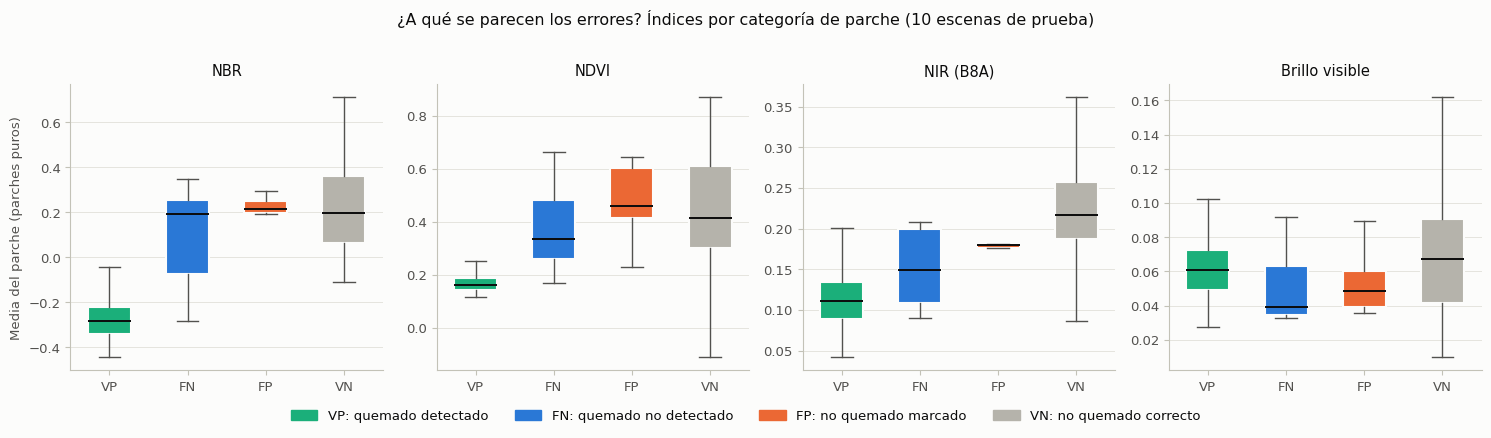

In [25]:
srows = []
for i, (grid, (x, y)) in enumerate(zip(grids, samples['test'])):
    pl = patch_labels(y)
    b = to_grid(y); pure = ((b == 0).sum(-1) == 0) | ((b == 1).sum(-1) == 0)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        means = {k: np.nanmean(to_grid(np.where(y >= 0, v, np.nan)), axis=-1) for k, v in indices(x).items()}
    for r_ in range(14):
        for c_ in range(14):
            if pl[r_, c_] < 0 or not pure[r_, c_]:
                continue
            cat = {(1, 1): 'VP', (1, 0): 'FN', (0, 1): 'FP', (0, 0): 'VN'}[(int(pl[r_, c_]), int(grid[r_, c_]))]
            srows.append({'i': i, 'escena': ids['test'][i], 'cat': cat, **{k: float(v[r_, c_]) for k, v in means.items()}})
spec = pd.DataFrame(srows)
order = ['VP', 'FN', 'FP', 'VN']
names = {'VP': 'VP: quemado detectado', 'FN': 'FN: quemado no detectado', 'FP': 'FP: no quemado marcado', 'VN': 'VN: no quemado correcto'}
resumen_spec = spec.groupby('cat')[['NBR', 'NDVI', 'NBR2', 'NIR (B8A)', 'SWIR2', 'Brillo visible']].median().loc[order]
resumen_spec.insert(0, 'parches', spec.groupby('cat').size().loc[order])
resumen_spec.insert(1, 'escenas', spec.groupby('cat').escena.nunique().loc[order])
display(resumen_spec.round(3))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, k in zip(axes, ['NBR', 'NDVI', 'NIR (B8A)', 'Brillo visible']):
    data = [spec.loc[spec.cat == c, k].values for c in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False, medianprops={'color': C['ink'], 'lw': 1.4},
                    whiskerprops={'color': C['ink2'], 'lw': 1}, capprops={'color': C['ink2'], 'lw': 1})
    for patch_, c in zip(bp['boxes'], order):
        patch_.set_facecolor(C[c]); patch_.set_edgecolor(C['surface']); patch_.set_linewidth(1.5)
    ax.set_xticks(range(1, 5)); ax.set_xticklabels(order); ax.yaxis.grid(True); ax.set_title(k)
axes[0].set_ylabel('Media del parche (parches puros)')
fig.legend(handles=[Patch(color=C[c], label=names[c]) for c in order], loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.07))
fig.suptitle(f'¿A qué se parecen los errores? Índices por categoría de parche ({len(ids["test"])} escenas de prueba)', y=1.02)
fig.tight_layout(); fig.savefig(FIG / '09_firmas_espectrales.png'); plt.show()

In [26]:
# Comparación DENTRO de cada escena. Mezclar escenas puede engañar porque cada una tiene su propio nivel de brillo;
# aquí cada error se compara con los aciertos de su misma escena (diferencia de medianas por píxel).
dentro = []
for i, (grid, (x, y)) in enumerate(zip(grids, samples['test'])):
    pred = up(grid); ix = indices(x)
    fp, vn, fn, vp = (y == 0) & (pred == 1), (y == 0) & (pred == 0), (y == 1) & (pred == 0), (y == 1) & (pred == 1)
    row = {'escena': ids['test'][i], 'px FP': int(fp.sum()), 'px FN': int(fn.sum())}
    for k in ['Brillo visible', 'NIR (B8A)', 'NBR', 'NDVI']:
        if fp.sum() >= 256 and vn.sum() >= 256:      # al menos un parche de cada categoría
            row[f'{k}: FP − VN'] = np.nanmedian(ix[k][fp]) - np.nanmedian(ix[k][vn])
        if fn.sum() >= 256 and vp.sum() >= 256:
            row[f'{k}: FN − VP'] = np.nanmedian(ix[k][fn]) - np.nanmedian(ix[k][vp])
    dentro.append(row)
dentro = pd.DataFrame(dentro)
fpd = dentro.dropna(subset=['NIR (B8A): FP − VN']) if 'NIR (B8A): FP − VN' in dentro else dentro.iloc[:0]
fnd = dentro.dropna(subset=['NBR: FN − VP']) if 'NBR: FN − VP' in dentro else dentro.iloc[:0]
conteo = lambda d, col, signo: int((d[col] * signo > 0).sum()) if col in d else 0
resumen_dentro = pd.DataFrame({
    'escenas comparadas': [len(fpd), len(fnd)],
    'más oscuro en el visible': [conteo(fpd, 'Brillo visible: FP − VN', -1), conteo(fnd, 'Brillo visible: FN − VP', -1)],
    'NIR menor': [conteo(fpd, 'NIR (B8A): FP − VN', -1), conteo(fnd, 'NIR (B8A): FN − VP', -1)],
    'NBR menor': [conteo(fpd, 'NBR: FP − VN', -1), conteo(fnd, 'NBR: FN − VP', -1)],
    'NBR mayor': [conteo(fpd, 'NBR: FP − VN', 1), conteo(fnd, 'NBR: FN − VP', 1)],
    'NDVI mayor': [conteo(fpd, 'NDVI: FP − VN', 1), conteo(fnd, 'NDVI: FN − VP', 1)]},
    index=['FP frente al no quemado bien clasificado (VN)', 'FN frente al quemado detectado (VP)'])
print('Número de escenas en que el error es más oscuro / tiene NBR menor o mayor que los aciertos de su propia escena:')
display(resumen_dentro)
display(fpd[['escena', 'px FP'] + [c for c in fpd.columns if 'FP − VN' in c]].round(3))
display(fnd[['escena', 'px FN'] + [c for c in fnd.columns if 'FN − VP' in c]].round(3))

Número de escenas en que el error es más oscuro / tiene NBR menor o mayor que los aciertos de su propia escena:


,escenas comparadas,más oscuro en el visible,NIR menor,NBR menor,NBR mayor,NDVI mayor
FP frente al no quemado bien clasificado (VN),6,4,6,3,3,2
FN frente al quemado detectado (VP),8,2,0,0,8,7


,escena,px FP,Brillo visible: FP − VN,NIR (B8A): FP − VN,NBR: FP − VN,NDVI: FP − VN
1,T10TGL.2018215,3577,-0.023,-0.036,0.020,0.039
2,T11TQG.2018221,1247,-0.009,-0.012,0.024,0.034
3,T12SUJ.2019308,1964,-0.048,-0.113,0.011,-0.039
4,T14RNV.2018215,373,-0.002,-0.023,-0.063,-0.045
5,T14SKF.2019246,556,0.003,-0.018,-0.109,-0.093
7,T16REV.2019135,1283,0.005,-0.100,-0.392,-0.198


,escena,px FN,Brillo visible: FN − VP,NIR (B8A): FN − VP,NBR: FN − VP,NDVI: FN − VP
0,T10TGK.2020285,1024,0.038,0.079,0.104,0.015
1,T10TGL.2018215,811,0.016,0.036,0.044,0.013
2,T11TQG.2018221,597,0.006,0.027,0.147,0.031
3,T12SUJ.2019308,1536,0.020,0.034,0.034,-0.000
4,T14RNV.2018215,1079,0.017,0.063,0.157,0.027
5,T14SKF.2019246,2317,0.002,0.017,0.097,0.028
8,T16SDC.2018098,3364,-0.003,0.004,0.085,0.048
9,T18SVJ.2020131,2323,-0.001,0.030,0.175,0.079


### F. Control espectral ampliado
Complementa la celda de controles: el mismo Random Forest y las mismas etiquetas, con 15 rasgos (media y desviación de las 6 bandas, más NBR, NDVI y NBR2). Reporta la media por escena con IC95 % y una comparación pareada por escena frente a Prithvi.

,escenas,escenas con IoU definido,IoU media escena,IoU IC95,F1 media escena,F1 IC95,Precisión media escena,Precisión IC95,Recall media escena,Recall IC95,IoU agregado píxel,F1 agregado píxel,Precisión agregado píxel,Recall agregado píxel
método,,,,,,,,,,,,,,
linea_base,10,10,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000–0.000,0.000,0.000,0.000,0.000
control_espectral,10,10,0.567,0.376–0.744,0.669,0.478–0.837,0.796,0.626–0.918,0.622,0.413–0.815,0.751,0.858,0.916,0.807
prithvi_rf,10,10,0.548,0.343–0.738,0.639,0.422–0.831,0.735,0.511–0.921,0.609,0.381–0.817,0.739,0.850,0.910,0.797
oraculo_parche,10,10,0.805,0.756–0.861,0.890,0.859–0.922,0.901,0.879–0.928,0.879,0.839–0.919,0.879,0.936,0.940,0.932


,diferencia media,IC95,escenas donde Prithvi gana
IoU,-0.019471,-0.075 a +0.044,4/10
F1,-0.029841,-0.095 a +0.033,4/10


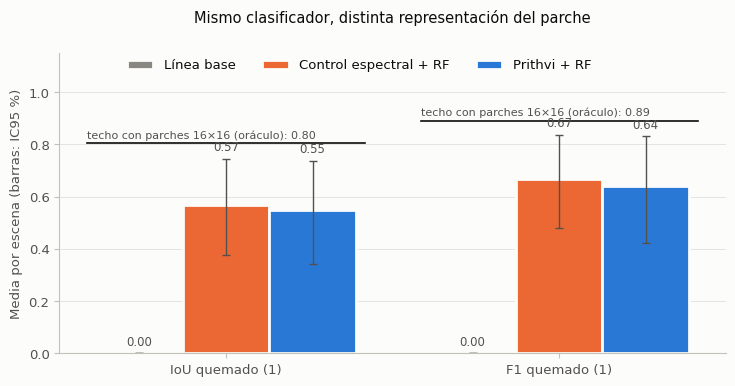

In [27]:
def spectral_features(x_norm, x_raw):
    g = to_grid(x_norm[:, 0])                                   # (6, 14, 14, 256)
    feats = [g.mean(-1), g.std(-1)]
    ix = indices(x_raw)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        for k in ['NBR', 'NDVI', 'NBR2']:
            feats.append(np.nan_to_num(np.nanmean(to_grid(ix[k]), axis=-1))[None])
    return np.concatenate(feats, axis=0).transpose(1, 2, 0)    # (14, 14, 15)

S = {split: [spectral_features(xn, xr) for (xn, _), (xr, _) in zip(prepared[split], samples[split])] for split in ['train', 'test']}
head_spec, _, _ = train_head(S['train'], prepared['train'])
grids_spec = [predict_grid(head_spec, s) for s in S['test']]
per_spec, mats_spec = evaluate(grids_spec, prepared['test'], majority, 'control_espectral')
mats['control_espectral'] = mats_spec['control_espectral']

todo = pd.concat([per_scene, per_spec[per_spec.metodo == 'control_espectral'], orc], ignore_index=True)
comp_tabla = summarize(todo, mats).loc[['linea_base', 'control_espectral', 'prithvi_rf', 'oraculo_parche']]
display(comp_tabla.round(3))

def paired_diff(a, b, B=10000, seed=0):
    d = np.asarray(a, float) - np.asarray(b, float); d = d[np.isfinite(d)]
    idx = np.random.default_rng(seed).integers(0, len(d), size=(B, len(d)))
    lo, hi = np.percentile(d[idx].mean(1), [2.5, 97.5])
    return {'diferencia media': d.mean(), 'IC95': f'{lo:+.3f} a {hi:+.3f}', 'escenas donde Prithvi gana': f'{(d > 0).sum()}/{len(d)}'}
pp = per_scene[per_scene.metodo == 'prithvi_rf'].set_index('i'); ps = per_spec[per_spec.metodo == 'control_espectral'].set_index('i')
display(pd.DataFrame({k: paired_diff(pp[k], ps[k]) for k in ['iou', 'f1']}).T.rename(index={'iou': 'IoU', 'f1': 'F1'}))

fig, ax = plt.subplots(figsize=(8.6, 3.9))
meths = [('linea_base', 'Línea base', C['base']), ('control_espectral', 'Control espectral + RF', C['espectral']), ('prithvi_rf', 'Prithvi + RF', C['modelo'])]
w = 0.26
for k, (name, label, color) in enumerate(meths):
    d = todo[todo.metodo == name]
    means = np.array([d.iou.mean(), d.f1.mean()]); cis = np.array([boot_ci(d.iou), boot_ci(d.f1)])
    xs = np.arange(2) + (k - 1) * w
    ax.bar(xs, means, width=w, color=color, label=label, edgecolor=C['surface'], linewidth=2)
    ax.errorbar(xs, means, yerr=[means - cis[:, 0], cis[:, 1] - means], fmt='none', ecolor=C['ink2'], elinewidth=1, capsize=3)
    for xv, m_, hi in zip(xs, means, cis[:, 1]):
        ax.text(xv, max(hi, m_) + 0.02, f'{m_:.2f}', ha='center', va='bottom', fontsize=8.5, color=C['ink2'])
o_ = todo[todo.metodo == 'oraculo_parche']
for j, val in enumerate([o_.iou.mean(), o_.f1.mean()]):
    ax.plot([j - 1.6 * w, j + 1.6 * w], [val, val], color=C['ink'], lw=1.2)
    ax.text(j - 1.6 * w, val + 0.012, f'techo con parches 16×16 (oráculo): {val:.2f}', va='bottom', ha='left', fontsize=8, color=C['ink2'])
ax.set_xticks([0, 1]); ax.set_xticklabels(['IoU quemado (1)', 'F1 quemado (1)']); ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1.15); ax.yaxis.grid(True); ax.set_ylabel('Media por escena (barras: IC95 %)')
ax.legend(loc='upper center', ncol=3, bbox_to_anchor=(0.45, 1.02)); ax.set_title('Mismo clasificador, distinta representación del parche', pad=22)
fig.savefig(FIG / '10_control_espectral.png'); plt.show()

### G. ¿Se ve la cicatriz en la imagen?
Para cada escena se mide el NBR mediano dentro del área quemada según la referencia, en la escena completa de 512 × 512. Si ese NBR es positivo, la imagen muestra vegetación verde donde la etiqueta dice quemado, y ningún clasificador que vea solo esta imagen puede acertar. Es un análisis exploratorio.

,variable,F1 de,Spearman ρ,p
0,NBR mediana quemado,F1 Prithvi,-0.9758,0.0000
1,NBR mediana quemado,F1 control espectral,-0.9636,0.0000
2,contraste NBR,F1 Prithvi,0.4667,0.1739
3,contraste NBR,F1 control espectral,0.3091,0.3848
4,% del área quemada con NBR < 0,F1 Prithvi,0.6485,0.0425
5,% del área quemada con NBR < 0,F1 control espectral,0.7818,0.0075


,escena,región,fecha,área quemada etiquetada en la escena (km²),NBR mediana quemado,NBR mediana no quemado,contraste NBR,% del área quemada con NBR < 0,F1 Prithvi,F1 control espectral
0,T10TGK.2020285,Oeste,2020-10-11,161.871,-0.295,-0.055,0.241,94.490,0.990,0.995
2,T11TQG.2018221,Oeste,2018-08-09,7.709,-0.289,0.028,0.317,95.937,0.896,0.886
4,T14RNV.2018215,Centro-Este,2018-08-03,5.935,-0.268,0.047,0.315,89.081,0.884,0.861
3,T12SUJ.2019308,Oeste,2019-11-04,13.448,-0.214,0.009,0.223,95.235,0.874,0.875
1,T10TGL.2018215,Oeste,2018-08-03,8.570,-0.181,0.141,0.322,91.084,0.799,0.862
5,T14SKF.2019246,Centro-Este,2019-09-03,4.810,-0.180,0.028,0.208,96.427,0.678,0.777
9,T18SVJ.2020131,Centro-Este,2020-05-10,6.135,0.075,0.401,0.326,34.062,0.787,0.622
8,T16SDC.2018098,Centro-Este,2018-04-08,3.946,0.080,0.272,0.192,22.628,0.377,0.501
6,T15TVN.2019140,Centro-Este,2019-05-20,7.448,0.181,0.250,0.069,12.665,0.000,0.239
7,T16REV.2019135,Centro-Este,2019-05-15,2.777,0.357,0.646,0.289,0.000,0.109,0.076


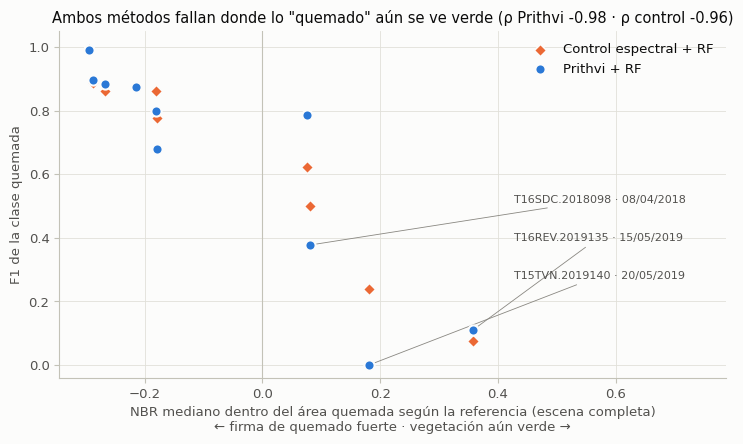

In [28]:
# ¿Se distingue la cicatriz en la imagen? NBR del área quemada según la referencia y su contraste con lo no quemado,
# medidos en la escena 512×512 completa (más píxeles de fondo que el recorte). Solo análisis: usa etiquetas de prueba.
from scipy.stats import spearmanr
vis = []
for i, (im, lab) in enumerate(pairs['test']):
    with rasterio.open(im) as f:
        arr = f.read(masked=True).astype(np.float32).filled(np.nan)
    with rasterio.open(lab) as f:
        yy = f.read(1, masked=True).astype(np.int64).filled(-1)
    with np.errstate(invalid='ignore', divide='ignore'):
        nbr = (arr[3] - arr[5]) / (arr[3] + arr[5])
    nb_q, nb_nq = nbr[(yy == 1) & np.isfinite(nbr)], nbr[(yy == 0) & np.isfinite(nbr)]
    vis.append({'i': i, 'escena': ids['test'][i], 'región': region(ids['test'][i]), 'fecha': doy_to_date(ids['test'][i][7:]),
                'área quemada etiquetada en la escena (km²)': (yy == 1).sum() * 0.0009,
                'NBR mediana quemado': np.median(nb_q), 'NBR mediana no quemado': np.median(nb_nq),
                'contraste NBR': np.median(nb_nq) - np.median(nb_q), '% del área quemada con NBR < 0': 100 * (nb_q < 0).mean()})
vis = pd.DataFrame(vis)
vis['F1 Prithvi'] = m.set_index('i').loc[vis.i, 'f1'].values
vis['F1 control espectral'] = ps.loc[vis.i, 'f1'].values
corr = pd.DataFrame([{'variable': col, 'F1 de': f1c, 'Spearman ρ': spearmanr(vis[col], vis[f1c])[0], 'p': spearmanr(vis[col], vis[f1c])[1]}
                     for col in ['NBR mediana quemado', 'contraste NBR', '% del área quemada con NBR < 0']
                     for f1c in ['F1 Prithvi', 'F1 control espectral']])
display(corr.round(4))
display(vis.drop(columns='i').sort_values('NBR mediana quemado').round(3))

rho_p, rho_c = corr[corr.variable == 'NBR mediana quemado']['Spearman ρ'].values
fig, ax = plt.subplots(figsize=(8.6, 4.5))
ax.scatter(vis['NBR mediana quemado'], vis['F1 control espectral'], marker='D', s=40, color=C['espectral'], edgecolor=C['surface'],
           linewidth=1.2, label='Control espectral + RF', zorder=3)
ax.scatter(vis['NBR mediana quemado'], vis['F1 Prithvi'], marker='o', s=54, color=C['modelo'], edgecolor=C['surface'],
           linewidth=1.5, label='Prithvi + RF', zorder=4)
low = vis[vis['F1 Prithvi'] < 0.4].sort_values(['F1 Prithvi', 'NBR mediana quemado'], ascending=[False, True])
x_text = vis['NBR mediana quemado'].max() + 0.07
for k, (_, r) in enumerate(low.iterrows()):
    ax.annotate(f"{r.escena} · {r.fecha:%d/%m/%Y}", xy=(r['NBR mediana quemado'], r['F1 Prithvi']), xytext=(x_text, 0.52 - 0.12 * k),
                textcoords='data', ha='left', va='center', fontsize=8, color=C['ink2'],
                arrowprops={'arrowstyle': '-', 'color': C['muted'], 'lw': 0.6})
ax.axvline(0, color=C['axis'], lw=0.8)
ax.set_xlim(vis['NBR mediana quemado'].min() - 0.05, x_text + 0.36); ax.set_ylim(-0.04, 1.05); ax.grid(True)
ax.set_xlabel('NBR mediano dentro del área quemada según la referencia (escena completa)\n← firma de quemado fuerte · vegetación aún verde →')
ax.set_ylabel('F1 de la clase quemada'); ax.legend(loc='upper right')
ax.set_title(f'Ambos métodos fallan donde lo "quemado" aún se ve verde (ρ Prithvi {rho_p:.2f} · ρ control {rho_c:.2f})')
fig.savefig(FIG / '10b_visibilidad_cicatriz.png'); plt.show()

# Caso T11SLB.2018197 frente a un incendio documentado (fuentes en el texto): Lions Fire, Ansel Adams Wilderness, 2018
LIONS = {'lat': 37.571, 'lon': -119.118, 'acres_final': 13347, 'acres_2_jul': 4064, 'acres_30_jul': 5095}
if 'T11SLB.2018197' in ids['test']:
    k = ids['test'].index('T11SLB.2018197')
    with rasterio.open(pairs['test'][k][0]) as f:
        b = f.bounds
        lon_c, lat_c = warp_transform(f.crs, 'EPSG:4326', [(b.left + b.right) / 2], [(b.bottom + b.top) / 2])
    v_ = vis[vis.escena == 'T11SLB.2018197'].iloc[0]
    print(f"Distancia entre el centro de la escena y las coordenadas publicadas del Lions Fire: "
          f"{haversine_km(lat_c[0], lon_c[0], LIONS['lat'], LIONS['lon']):.1f} km")
    print(f"Área etiquetada como quemada en la escena 512×512: {v_['área quemada etiquetada en la escena (km²)']:.1f} km² "
          f"| tamaño final del Lions Fire: {LIONS['acres_final'] * 0.00404686:.1f} km²")
    print(f"Área etiquetada con NBR < 0 el {v_.fecha:%d/%m/%Y}: {v_['% del área quemada con NBR < 0']:.0f} % | fracción del tamaño final "
          f"ya quemada: {100 * LIONS['acres_2_jul'] / LIONS['acres_final']:.0f} % (2 jul) a {100 * LIONS['acres_30_jul'] / LIONS['acres_final']:.0f} % (30 jul)")

### H. Curva de aprendizaje: 4 → 10 → 20 escenas de entrenamiento
Responde la pregunta 6 de la sección 8. Los subconjuntos de 4 y 10 escenas son los que entrega el mismo procedimiento de selección (4 era el valor por defecto de la plantilla) y están contenidos en las 20. Para cada tamaño se recalcula todo lo que depende del entrenamiento y se evalúa en las mismas escenas de prueba. La curva es descriptiva y no se usa para escoger nada. Si `NTRAIN` es mayor que 20, ese punto se agrega solo. La sección H2 extiende la curva a 40 y 60 escenas con una corrida local.

,ntrain,metodo,parches_entrenamiento,% parches quemados train,clase_linea_base,iou_media,iou_lo,iou_hi,f1_media,precision_media,recall_media,iou_agregado,f1_agregado
0,4,prithvi_rf,784,63.903,1,0.301,0.170,0.485,0.415,0.303,0.991,0.290,0.450
1,4,control_espectral,784,63.903,1,0.497,0.328,0.670,0.613,0.636,0.662,0.637,0.778
2,4,linea_base,784,63.903,1,0.231,0.119,0.417,0.324,0.231,1.000,0.231,0.375
3,10,prithvi_rf,1960,52.296,1,0.551,0.389,0.706,0.668,0.670,0.714,0.676,0.807
4,10,control_espectral,1960,52.296,1,0.499,0.325,0.678,0.616,0.627,0.704,0.617,0.763
5,10,linea_base,1960,52.296,1,0.231,0.119,0.417,0.324,0.231,1.000,0.231,0.375
6,20,prithvi_rf,3920,37.628,0,0.548,0.343,0.738,0.639,0.735,0.609,0.739,0.850
7,20,control_espectral,3920,37.628,0,0.567,0.376,0.744,0.669,0.796,0.622,0.751,0.858
8,20,linea_base,3920,37.628,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


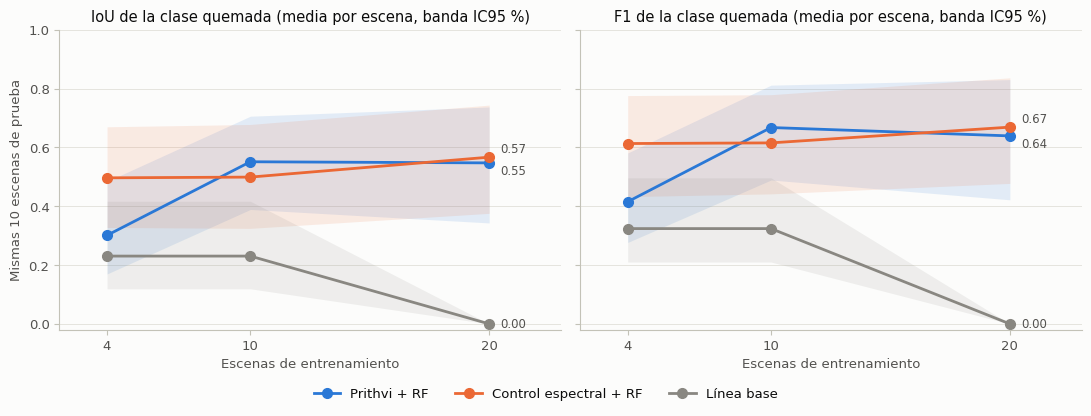

In [29]:
if 'CURVA_IDS' not in globals():   # notebook principal: subconjuntos que entrega el mismo procedimiento (verificados localmente)
    CURVA_IDS = {4: ['T12SUH.2020188', 'T12SVC.2019245', 'T12TUK.2020286', 'T13TCJ.2020200'],
                 10: ['T11TKE.2018215', 'T11TMF.2019312', 'T12SUH.2020188', 'T12SVC.2019245', 'T12SVD.2018168',
                      'T12TUK.2020286', 'T13TCJ.2020200', 'T15RTM.2020059', 'T16RFT.2019250', 'T17RMJ.2018064'],
                 20: list(COLAB_TRAIN)}
    CURVA_IDS[len(ids['train'])] = ids['train']
CURVA_IDS = {n: v for n, v in CURVA_IDS.items() if set(v) <= set(ids['train'])}   # solo tamaños disponibles
curve, curve_scene = [], []
t0 = time.perf_counter()
for n in sorted(CURVA_IDS):
    k = [ids['train'].index(s) for s in CURVA_IDS[n]]
    tr_raw = [samples['train'][j] for j in k]
    if n == len(ids['train']):
        prep_tr, prep_te, Ftr, Fte = [prepared['train'][j] for j in k], prepared['test'], [F['train'][j] for j in k], F['test']
    else:
        m_n, s_n = train_normalization(tr_raw)
        prep_tr = [(normalize(x, m_n, s_n), y) for x, y in tr_raw]
        prep_te = [(normalize(x, m_n, s_n), y) for x, y in samples['test']]
        Ftr, Fte = extract(prep_tr), extract(prep_te)
    maj_n, cnt_n = train_majority(tr_raw)
    h_n, _, Y_n = train_head(Ftr, prep_tr)
    d_p, mt_p = evaluate([predict_grid(h_n, f) for f in Fte], prep_te, maj_n, 'prithvi_rf')
    Str = [spectral_features(xn, xr) for (xn, _), (xr, _) in zip(prep_tr, tr_raw)]
    Ste = [spectral_features(xn, xr) for (xn, _), (xr, _) in zip(prep_te, samples['test'])]
    hs_n, _, _ = train_head(Str, prep_tr)
    d_s, mt_s = evaluate([predict_grid(hs_n, s) for s in Ste], prep_te, maj_n, 'control_espectral')
    allm = pd.concat([d_p, d_s[d_s.metodo == 'control_espectral']], ignore_index=True)
    allmats = {**mt_p, 'control_espectral': mt_s['control_espectral']}
    for name in ['prithvi_rf', 'control_espectral', 'linea_base']:
        d = allm[allm.metodo == name]; pooled = metrics(sum(allmats[name]), CLASSES)[1]
        row = {'ntrain': n, 'metodo': name, 'parches_entrenamiento': len(Y_n), '% parches quemados train': 100 * (Y_n == 1).mean(),
               'clase_linea_base': maj_n, 'iou_agregado': pooled['iou'], 'f1_agregado': pooled['f1']}
        for met in ['iou', 'f1', 'precision', 'recall']:
            lo, hi = boot_ci(d[met]); row.update({f'{met}_media': d[met].mean(), f'{met}_lo': lo, f'{met}_hi': hi})
        curve.append(row)
    curve_scene.append(allm.assign(ntrain=n))
TIMES['curva_aprendizaje_s'] = time.perf_counter() - t0
cv = pd.DataFrame(curve)
display(cv[['ntrain', 'metodo', 'parches_entrenamiento', '% parches quemados train', 'clase_linea_base', 'iou_media', 'iou_lo', 'iou_hi',
            'f1_media', 'precision_media', 'recall_media', 'iou_agregado', 'f1_agregado']].round(3))

SERIES = [('prithvi_rf', 'Prithvi + RF', C['modelo']), ('control_espectral', 'Control espectral + RF', C['espectral']),
          ('linea_base', 'Línea base', C['base'])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, met, lab in zip(axes, ['iou', 'f1'], ['IoU', 'F1']):
    ends = {name: cv[cv.metodo == name].iloc[-1][f'{met}_media'] for name, _, _ in SERIES}
    top = max(['prithvi_rf', 'control_espectral'], key=ends.get)
    for name, label, color in SERIES:
        d = cv[cv.metodo == name]
        ax.plot(d.ntrain, d[f'{met}_media'], color=color, lw=2, marker='o', ms=7, label=label)
        ax.fill_between(d.ntrain, d[f'{met}_lo'], d[f'{met}_hi'], color=color, alpha=0.12, lw=0)
        dy = 0 if name == 'linea_base' else (6 if name == top else -6)
        ax.annotate(f'{ends[name]:.2f}', (d.ntrain.iloc[-1], ends[name]), xytext=(8, dy),
                    textcoords='offset points', va='center', fontsize=8.5, color=C['ink2'])
    ax.set_xticks(sorted(CURVA_IDS)); ax.set_xlim(min(CURVA_IDS) - 2, max(CURVA_IDS) * 1.15); ax.set_ylim(-0.02, 1.0)
    ax.set_xlabel('Escenas de entrenamiento'); ax.set_title(f'{lab} de la clase quemada (media por escena, banda IC95 %)'); ax.yaxis.grid(True)
axes[0].set_ylabel(f'Mismas {len(ids["test"])} escenas de prueba')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); fig.savefig(FIG / '11_curva_aprendizaje.png'); plt.show()

### H2. Más imágenes de entrenamiento: 40 y 60 escenas (corrida local)
Extiende la curva de la sección H. El mismo flujo se corrió con 4, 10, 20, 40 y 60 escenas de entrenamiento en un portátil sin GPU, y siempre se evaluó en las mismas 20 escenas de prueba. El cuaderno es `analisis_local/curva_mas_imagenes.ipynb` y tardó menos de 5 min en total. La celda siguiente no vuelve a entrenar: grafica los valores medidos en esa corrida, para no alargar la ejecución en Colab.
- La primera gráfica muestra cómo cambian el F1, la IoU, la precisión y el recall de Prithvi + RF.
- La segunda compara Prithvi con el control espectral, con su IC95 % y el techo por bloques.

La interpretación está en "Análisis de resultados", en el bloque «Más imágenes de entrenamiento».

,f1,iou,precision,recall,f1_agregado,iou_agregado
ntrain,,,,,,
4,0.425,0.316,0.317,0.993,0.478,0.314
10,0.587,0.470,0.599,0.702,0.695,0.532
20,0.633,0.524,0.746,0.604,0.747,0.596
40,0.663,0.542,0.774,0.652,0.772,0.629
60,0.704,0.578,0.813,0.699,0.796,0.662


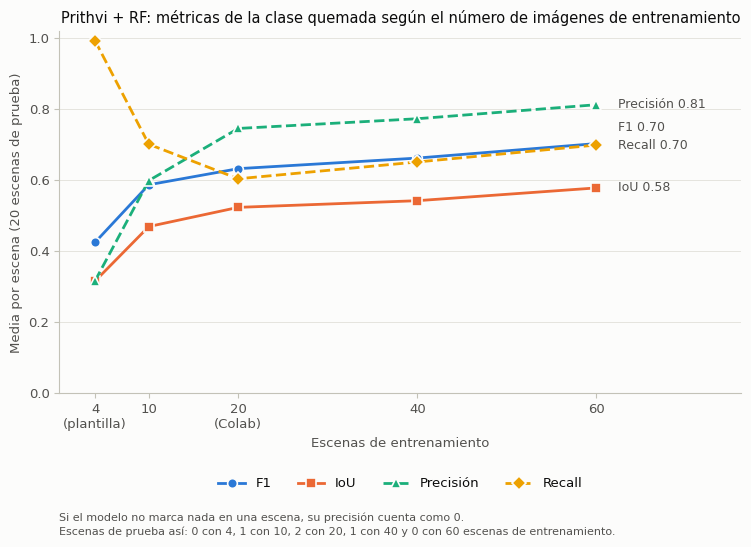

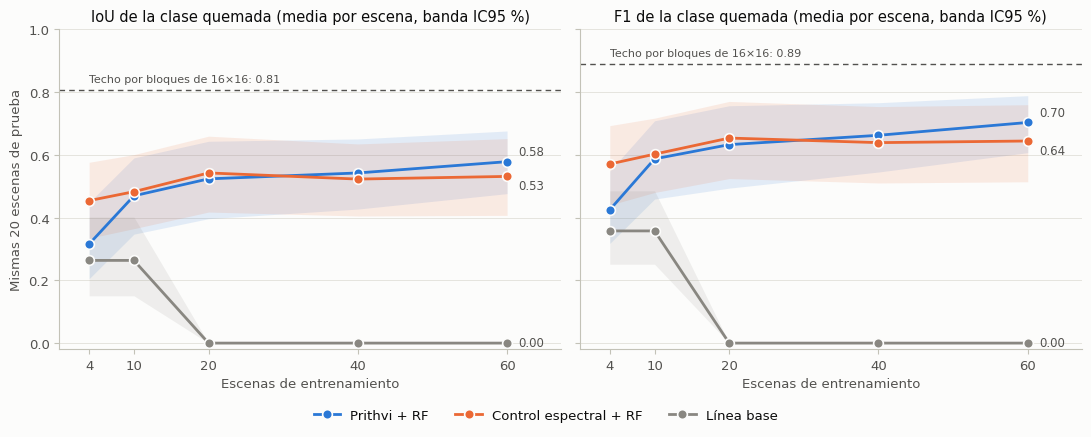

In [30]:
# Curva con más imágenes de entrenamiento: valores medidos en la corrida local (analisis_local/curva_mas_imagenes.ipynb).
# Esta celda no vuelve a entrenar: solo grafica esos valores, para no alargar la corrida en Colab.
# Todos los puntos usan las mismas 20 escenas de prueba. Valores: media por escena de la clase quemada;
# _lo y _hi = IC95 % por bootstrap de escenas; _agregado = agregado por píxel (complemento);
# escenas_sin_prediccion = escenas de prueba donde el método no marcó ningún píxel como quemado.
import io
CURVA_LOCAL = pd.read_csv(io.StringIO("""
ntrain,metodo,f1,f1_lo,f1_hi,iou,iou_lo,iou_hi,precision,precision_lo,precision_hi,recall,recall_lo,recall_hi,f1_agregado,iou_agregado,escenas_sin_prediccion
4,prithvi_rf,0.4252,0.3179,0.5486,0.3159,0.2054,0.4484,0.3168,0.2062,0.4498,0.9932,0.9863,0.9985,0.4778,0.3139,0
4,control_espectral,0.5710,0.4401,0.6934,0.4543,0.3343,0.5765,0.5758,0.4348,0.7112,0.6897,0.5371,0.8288,0.6667,0.5000,2
4,linea_base,0.3577,0.2515,0.4854,0.2637,0.1509,0.4019,0.2637,0.1509,0.4019,1.0000,1.0000,1.0000,0.4168,0.2633,0
10,prithvi_rf,0.5874,0.4593,0.7088,0.4696,0.3474,0.5905,0.5992,0.4599,0.7319,0.7016,0.5498,0.8370,0.6949,0.5325,1
10,control_espectral,0.6025,0.4802,0.7172,0.4828,0.3649,0.6009,0.6179,0.4742,0.7534,0.7053,0.5689,0.8241,0.7181,0.5602,1
10,linea_base,0.3577,0.2515,0.4854,0.2637,0.1509,0.4019,0.2637,0.1509,0.4019,1.0000,1.0000,1.0000,0.4168,0.2633,0
20,prithvi_rf,0.6328,0.4941,0.7568,0.5237,0.3967,0.6435,0.7461,0.6010,0.8744,0.6043,0.4551,0.7429,0.7472,0.5964,2
20,control_espectral,0.6538,0.5247,0.7706,0.5426,0.4179,0.6598,0.7508,0.6184,0.8634,0.6455,0.4998,0.7801,0.7563,0.6081,1
20,linea_base,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,20
40,prithvi_rf,0.6626,0.5455,0.7665,0.5425,0.4274,0.6510,0.7735,0.6566,0.8741,0.6516,0.5135,0.7814,0.7723,0.6291,1
40,control_espectral,0.6392,0.5106,0.7541,0.5230,0.4052,0.6350,0.6806,0.5378,0.8087,0.6576,0.5175,0.7856,0.7472,0.5964,1
40,linea_base,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,20
60,prithvi_rf,0.7035,0.6072,0.7890,0.5785,0.4766,0.6764,0.8130,0.7369,0.8837,0.6994,0.5753,0.8112,0.7965,0.6618,0
60,control_espectral,0.6444,0.5144,0.7601,0.5315,0.4073,0.6519,0.6740,0.5313,0.8072,0.6894,0.5491,0.8137,0.7672,0.6224,1
60,linea_base,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,20
"""))
TECHO_LOCAL = {'iou': np.float64(0.8058), 'f1': np.float64(0.8898)}   # techo por bloques de 16×16 en esas 20 escenas (no depende del entrenamiento)
CURVA_LOCAL.to_csv(OUT / 'complementario_curva_mas_imagenes_local.csv', index=False)
display(CURVA_LOCAL[CURVA_LOCAL.metodo == 'prithvi_rf'].set_index('ntrain')[['f1', 'iou', 'precision', 'recall', 'f1_agregado', 'iou_agregado']].round(3))

NT = sorted(CURVA_LOCAL.ntrain.unique())
TICKS = {4: '4\n(plantilla)', 20: '20\n(Colab)'}

# Gráfica 1: cómo cambian las cuatro métricas de Prithvi + RF
MET = [('f1', 'F1', '#2a78d6', '-', 'o'), ('iou', 'IoU', '#eb6834', '-', 's'),
       ('precision', 'Precisión', '#1baf7a', '--', '^'), ('recall', 'Recall', '#eda100', '--', 'D')]
p = CURVA_LOCAL[CURVA_LOCAL.metodo == 'prithvi_rf'].set_index('ntrain')
fig, ax = plt.subplots(figsize=(8.8, 4.7))
for met, lab, col, ls, mk in MET:
    ax.plot(p.index, p[met], color=col, lw=2, ls=ls, marker=mk, ms=7, label=lab,
            markeredgecolor=C['surface'], markeredgewidth=1.2, zorder=3)
ends = {lab: p[met].iloc[-1] for met, lab, *_ in MET}
ypos, last = {}, -1.0
for lab in sorted(ends, key=ends.get):              # etiquetas al final de cada línea, sin encimarse
    ypos[lab] = max(ends[lab], last + 0.05); last = ypos[lab]
for lab, v in ends.items():
    ax.annotate(f'{lab} {v:.2f}', (p.index[-1], v), xytext=(p.index[-1] * 1.04, ypos[lab]),
                textcoords='data', va='center', fontsize=9, color=C['ink2'])
ax.set_xticks(NT); ax.set_xticklabels([TICKS.get(n, str(n)) for n in NT])
ax.set_xlim(0, p.index[-1] * 1.27); ax.set_ylim(0, 1.02); ax.yaxis.grid(True)
ax.set_xlabel('Escenas de entrenamiento'); ax.set_ylabel('Media por escena (20 escenas de prueba)')
ax.set_title('Prithvi + RF: métricas de la clase quemada según el número de imágenes de entrenamiento')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
partes = [f'{int(v)} con {n}' for n, v in p['escenas_sin_prediccion'].items()]
ax.text(0, -0.33, 'Si el modelo no marca nada en una escena, su precisión cuenta como 0.\nEscenas de prueba así: '
        + ', '.join(partes[:-1]) + f' y {partes[-1]} escenas de entrenamiento.',
        transform=ax.transAxes, va='top', fontsize=8, color=C['ink2'], linespacing=1.4)
fig.savefig(FIG / '12_metricas_segun_imagenes.png'); plt.show()

# Gráfica 2: Prithvi frente a las bandas solas, con IC95 % y el techo por bloques
SERIES = [('prithvi_rf', 'Prithvi + RF', C['modelo']), ('control_espectral', 'Control espectral + RF', C['espectral']),
          ('linea_base', 'Línea base', C['base'])]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), sharey=True)
for ax, met, lab in zip(axes, ['iou', 'f1'], ['IoU', 'F1']):
    ax.axhline(TECHO_LOCAL[met], color=C['ink2'], lw=1, ls=(0, (4, 3)))
    ax.text(NT[0], TECHO_LOCAL[met] + 0.02, f'Techo por bloques de 16×16: {TECHO_LOCAL[met]:.2f}', fontsize=8, color=C['ink2'], va='bottom')
    ends = {name: CURVA_LOCAL[CURVA_LOCAL.metodo == name].iloc[-1][met] for name, _, _ in SERIES}
    top = max(['prithvi_rf', 'control_espectral'], key=ends.get)
    for name, label, color in SERIES:
        d = CURVA_LOCAL[CURVA_LOCAL.metodo == name]
        ax.plot(d.ntrain, d[met], color=color, lw=2, marker='o', ms=7, label=label, markeredgecolor=C['surface'], markeredgewidth=1.2)
        ax.fill_between(d.ntrain, d[f'{met}_lo'], d[f'{met}_hi'], color=color, alpha=0.12, lw=0)
        dy = 0 if name == 'linea_base' else (7 if name == top else -7)
        ax.annotate(f'{ends[name]:.2f}', (d.ntrain.iloc[-1], ends[name]), xytext=(8, dy),
                    textcoords='offset points', va='center', fontsize=8.5, color=C['ink2'])
    ax.set_xticks(NT); ax.set_xlim(0, max(NT) * 1.12); ax.set_ylim(-0.02, 1.0)
    ax.set_xlabel('Escenas de entrenamiento'); ax.set_title(f'{lab} de la clase quemada (media por escena, banda IC95 %)')
    ax.yaxis.grid(True)
axes[0].set_ylabel('Mismas 20 escenas de prueba')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); fig.savefig(FIG / '13_prithvi_vs_bandas_segun_imagenes.png'); plt.show()

In [31]:
# Guardar las tablas del análisis complementario (quedan dentro del ZIP de evidencias)
todo.to_csv(OUT / 'complementario_metricas_por_escena.csv', index=False)
comp_tabla.to_csv(OUT / 'complementario_resumen_metodos.csv')
dec_scene.to_csv(OUT / 'complementario_origen_errores_por_escena.csv', index=False)
rate.to_csv(OUT / 'complementario_error_vs_distancia_borde.csv')
frag.to_csv(OUT / 'complementario_fragmentos.csv')
dentro.to_csv(OUT / 'complementario_errores_vs_aciertos_misma_escena.csv', index=False)
vis.to_csv(OUT / 'complementario_visibilidad_cicatriz.csv', index=False)
cv.to_csv(OUT / 'complementario_curva_aprendizaje.csv', index=False)
pd.concat(curve_scene, ignore_index=True).to_csv(OUT / 'complementario_curva_aprendizaje_por_escena.csv', index=False)
print(sorted(p.name for p in OUT.glob('complementario_*')))

['complementario_curva_aprendizaje.csv', 'complementario_curva_aprendizaje_por_escena.csv', 'complementario_curva_mas_imagenes_local.csv', 'complementario_error_vs_distancia_borde.csv', 'complementario_errores_vs_aciertos_misma_escena.csv', 'complementario_fragmentos.csv', 'complementario_metricas_por_escena.csv', 'complementario_origen_errores_por_escena.csv', 'complementario_resumen_metodos.csv', 'complementario_visibilidad_cicatriz.csv']


## Análisis de errores

En las figuras de la sección 7, azul claro es quemado, azul oscuro es no quemado y el rojo marca los píxeles donde la predicción no coincide con la referencia. El análisis complementario (sección C) agrega mapas con aciertos (VP), falsos positivos (FP) y falsos negativos (FN) en colores distintos, y elige los casos con una regla fija: el de mayor F1 (escena 0), el de más FP (escena 1) y el de más FN (escena 6).

**Patrón general.** Las escenas del oeste de Estados Unidos (0 a 3, zonas UTM 10 a 12) salen bien: cicatrices oscuras sobre terreno seco y claro. Los fallos grandes están en escenas del centro y el este (6, 7 y 8, zonas 15 y 16), tomadas en abril y mayo, con más vegetación verde y agua alrededor. Por región (sección B), las 4 escenas del oeste tienen un F1 medio de 0,89 y las 6 del centro y el este, de 0,47; tres de estas seis quedan por debajo de 0,4. En entrenamiento solo 6 de las 20 escenas son de esa parte del país. Con 10 escenas de prueba esto es una observación y no una conclusión, pero en la prueba ampliada de 20 escenas el patrón se repite (0,76 en el oeste frente a 0,48 en el centro y el este).

**Caso 1, acierto: escena 2 (T11TQG, 9 ago 2018).** La cicatriz es oscura y compacta sobre un terreno claro. El modelo encuentra el cuerpo de la cicatriz y el error queda reducido a una franja en el borde, que se explica por los bloques de 16 píxeles. F1 de la escena: 0,896. (La regla automática elige la escena 0, con F1 0,990, pero esa escena está toda quemada y no tiene bordes que evaluar.)

**Caso 2, falso negativo: escena 6 (T15TVN, 20 may 2019).** El modelo no marca nada como quemado y pierde toda la cicatriz. F1 de la escena: 0,000. En la imagen RGB el área quemada no es negra: se ve café y blanquecina, rodeada de agua y vegetación verde. El NBR mediano dentro del perímetro es +0,18 y el del fondo +0,25 (sección G): la cicatriz casi no se distingue en NBR, así que la imagen no muestra la firma típica de un área quemada. Posibles razones: (a) hay pocos paisajes así en entrenamiento; (b) puede tratarse de pastizal o humedal quemado, que rebrota rápido y se ve muy distinto a un bosque calcinado; (c) no sabemos cuánto tiempo pasó entre el incendio y la imagen. Con 60 escenas de entrenamiento, el modelo ya detecta parte de esta cicatriz (F1 de 0,58 en la prueba ampliada), lo que apoya la razón (a). Aun así, el resultado de esta escena cambia mucho según qué escenas entran al entrenamiento (sección H2). Las escenas 7 y 8 muestran algo parecido: el modelo solo marca uno o dos bloques dentro de cicatrices grandes (F1 de 0,11 y 0,38).

**Caso 3, falso positivo: escena 1 (T10TGL, 3 ago 2018).** Además de la cicatriz, el modelo marca varios bloques a la izquierda que en la referencia no están quemados. F1 de la escena: 0,799, con 3.577 píxeles FP. Coinciden con laderas oscuras de montaña, que es justo el tipo de confusión que pide revisar la ficha (superficies oscuras y sombras). Al compararlos con el fondo bien clasificado de la misma escena (sección E), los bloques marcados por error son más oscuros (brillo visible −0,023; NIR −0,036) pero tienen casi el mismo NBR (+0,020). Esa es la firma de una sombra, que oscurece todas las bandas a la vez. En la escena 3 pasa lo mismo, de forma más marcada (brillo −0,048; NIR −0,113; NBR +0,011). En la escena 5, los bloques junto a los lotes agrícolas tienen NBR −0,109 y NDVI −0,093 frente a su entorno, lo que apunta a suelo descubierto o vegetación rala. En la escena 7, dentro de un bosque denso, el bloque falso tiene un NBR 0,39 más bajo que su entorno muy verde: es un claro o un terreno con menos vegetación. En las 6 escenas con suficientes FP para comparar, todos tienen un NIR menor que su entorno.

**Bordes y fragmentos pequeños.** En todas las escenas el error se concentra en el contorno, porque cada bloque representa 480 × 480 m. Las partes angostas de una cicatriz, como la lengua de la izquierda en la escena 3, se pierden o quedan en escalera. De los 32.574 píxeles mal clasificados, el 77 % está en bloques de borde y el 31 % es inevitable con bloques de 16 × 16 (sección D). El 72 % de los FN y el 59 % de los FP están a 240 m o menos del borde de la cicatriz. En estas 10 escenas la referencia no tiene cicatrices menores que un bloque (23 ha): el dataset viene de perímetros de incendios grandes, así que con estos datos no se puede evaluar la detección de fragmentos pequeños.

**Escena 0.** El recorte quedó completamente dentro de la cicatriz, así que la referencia es 100 % quemado. El modelo acierta casi todo y solo deja cuatro bloques sin marcar. Una escena así sube el F1 global sin decir mucho sobre la capacidad de encontrar bordes. Además, la máscara marca como quemadas zonas que en la imagen se ven claras: la referencia es el perímetro del incendio (MTBS) [7], [15] y no cada píxel quemado. En las 8 escenas donde se puede comparar, lo que el modelo deja sin marcar tiene un NBR mayor que lo que sí detecta (sección E): dentro del perímetro hay zonas poco quemadas o sin quemar.

**¿De dónde viene cada error?**

| Tipo | Ejemplos en nuestros resultados |
|---|---|
| Falla del modelo o del método | Bordes en escalera por los bloques de 16 × 16 (techo de IoU 0,81); cabeza entrenada con solo 20 escenas (con 60, el F1 por escena sube de 0,63 a 0,70 en la prueba ampliada); normalización distinta a la del preentrenamiento; confusión con sombras y vegetación rala |
| Limitación de las etiquetas | La referencia es el perímetro del incendio e incluye zonas internas que se ven sin quemar (escena 0). En la prueba ampliada, la escena T11SLB tiene como referencia el perímetro final de un incendio que seguía activo en la fecha de la imagen |
| Calidad de los datos | Nubes pequeñas en la escena 4 y bruma en la escena 1; en estos casos el modelo no se confundió de forma visible |
| Desplazamiento de dominio | Escenas del este y de primavera (6, 7, 8) con paisajes poco representados en entrenamiento: F1 de 0,47 en el centro y el este frente a 0,89 en el oeste. Al entrenar con 60 escenas (22 de esa región), el F1 del centro y el este sube de 0,48 a 0,61 en la prueba ampliada, lo que apoya esta causa |

## Preguntas de análisis de la ficha

**1. ¿Por qué una región oscura no es evidencia suficiente de un incendio?**
Muchas cosas se ven oscuras en una imagen a color: agua, sombras de montaña, suelo húmedo, roca volcánica, bosque muy denso o asfalto. En nuestros resultados el modelo marcó como quemadas laderas oscuras en la escena 1 que no lo estaban. La comparación dentro de cada escena lo confirma: en las 6 escenas con suficientes falsos positivos, las zonas marcadas por error tienen un NIR menor que su entorno (sección E y figura de casos de la sección C). Para afirmar que algo se quemó hace falta mirar cómo se comporta en NIR y SWIR y, mejor aún, compararlo con una imagen de antes del incendio.

**2. ¿Qué información aportan NIR y SWIR?**
La vegetación sana refleja mucho NIR por la estructura interna de las hojas. Cuando se quema, esa reflectancia cae. En SWIR pasa lo contrario: la zona quemada refleja más porque hay menos agua en la vegetación y queda suelo y ceniza al descubierto. Por eso el índice NBR, que combina NIR y SWIR2, baja mucho después de un incendio [10]. En las 10 escenas de prueba, lo detectado como quemado tiene un NBR mediano de −0,29 y el fondo bien clasificado, de +0,20 (figura de firmas espectrales, sección E); en las 20 escenas del análisis local las medianas son −0,25 y +0,13, con la misma separación. Estas bandas también ayudan a separar la cicatriz del agua (el agua es oscura en NIR y en SWIR) y de la sombra (en la sombra bajan todas las bandas a la vez y el NBR casi no cambia).

**3. ¿Cómo influye el tiempo transcurrido desde el incendio?**
Justo después del incendio hay carbón y ceniza, y la señal es fuerte. Con las semanas, la lluvia lava la ceniza y en pastizales la vegetación rebrota rápido, así que la cicatriz se va borrando. En bosques puede notarse por años. El dataset trae la fecha de la imagen pero no la del incendio. Aun así, hay dos evidencias (sección G y análisis local): (a) el F1 por escena cae cuando el área etiquetada como quemada tiene NBR positivo, es decir, cuando ya se ve verde (Spearman ρ = −0,98 en estas 10 escenas y −0,74 en las 20 del análisis local); (b) en la prueba ampliada, la escena T11SLB (16 jul 2018) coincide con el *Lions Fire* de la Sierra Nevada, que empezó el 11 jun 2018 y siguió creciendo hasta agosto [17], [18]. Su área etiquetada (57,7 km²) tiene el tamaño final del incendio (54 km²), pero en la fecha de la imagen solo el 18 % tenía firma de quemado: la etiqueta describe el final del incendio y la imagen, un momento intermedio.

**4. ¿Qué diferencia hay entre delimitar área quemada, estimar severidad y detectar fuego activo?**
- *Área quemada* (lo que hicimos): un mapa de sí o no de dónde ardió, hecho con una imagen posterior al evento.
- *Severidad*: cuánto daño sufrieron la vegetación y el suelo. Normalmente se calcula con el cambio entre imágenes de antes y después (por ejemplo, el dNBR) y se valida en campo [10].
- *Fuego activo*: detectar dónde hay fuego en el momento en que pasa el satélite, con bandas térmicas que miden calor (por ejemplo, MODIS o VIIRS). Nuestro modelo no ve temperatura, solo luz reflejada, así que no puede decir si algo está ardiendo (ver "Lo que el modelo no hace" en la Descripción del problema).

## Transferencia: adaptación a Colombia

**Aclaración:** no usamos datos colombianos. Esto es una propuesta y no está validada.

**Por qué no se puede usar tal cual.** El modelo se preentrenó y la cabeza se entrenó con imágenes de Estados Unidos. Colombia tiene otros paisajes: sabanas de la Orinoquía donde las quemas son frecuentes y el pasto rebrota rápido, bosques andinos, páramos, bosque húmedo amazónico y zonas secas del Caribe. Además hay mucha nubosidad en buena parte del año y relieve fuerte con sombras. Ya en nuestro subconjunto el modelo funcionó peor fuera del paisaje que más vio en entrenamiento, así que es de esperar que pase lo mismo aquí.

**Datos y etiquetas adicionales.**
- Imágenes HLS o Sentinel-2 de incendios colombianos conocidos, con una imagen antes y otra después de cada evento.
- Etiquetas locales trazadas por personas sobre esas imágenes, apoyadas en puntos de calor de FIRMS para ubicar dónde y cuándo hubo fuego, y revisadas con entidades que siguen incendios (IDEAM, Parques Nacionales, corporaciones autónomas regionales). El IDEAM tiene un protocolo para hacer mapas de zonificación de riesgo a incendios de la cobertura vegetal a escala 1:100.000 [19], que clasifica la cobertura con la leyenda CORINE Land Cover adaptada para Colombia [20]. Esa misma leyenda sirve para estratificar la validación por tipo de cobertura (sabana, bosque, páramo, cultivo).
- Productos globales de área quemada como MODIS MCD64A1 [11] sirven de referencia gruesa (500 m), pero no reemplazan etiquetas a 30 m.

**Cambios en el contrato de entrada.** Mantener las mismas 6 bandas y la misma escala. Agregar una segunda fecha antes del incendio (Prithvi acepta varias fechas). Marcar nubes y sombras de nube como −1 usando la máscara de calidad de HLS, para que no cuenten como fondo.

**Estrategia de adaptación.**
1. Evaluar primero el modelo actual en escenas colombianas etiquetadas, sin reentrenar, para medir cuánto cae el desempeño.
2. Reentrenar solo la cabeza con datos locales.
3. Si los datos alcanzan, pasar a una cabeza de segmentación por píxel o a un ajuste fino ligero, por ejemplo con Prithvi-EO-2.0 y TerraTorch [2], [12].

**Partición y validación.** Separar por evento y por región: los píxeles de un mismo incendio nunca pueden quedar en entrenamiento y prueba a la vez. Lo ideal es dejar regiones completas para prueba (por ejemplo, entrenar con la Orinoquía y probar en la región Andina). Reportar IoU y F1 de la clase quemada por evento y por región, comparar con la línea base constante y con un índice simple como dNBR con umbral elegido en entrenamiento, y revisar en campo una muestra de los mapas.

**Riesgos y mitigación.**

| Riesgo | Mitigación |
|---|---|
| Nubes y pocas imágenes despejadas | Usar varias fechas, marcar nubes como dato faltante, aceptar que algunas zonas quedan sin mapa |
| Confundir quemas agrícolas con incendios | No atribuir causas; reportar solo área afectada |
| Perder incendios pequeños | Declarar el tamaño mínimo que el método puede ver (hoy bloques de 480 m) |
| Rebrote rápido en sabanas | Usar imágenes cercanas a la fecha del incendio |
| Etiquetas que no coinciden con la fecha de la imagen (por ejemplo, un perímetro final sobre una imagen de mitad del incendio) | Emparejar cada etiqueta con imágenes de fecha conocida y revisar el NBR dentro del perímetro antes de entrenar |
| Usarlo como producto oficial sin validar | Dejar claro que es una herramienta de apoyo y que la decisión es de las autoridades |

### Extra: contrato de entrada y plan de validación para Colombia

Esta sección es un **complemento** de la propuesta anterior. No usa datos colombianos ni los entrena; deja explícito qué cambiaría en la práctica.

**Contrato de entrada: qué se mantiene y qué cambia**

| Aspecto | Contrato de este trabajo (HLS Burn Scars) | Contrato propuesto para Colombia |
|---|---|---|
| Bandas y orden | 6 bandas: azul, verde, rojo, NIR (B8A), SWIR1, SWIR2 | Igual. No se reordena ni se agregan bandas |
| Escala | Reflectancia HLS, normalizada con media y desviación de entrenamiento | Igual, pero con la media y desviación **de entrenamiento original**: no se recalculan con datos colombianos de prueba |
| Fechas por muestra | 1 (posterior al incendio) | 2: una antes y una después del evento (permite dNBR y severidad aproximada) |
| Tamaño | Recorte central de 224 × 224 píxeles a 30 m | Igual |
| Valor para dato no válido | −1 en la etiqueta (ignorado en métricas) | Igual, y además **nube, sombra de nube y agua** de la máscara de calidad de HLS pasan a −1 |
| Etiqueta | Perímetro MTBS (1 = quemado, 0 = no quemado) | Polígonos locales con **fecha del evento y fecha de la imagen** registradas |
| Metadatos obligatorios | Escena y fecha de la imagen | Escena, fecha de imagen, fecha estimada del incendio, región y tipo de cobertura (CORINE adaptada) |

**Etapas de validación, de la más barata a la más costosa**

| Etapa | Qué se hace | Qué se aprende | Criterio para pasar a la siguiente |
|---|---|---|---|
| 0. Sin reentrenar | Evaluar el modelo actual y el control NBR en escenas colombianas etiquetadas | Cuánto cae el desempeño al cambiar de país | Se reporta, no hay umbral: es la línea de referencia |
| 1. Umbral local | Elegir de nuevo el umbral de NBR (o dNBR) con escenas colombianas de entrenamiento | Si una regla simple recupera el desempeño | IoU por evento mayor que la línea base constante en todas las regiones |
| 2. Cabeza local | Reentrenar solo el Random Forest sobre el encoder congelado, con partición por evento | Si Prithvi aporta algo sobre el control espectral | Supera al control NBR con IC95 que no incluya 0 |
| 3. Ajuste ligero | Solo si hay suficientes escenas: cabeza por píxel o ajuste fino ligero (Prithvi-EO-2.0, TerraTorch) | Si se puede romper el techo de bloques de 480 m | Mejora sobre la etapa 2 en bordes y fragmentos pequeños |

**Partición:** por **evento** y por **región** (por ejemplo, entrenar con Orinoquía y Caribe y probar en la región Andina). Los píxeles de un mismo incendio nunca están a la vez en entrenamiento y prueba. Se reporta IoU y F1 de la clase quemada por evento, con la media por evento como métrica principal.

**Qué no se debe afirmar:** causas del incendio, severidad ecológica o fuego activo (ver "Lo que el modelo no hace"). Un mapa del modelo se publica siempre con la fecha de la imagen y la fecha de la etiqueta.

In [32]:
# Extra Colombia: el contrato de entrada propuesto como código verificable.
# Con los datos actuales debe FALLAR en 'fechas' (hoy hay 1 fecha por escena): es el cambio que haría falta.
CONTRATO_COLOMBIA = {'bandas': 6, 'fechas': 2, 'lado': 224, 'valor_invalido': -1, 'max_fraccion_invalida': 0.4}

def validar_contrato(raw, y, contrato=CONTRATO_COLOMBIA):
    b, t, h, w = raw.shape
    fraccion = float((y < 0).mean())
    chequeos = {
        'bandas': b == contrato['bandas'],
        'fechas': t == contrato['fechas'],
        'lado': (h, w) == (contrato['lado'], contrato['lado']),
        'etiqueta alineada': y.shape == (h, w),
        'fracción inválida aceptable': fraccion <= contrato['max_fraccion_invalida'],
    }
    return chequeos, fraccion

filas = []
for split in ['train', 'test']:
    for i, (raw, y) in enumerate(samples[split]):
        chequeos, fraccion = validar_contrato(raw, y)
        filas.append({'split': split, 'escena': i, 'fracción inválida': round(fraccion, 3), **chequeos})
contrato_df = pd.DataFrame(filas)
contrato_df.to_csv(OUT/'verificacion_contrato_colombia.csv', index=False)
print('Escenas que cumplen cada punto del contrato de Colombia (de', len(contrato_df), '):')
print(contrato_df.drop(columns=['split', 'escena', 'fracción inválida']).sum().to_string())


Escenas que cumplen cada punto del contrato de Colombia (de 30 ):
bandas                         30
fechas                          0
lado                           30
etiqueta alineada              30
fracción inválida aceptable    30


## Consideraciones éticas

- **No es un producto operativo.** Es un ejercicio académico con 30 escenas de otro país. No debe usarse para tomar decisiones de gestión del riesgo sin validación local.
- **Los errores tienen costo.** Un falso negativo puede dejar sin atención una zona afectada; un falso positivo puede generar alarmas innecesarias o señalar terrenos que no se quemaron.
- **No identifica responsables.** El modelo no sabe la causa de un incendio. No debería usarse para culpar a campesinos, comunidades indígenas o propietarios, sobre todo donde las quemas hacen parte de prácticas tradicionales o agrícolas.
- **Sesgo geográfico.** Los datos son de Estados Unidos. El desempeño puede ser peor en ecosistemas tropicales y eso afecta más a las regiones con menos datos etiquetados.
- **Una predicción no es una observación.** Las máscaras del modelo son estimaciones y no deben presentarse como mapas confirmados.
- **Datos, licencias y créditos.** Citamos el modelo, el dataset y el cuaderno base, y declaramos el uso de herramientas de IA.
- **El sesgo ya se ve en los datos.** Incluso dentro de EE. UU., el modelo rindió peor en la región con menos escenas de entrenamiento (F1 de 0,47 en el centro y el este frente a 0,89 en el oeste). Usarlo en Colombia sin datos locales trasladaría ese sesgo a las regiones menos representadas.
- **Fechas a la vista.** Una etiqueta de área quemada puede no corresponder al momento de la imagen. Publicar mapas sin decir la fecha de la imagen y la de la etiqueta puede llevar a conclusiones equivocadas.
- **Una persona decide, no el modelo.** La máscara es una alerta que debe verificar una persona de la autoridad competente (por ejemplo, el IDEAM, Parques Nacionales o la corporación autónoma regional) antes de actuar. El modelo no debe disparar decisiones por sí solo.
- **La incertidumbre se publica con el mapa.** Cualquier máscara debe ir con la métrica de su región y con la advertencia de dónde falla. En nuestra prueba el F1 por escena va de 0,00 a 0,99 y el IC95 de la media por escena es amplio (0,42 a 0,83); los fallos más grandes están en paisajes con rebrote rápido o agua cerca (escena 6).
- **Riesgo de uso indebido y de señalamiento.** A 30 m, un mapa de área quemada puede apuntar a predios o comunidades concretas. No debe cruzarse con registros de propiedad ni usarse con fines sancionatorios sin validación local y debido proceso.
- **Datos locales, con consentimiento (propuesta).** En la etapa de Colombia, las etiquetas se construirían con las entidades y comunidades de cada territorio, con su consentimiento, y se les devolverían los resultados.


## 9. Exportar resultados y datos de prueba
Se generan dos ZIP: uno de evidencias y otro con el subconjunto real descargado. El ZIP de datos conserva los archivos originales, manifiesto y revisiones; no incluye pesos. Revise licencias antes de redistribuir. Descargue también el notebook con sus salidas mediante Archivo → Descargar → .ipynb.

Colab puede perder los archivos al cerrar la sesión. Guarde copias oportunamente.


In [33]:
import shutil
shutil.copy2(ROOT/'datos'/'manifest.json',OUT/'manifest_datos.json')
evidence=shutil.make_archive(str(ROOT/'evidencias'),'zip',OUT)
datazip=shutil.make_archive(str(ROOT/'subconjunto_real'),'zip',ROOT/'datos')
print('Evidencias:',evidence,'| Datos reales:',datazip)
from google.colab import files
files.download(evidence)
files.download(datazip)


Evidencias: /content/taller_quemadas/evidencias.zip | Datos reales: /content/taller_quemadas/subconjunto_real.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusiones

- Con el encoder de Prithvi congelado y un Random Forest entrenado con 20 escenas se obtuvo, en la clase quemada, **F1 = 0,64 e IoU = 0,55 como media por escena** (convención del enunciado; 0,85 y 0,74 en el agregado por píxel), frente a 0 de la línea base constante. Con 20 escenas de prueba (análisis local) el resultado es similar: F1 0,63 e IoU 0,52.
- Prithvi supera claramente a la línea base, pero **con 20 escenas de entrenamiento no supera a un Random Forest con estadísticas espectrales simples** (F1 por escena de 0,639 frente a 0,644; IoU de 0,548 frente a 0,534). Con el encoder congelado, una sola fecha y salida por bloques, sus representaciones no aportan más que las bandas en esta tarea, que tiene una firma espectral fuerte (el NBR).
- El modelo se equivoca más por omisión que por exceso: precisión de 0,74 y recall de 0,61 por escena, y el 72 % de los errores son falsos negativos. Los errores se concentran en los bordes, por la predicción en bloques de 480 m (techo de IoU de 0,81 por escena), y en escenas del centro y el este de EE. UU., la región con menos escenas de entrenamiento (F1 de 0,47 frente a 0,89 en el oeste).
- Buena parte de los falsos negativos viene de los datos y no del modelo: la referencia es el perímetro del incendio, y lo que el modelo no marca es justo la parte más verde de ese perímetro. En una escena de la prueba ampliada, la etiqueta corresponde al final de un incendio que seguía activo en la fecha de la imagen.
- Una regla simple de umbral sobre el NBR, elegida solo con entrenamiento, llega a F1 0,56 e IoU 0,49 por escena: por debajo de Prithvi + RF (0,64 / 0,55), pero no tan lejos. Buena parte de la señal está en la firma NIR–SWIR.
- Una zona oscura no basta para decir que hubo incendio: el modelo confundió con cicatrices laderas en sombra y zonas de vegetación rala, más oscuras que su entorno.
- Entrenar con las 4 escenas de la plantilla no alcanza (IoU de 0,30); con 10 y con 20 escenas la IoU llega a 0,55. **Con más imágenes el modelo sigue mejorando, pero más despacio:** en las 20 escenas de prueba del análisis local, el F1 por escena pasa de 0,63 con 20 escenas de entrenamiento a 0,66 con 40 y a 0,70 con 60, y la IoU, de 0,52 a 0,58. Lo que más mejora es el recall (de 0,60 a 0,70): el modelo encuentra más área quemada, sobre todo en las escenas que fallaban y en el centro y el este, la región que más escenas ganó en el entrenamiento.
- Con 40 y 60 escenas, Prithvi queda por encima del control espectral, que se estanca desde 20 escenas (IoU de 0,58 frente a 0,53 con 60). Pero con 20 escenas de prueba la diferencia no es concluyente. Ninguno de los dos se acerca al techo por bloques (0,81): más datos no quitan los límites del método.
- Los resultados describen un subconjunto pequeño de Estados Unidos y no garantizan el desempeño en Colombia. Para usarlo aquí harían falta etiquetas locales con fecha, imágenes de antes y después del incendio y una validación separada por región y por evento.

## Referencias

[1] J. Jakubik *et al.*, "Foundation models for generalist geospatial artificial intelligence," *arXiv preprint* arXiv:2310.18660, 2023.

[2] D. Szwarcman *et al.*, "Prithvi-EO-2.0: A versatile multi-temporal foundation model for Earth observation applications," *arXiv preprint* arXiv:2412.02732, 2024.

[3] K. He, X. Chen, S. Xie, Y. Li, P. Dollár y R. Girshick, "Masked autoencoders are scalable vision learners," en *Proc. IEEE/CVF Conf. Computer Vision and Pattern Recognition (CVPR)*, 2022, pp. 16000–16009.

[4] A. Dosovitskiy *et al.*, "An image is worth 16x16 words: Transformers for image recognition at scale," en *Proc. Int. Conf. Learning Representations (ICLR)*, 2021.

[5] A. Vaswani *et al.*, "Attention is all you need," en *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 30, 2017.

[6] L. Breiman, "Random forests," *Machine Learning*, vol. 45, no. 1, pp. 5–32, 2001.

[7] C. Phillips, S. Roy, K. Ankur y R. Ramachandran, "HLS Foundation Burnscars Dataset," Hugging Face, 2023, doi: 10.57967/hf/0956. [En línea]. Disponible: https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars

[8] IBM y NASA, "Prithvi-EO-1.0-100M," Hugging Face. [En línea]. Disponible: https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-1.0-100M

[9] M. Claverie *et al.*, "The Harmonized Landsat and Sentinel-2 surface reflectance data set," *Remote Sensing of Environment*, vol. 219, pp. 145–161, 2018.

[10] C. H. Key y N. C. Benson, "Landscape assessment (LA): Sampling and analysis methods," USDA Forest Service, Rocky Mountain Research Station, Gen. Tech. Rep. RMRS-GTR-164-CD, 2006.

[11] L. Giglio, L. Boschetti, D. P. Roy, M. L. Humber y C. O. Justice, "The Collection 6 MODIS burned area mapping algorithm and product," *Remote Sensing of Environment*, vol. 217, pp. 72–85, 2018.

[12] C. Gomes *et al.*, "TerraTorch: The geospatial foundation models toolkit," *arXiv preprint* arXiv:2503.20563, 2025.

[13] NASA IMPACT, "hls-foundation-os," GitHub. [En línea]. Disponible: https://github.com/NASA-IMPACT/hls-foundation-os

[14] E. Zurek, "Cuaderno guía experimental: Prithvi congelado + clasificador ligero, Grupo 1," material del curso de Inteligencia Artificial, 2026.

[15] J. Eidenshink, B. Schwind, K. Brewer, Z.-L. Zhu, B. Quayle y S. Howard, "A project for monitoring trends in burn severity," *Fire Ecology*, vol. 3, no. 1, pp. 3–21, 2007.

[16] IBM y NASA, "Prithvi-EO-1.0-100M-burn-scar," ficha del modelo, Hugging Face. [En línea]. Disponible: https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-1.0-100M-burn-scar

[17] "Lions Fire," Wikipedia (con base en InciWeb). Consultado: 22 nov. 2026. [En línea]. Disponible: https://en.wikipedia.org/wiki/Lions_Fire

[18] USDA Forest Service, "Lions Fire (CA-SNF-000493): mapa del incidente, 31 jul. 2018," 2018. [En línea]. Disponible: https://ftp.wildfire.gov/public/incident_specific_data/calif_s/2018_Incidents/CA-SNF-000493_Lions_Fire/

[19] IDEAM, *Protocolo para la realización de mapas de zonificación de riesgos a incendios de la cobertura vegetal, escala 1:100.000*. Bogotá, Colombia: Instituto de Hidrología, Meteorología y Estudios Ambientales, s. f. Anexos en línea: https://ideam.gov.co/sites/default/files/prensa/publicaciones/anexos_protocolo_incendios.pdf

[20] IDEAM, *Leyenda Nacional de Coberturas de la Tierra. Metodología CORINE Land Cover adaptada para Colombia, escala 1:100.000*. Bogotá, Colombia: Instituto de Hidrología, Meteorología y Estudios Ambientales, 2010.